# Лабораторна робота 5 — Великі мовні моделі

Єдиний файл для захисту: **код модулів**, **запуски моделей** частин 1–4 і збережені результати.

За замовчуванням клітинки показують `outputs/`. Щоб знову викликати Ollama, поставте відповідний `LIVE_* = True` (на CPU це довго).

## 1. Імпорти та параметри

In [43]:
import math
import random
import json
import os
import sys
import time
import textwrap
import statistics
import re

from IPython.display import display, Image, Markdown

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import ollama
import psutil

ROOT = os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'src'))
os.makedirs('outputs', exist_ok=True)
os.makedirs('figures', exist_ok=True)

import sdn_env
from knowledge import KnowledgeController, LinkStateDatabase
from tools import SdnToolbox
from llm_controller import LlmController, SYSTEM_PROMPT
from visualization import (
    plot_single_path, save_step_figures, render_state_ascii,
)

QUANTIZED_MODEL = 'qwen2.5:3b'                 # Q4_K_M
Q8_MODEL = 'qwen2.5:3b-instruct-q8_0'          # Q8_0
FP16_MODEL = 'qwen2.5:3b-instruct-fp16'
SOURCE, DESTINATION = sdn_env.SOURCE, sdn_env.DESTINATION

print('OK', SOURCE, '->', DESTINATION)
print('Моделі:', QUANTIZED_MODEL, '|', Q8_MODEL, '|', FP16_MODEL)
print('SYSTEM_PROMPT (скорочено):')
print(SYSTEM_PROMPT[:280], '...')


OK 10.0.0.0 -> 10.0.4.4
Моделі: qwen2.5:3b | qwen2.5:3b-instruct-q8_0 | qwen2.5:3b-instruct-fp16
SYSTEM_PROMPT (скорочено):
Ти — NL-інтерфейс SDN-контролера програмно-конфігурованої мережі. Оператор формулює намір природною мовою. Ти НЕ обчислюєш шлях і НЕ встановлюєш правила текстом: усі дії лише через інструменти. Стан контролера — єдине джерело істини.
Доступні інструменти:
- get_flow_state() — гол ...


### 1.1. Код модулів

Звичайні code-клітинки (не рядок у змінній і не `exec`). Робочі імпорти — у клітинці вище (`sys.path` → `src/`).

#### `sdn_env.py`

In [44]:
"""Середовище (площина даних) для лабораторної роботи 5.

Топологія-сітка 5×5 з затримками та пропускною здатністю каналів
(як у лабораторних роботах 2–4). Керування — через інструменти LLM
(див. tools.py, knowledge.py, llm_controller.py).
"""

import math
import random

import networkx as nx

DIRECTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}
DELTA_TO_DIR = {delta: name for name, delta in DIRECTIONS.items()}

NUM_NODES = 25
EDGES_TO_REMOVE = 8
WEIGHT_RANGE = (1, 10)
SEED = 42

SOURCE = "10.0.0.0"
DESTINATION = "10.0.4.4"
PREFIX = "10.0"

FLOW_SIZE_BYTES = 10**9
DIGIT_MIN, DIGIT_MAX = 2, 9
BW_MULTIPLIER = 100


def _find(parent, x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def digit_to_bandwidth(digit):
    return digit * BW_MULTIPLIER


def transmission_time_ms(flow_bytes, bandwidth_MBps):
    return flow_bytes / (bandwidth_MBps * 1e3)


def generate_grid_graph(num_nodes=NUM_NODES, edges_to_remove=EDGES_TO_REMOVE,
                        weight_range=WEIGHT_RANGE, seed=SEED):
    """Генерує зв'язну прямокутну сітку з затримками та bw_digit."""
    side = math.isqrt(num_nodes)
    if side * side != num_nodes:
        raise ValueError(f"num_nodes має бути повним квадратом, отримано {num_nodes}")

    low, high = weight_range
    if not (0 < low <= high):
        raise ValueError(f"Некоректний діапазон ваг: {weight_range}")

    rng = random.Random(seed)

    graph = nx.Graph(side=side)
    for row in range(side):
        for col in range(side):
            graph.add_node((row, col), row=row, col=col)

    edges = []
    for row in range(side):
        for col in range(side):
            if col + 1 < side:
                edges.append(((row, col), (row, col + 1)))
            if row + 1 < side:
                edges.append(((row, col), (row + 1, col)))

    max_removable = len(edges) - (num_nodes - 1)
    if not (0 <= edges_to_remove <= max_removable):
        raise ValueError(
            f"edges_to_remove має бути в межах 0..{max_removable}, отримано {edges_to_remove}"
        )

    shuffled = edges[:]
    rng.shuffle(shuffled)
    parent = {node: node for node in graph.nodes}
    extra_edges = []
    for u, v in shuffled:
        root_u, root_v = _find(parent, u), _find(parent, v)
        if root_u != root_v:
            parent[root_u] = root_v
            graph.add_edge(u, v)
        else:
            extra_edges.append((u, v))

    kept_extra = rng.sample(extra_edges, len(extra_edges) - edges_to_remove)
    graph.add_edges_from(kept_extra)

    for u, v in graph.edges:
        graph[u][v]["weight"] = rng.randint(low, high)
        graph[u][v]["bw_digit"] = rng.randint(DIGIT_MIN, DIGIT_MAX)

    return graph


def node_address(node, prefix=PREFIX):
    row, col = node
    return f"{prefix}.{row}.{col}"


def parse_address(address):
    parts = str(address).split(".")
    if len(parts) != 4:
        raise ValueError(f"Некоректна адреса вузла: {address!r}")
    return int(parts[2]), int(parts[3])


def get_interfaces(graph, node, weight_fn=None):
    """Сусідні вузли за напрямками N/E/S/W (з урахуванням упалих каналів)."""
    row, col = node
    directions = {
        "N": (row - 1, col),
        "E": (row, col + 1),
        "S": (row + 1, col),
        "W": (row, col - 1),
    }
    result = {}
    for d, nbr in directions.items():
        if not graph.has_edge(node, nbr):
            continue
        if weight_fn is not None and weight_fn(node, nbr) is None:
            continue
        result[d] = nbr
    return result


def direction_between(src, dst):
    return DELTA_TO_DIR[(dst[0] - src[0], dst[1] - src[1])]


def heuristic(node, destination, min_weight):
    return min_weight * (abs(node[0] - destination[0]) + abs(node[1] - destination[1]))


def manhattan(node, destination):
    return abs(node[0] - destination[0]) + abs(node[1] - destination[1])


def shortest_path_delay(graph, source, destination, avoid=None):
    """Оптимальна затримка та шлях (Дейкстра), з опційним обходом вузлів."""
    s, d = parse_address(source), parse_address(destination)
    g = graph
    if avoid:
        blocked = {parse_address(a) if isinstance(a, str) else a for a in avoid}
        blocked -= {s, d}
        g = graph.copy()
        g.remove_nodes_from(blocked)
    if s not in g or d not in g or not nx.has_path(g, s, d):
        raise ValueError("Шлях між вузлами не існує (з урахуванням avoid)")
    path = nx.shortest_path(g, s, d, weight="weight")
    delay = nx.shortest_path_length(g, s, d, weight="weight")
    return delay, path


class NetworkEnvironment:
    """Площина даних: голова потоку, правила, збої каналів."""

    def __init__(self, graph, source, destination):
        self._graph = graph
        self.source = parse_address(source)
        self.destination = parse_address(destination)
        self.head = self.source
        self.rules = []
        self.installed = 0
        self.revoked = 0
        self._overrides = {}  # frozenset({u,v}) -> weight або None (down)
        self._recompute_costs()

    def _recompute_costs(self):
        """Найкоротші затримки до отримувача з урахуванням overrides."""
        live = self.live_graph()
        if self.destination in live:
            self._cost_to_dst = nx.single_source_dijkstra_path_length(
                live, self.destination, weight="weight"
            )
        else:
            self._cost_to_dst = {}

    def live_graph(self):
        """Граф без упалих каналів, з оновленими вагами."""
        g = nx.Graph()
        g.add_nodes_from(self._graph.nodes(data=True))
        for u, v, data in self._graph.edges(data=True):
            w = self._weight(u, v)
            if w is None:
                continue
            attrs = dict(data)
            attrs["weight"] = w
            g.add_edge(u, v, **attrs)
        g.graph.update(self._graph.graph)
        return g

    def _weight(self, u, v):
        edge = frozenset((u, v))
        if edge in self._overrides:
            return self._overrides[edge]
        if not self._graph.has_edge(u, v):
            return None
        return self._graph[u][v]["weight"]

    def _bandwidth(self, u, v):
        if self._weight(u, v) is None:
            return None
        return digit_to_bandwidth(self._graph[u][v]["bw_digit"])

    def _links_of(self, node):
        return {
            direction: self._weight(node, nbr)
            for direction, nbr in get_interfaces(
                self._graph, node, weight_fn=self._weight
            ).items()
        }

    def link_stats(self, node):
        """Телеметрія вузла: delay + bandwidth сусідніх каналів."""
        stats = {}
        for direction, nbr in get_interfaces(
            self._graph, node, weight_fn=self._weight
        ).items():
            stats[direction] = {
                "neighbor": node_address(nbr),
                "delay_ms": self._weight(node, nbr),
                "bandwidth_MBps": self._bandwidth(node, nbr),
                "cost_to_destination": self._cost_to_dst.get(nbr, 10**9),
            }
        return {
            "node": node_address(node),
            "cost_to_destination": self._cost_to_dst.get(node, 10**9),
            "links": stats,
        }

    def telemetry(self):
        neighbor_lsas = {}
        for _, nbr in get_interfaces(self._graph, self.head, weight_fn=self._weight).items():
            neighbor_lsas[node_address(nbr)] = self._links_of(nbr)
        return {
            "node": node_address(self.head),
            "links": self._links_of(self.head),
            "neighbor_lsas": neighbor_lsas,
        }

    def install_rule(self, direction):
        direction = str(direction).upper()
        interfaces = get_interfaces(self._graph, self.head, weight_fn=self._weight)
        if direction not in interfaces:
            raise ValueError(
                f"Немає каналу {direction} на вузлі {node_address(self.head)}"
            )
        nxt = interfaces[direction]
        self.rules.append((self.head, direction, nxt))
        self.head = nxt
        self.installed += 1

    def revoke_last_rule(self):
        if not self.rules:
            raise RuntimeError("Немає правил для відкликання")
        node, _, _ = self.rules.pop()
        self.head = node
        self.revoked += 1

    def clear_flow(self):
        """Скидає встановлений потік (голова на відправнику)."""
        self.head = self.source
        self.rules = []
        self.installed = 0
        self.revoked = 0

    def degrade_link(self, u, v, factor=None, down=False):
        """Збільшити затримку каналу або вивести його з ладу."""
        u = parse_address(u) if isinstance(u, str) else u
        v = parse_address(v) if isinstance(v, str) else v
        old = self._weight(u, v)
        if old is None and not self._graph.has_edge(u, v):
            raise ValueError(
                f"Канал {node_address(u)} — {node_address(v)} не існує"
            )
        if down:
            self._overrides[frozenset((u, v))] = None
            self._recompute_costs()
            return old, None
        if factor is None:
            raise ValueError("Потрібен factor або down=True")
        new = old * factor
        self._overrides[frozenset((u, v))] = new
        self._recompute_costs()
        return old, new

    def path(self):
        return [self.source] + [nxt for _, _, nxt in self.rules]

    def path_delay(self):
        path = self.path()
        return sum(self._weight(u, v) for u, v in zip(path, path[1:]))

    def path_bandwidths(self):
        path = self.path()
        result = []
        for u, v in zip(path, path[1:]):
            result.append({
                "a": node_address(u),
                "b": node_address(v),
                "delay_ms": self._weight(u, v),
                "bandwidth_MBps": self._bandwidth(u, v),
            })
        return result

    def transfer_stats(self, flow_bytes=FLOW_SIZE_BYTES):
        """Час передачі та вузьке місце останнього потоку."""
        links = self.path_bandwidths()
        if not links:
            return {
                "path": [node_address(n) for n in self.path()],
                "delay_ms": 0,
                "bottleneck": None,
                "min_bandwidth_MBps": None,
                "transmission_ms": None,
                "total_ms": None,
                "flow_bytes": flow_bytes,
                "links": [],
            }
        bottleneck = min(links, key=lambda x: x["bandwidth_MBps"])
        min_bw = bottleneck["bandwidth_MBps"]
        tx_ms = transmission_time_ms(flow_bytes, min_bw)
        delay = self.path_delay()
        return {
            "path": [node_address(n) for n in self.path()],
            "delay_ms": delay,
            "bottleneck": f"{bottleneck['a']} — {bottleneck['b']}",
            "min_bandwidth_MBps": min_bw,
            "transmission_ms": round(tx_ms, 2),
            "total_ms": round(delay + tx_ms, 2),
            "flow_bytes": flow_bytes,
            "links": links,
        }

    def flow_state(self):
        return {
            "head": node_address(self.head),
            "source": node_address(self.source),
            "destination": node_address(self.destination),
            "cost_to_destination": self._cost_to_dst.get(self.head, 10**9),
            "path": [node_address(n) for n in self.path()],
            "rules": [
                {
                    "node": node_address(node),
                    "interface": direction,
                    "next": node_address(nxt),
                }
                for node, direction, nxt in self.rules
            ],
            "installed_rules": self.installed,
            "revoked_rules": self.revoked,
            "at_destination": self.head == self.destination,
        }


def greedy_route(graph, source, destination):
    """Детермінований жадібний маршрут (еталон)."""
    env = NetworkEnvironment(graph, source, destination)
    while env.head != env.destination:
        head = env.head
        best = None
        for direction, nbr in get_interfaces(
            graph, head, weight_fn=env._weight
        ).items():
            cost = env._cost_to_dst.get(nbr, 10**9)
            if best is None or cost < best[1]:
                best = (direction, cost)
        if best is None:
            return env.path(), env.path_delay(), False
        env.install_rule(best[0])
    return env.path(), env.path_delay(), True


#### `knowledge.py`

In [45]:
"""База знань і knowledge-based контролер для побудови повного шляху.

LLM не обчислює маршрут сама: install_path викликає цей модуль.
Пропускні здатності беруться з атрибутів ребер (як «розпізнані») без ONNX.
"""

import networkx as nx

from sdn_env import (
    DIRECTIONS,
    FLOW_SIZE_BYTES,
    WEIGHT_RANGE,
    direction_between,
    digit_to_bandwidth,
    get_interfaces,
    node_address,
    parse_address,
    transmission_time_ms,
)


class LinkStateDatabase:
    """База знань контролера: відомі вузли, канали, пропускні здатності."""

    def __init__(self):
        self.links = {}       # frozenset({u,v}) -> delay_ms
        self.bandwidths = {}  # frozenset({u,v}) -> MBps
        self.complete = set()
        self.nodes = set()
        self.failed = set()   # frozenset edges that are down

    def seed_from_graph(self, graph, env=None):
        """Заповнює базу повним знанням топології (еталон для install_path)."""
        weight_fn = env._weight if env is not None else None
        bw_fn = env._bandwidth if env is not None else None
        for node in graph.nodes:
            self.nodes.add(node)
            self.complete.add(node)
        for u, v, data in graph.edges(data=True):
            edge = frozenset((u, v))
            if weight_fn is not None:
                w = weight_fn(u, v)
                if w is None:
                    self.failed.add(edge)
                    continue
            else:
                w = data["weight"]
            self.links[edge] = w
            if bw_fn is not None:
                bw = bw_fn(u, v)
            else:
                bw = digit_to_bandwidth(data["bw_digit"])
            if bw is not None:
                self.bandwidths[edge] = bw

    def remember_link(self, u, v, delay_ms, bandwidth_MBps=None):
        edge = frozenset((u, v))
        self.nodes.add(u)
        self.nodes.add(v)
        self.links[edge] = delay_ms
        self.failed.discard(edge)
        if bandwidth_MBps is not None:
            self.bandwidths[edge] = bandwidth_MBps

    def mark_failed(self, u, v):
        edge = frozenset((u, v))
        self.nodes.add(u)
        self.nodes.add(v)
        self.failed.add(edge)
        self.links.pop(edge, None)

    def absorb_link_stats(self, stats):
        """Оновлює базу з відповіді get_link_stats."""
        node = parse_address(stats["node"])
        self.nodes.add(node)
        self.complete.add(node)
        for direction, info in stats.get("links", {}).items():
            nbr = parse_address(info["neighbor"])
            self.remember_link(
                node, nbr, info["delay_ms"], info.get("bandwidth_MBps")
            )

    def as_graph(self, avoid=None):
        known = nx.Graph()
        known.add_nodes_from(self.nodes)
        blocked = set()
        if avoid:
            for a in avoid:
                blocked.add(parse_address(a) if isinstance(a, str) else a)
        for edge, weight in self.links.items():
            if edge in self.failed:
                continue
            u, v = tuple(edge)
            if u in blocked or v in blocked:
                continue
            known.add_edge(u, v, weight=weight)
        return known

    def dump(self, compact=True):
        channels = []
        for edge, delay in sorted(
            self.links.items(),
            key=lambda kv: (sorted(kv[0])[0], sorted(kv[0])[1]),
        ):
            u, v = sorted(edge)
            bw = self.bandwidths.get(edge)
            if compact:
                channels.append(
                    f"{node_address(u)}-{node_address(v)}:"
                    f"{delay}ms/{bw}MBps"
                )
            else:
                channels.append({
                    "a": node_address(u),
                    "b": node_address(v),
                    "delay_ms": delay,
                    "bandwidth_MBps": bw,
                })
        return {
            "num_nodes": len(self.nodes),
            "num_channels": len(self.links),
            "nodes": sorted(node_address(n) for n in self.nodes),
            "channels": channels,
            "failed": [
                f"{node_address(sorted(e)[0])} — {node_address(sorted(e)[1])}"
                for e in self.failed
            ],
        }


class KnowledgeController:
    """Детермінований контролер: будує повний шлях через базу знань."""

    def __init__(self, env, db=None, min_weight=WEIGHT_RANGE[0]):
        self.env = env
        self.db = db if db is not None else LinkStateDatabase()
        self.min_weight = min_weight
        self.journal = []

    def ensure_seeded(self):
        if not self.db.links:
            self.db.seed_from_graph(self.env._graph, self.env)

    def install_full_path(self, src, dst, avoid=None, flow_bytes=FLOW_SIZE_BYTES):
        """Будує й встановлює повний шлях; повертає шлях, delay, час передачі."""
        self.ensure_seeded()
        avoid = list(avoid or [])
        src_n = parse_address(src)
        dst_n = parse_address(dst)

        if src_n not in self.env._graph or dst_n not in self.env._graph:
            raise ValueError(f"Вузол поза топологією: {src} або {dst}")
        for a in avoid:
            an = parse_address(a)
            if an not in self.env._graph:
                raise ValueError(f"Вузол у avoid не існує: {a}")

        # Скидаємо попередній потік і ставимо голову на src
        self.env.clear_flow()
        self.env.source = src_n
        self.env.destination = dst_n
        self.env.head = src_n
        self.env._recompute_costs()
        self.journal = []

        known = self.db.as_graph(avoid=avoid)
        # також прибираємо реально упалі канали з live graph
        live = self.env.live_graph()
        # перетин: лише ребра, відомі й живі, без avoid
        g = nx.Graph()
        blocked = {parse_address(a) for a in avoid}
        blocked -= {src_n, dst_n}
        for n in live.nodes:
            if n not in blocked:
                g.add_node(n)
        for u, v, data in live.edges(data=True):
            if u in blocked or v in blocked:
                continue
            if known.has_edge(u, v) or frozenset((u, v)) in self.db.links:
                g.add_edge(u, v, weight=data["weight"])

        if src_n not in g or dst_n not in g or not nx.has_path(g, src_n, dst_n):
            raise ValueError(
                f"Неможливо прокласти шлях {src} → {dst}"
                + (f" в обхід {avoid}" if avoid else "")
            )

        path = nx.shortest_path(g, src_n, dst_n, weight="weight")
        snapshots = []
        for i in range(len(path) - 1):
            u, v = path[i], path[i + 1]
            direction = direction_between(u, v)
            delay = self.env._weight(u, v)
            bw = self.env._bandwidth(u, v)
            self.db.remember_link(u, v, delay, bw)
            self.env.install_rule(direction)
            entry = {
                "step": i + 1,
                "action": "install",
                "interface": direction,
                "from": node_address(u),
                "to": node_address(v),
                "delay_ms": delay,
                "bandwidth_MBps": bw,
                "head": node_address(self.env.head),
                "path": [node_address(n) for n in self.env.path()],
                "installed": self.env.installed,
                "revoked": self.env.revoked,
            }
            self.journal.append(entry)
            snapshots.append({
                "step": i + 1,
                "head": node_address(self.env.head),
                "path": [node_address(n) for n in self.env.path()],
                "installed": self.env.installed,
                "revoked": self.env.revoked,
                "actions": [{
                    "tool": "install_rule",
                    "arguments": {"interface": direction},
                    "status": "ok",
                }],
            })

        delay_total = self.env.path_delay()
        transfer = self.env.transfer_stats(flow_bytes)
        opt_delay = None
        opt_path = None
        try:
            live_full = self.env.live_graph()
            if nx.has_path(live_full, src_n, dst_n):
                opt_path = nx.shortest_path(live_full, src_n, dst_n, weight="weight")
                opt_delay = nx.shortest_path_length(
                    live_full, src_n, dst_n, weight="weight"
                )
        except Exception:
            pass

        return {
            "path": [node_address(n) for n in path],
            "delay_ms": delay_total,
            "transmission_ms": transfer["transmission_ms"],
            "total_ms": transfer["total_ms"],
            "bottleneck": transfer["bottleneck"],
            "min_bandwidth_MBps": transfer["min_bandwidth_MBps"],
            "links": transfer["links"],
            "avoid": avoid,
            "installed_rules": self.env.installed,
            "revoked_rules": self.env.revoked,
            "journal": list(self.journal),
            "snapshots": snapshots,
            "optimal_delay_ms": opt_delay,
            "optimal_path": (
                [node_address(n) for n in opt_path] if opt_path else None
            ),
            "flow_state": self.env.flow_state(),
        }


#### `tools.py`

In [46]:
"""Інструменти SDN-контролера для LLM (tool calling) — частина 2 PDF.

Мінімальний набір:
  get_flow_state, get_link_stats, install_rule, install_path,
  get_topology, simulate_link_failure.
"""

import json

from knowledge import KnowledgeController, LinkStateDatabase
from sdn_env import parse_address


class ToolError(Exception):
    """Помилка виконання інструмента (передається моделі як текст)."""


class SdnToolbox:
    """Зв'язує інструменти з середовищем і базою знань."""

    def __init__(self, env, db=None, controller=None):
        self.env = env
        self.db = db if db is not None else LinkStateDatabase()
        self.controller = controller or KnowledgeController(env, self.db)
        self.call_log = []
        self.last_path_result = None
        # Повне знання топології для knowledge-based install_path
        self.controller.ensure_seeded()

    def get_flow_state(self):
        state = self.env.flow_state()
        transfer = self.env.transfer_stats()
        return {
            "head": state["head"],
            "destination": state["destination"],
            "source": state["source"],
            "path": state["path"],
            "rules": state["rules"],
            "installed_rules": state["installed_rules"],
            "revoked_rules": state["revoked_rules"],
            "at_destination": state["at_destination"],
            "cost_to_destination": state["cost_to_destination"],
            "delay_ms": transfer.get("delay_ms"),
            "transmission_ms": transfer.get("transmission_ms"),
            "total_ms": transfer.get("total_ms"),
            "bottleneck": transfer.get("bottleneck"),
            "min_bandwidth_MBps": transfer.get("min_bandwidth_MBps"),
        }

    def get_link_stats(self, node: str):
        try:
            parsed = parse_address(node)
        except (ValueError, IndexError, TypeError):
            raise ToolError(f"Некоректна адреса вузла: {node!r}")
        if parsed not in self.env._graph:
            raise ToolError(f"Вузол не існує в топології: {node}")
        stats = self.env.link_stats(parsed)
        self.db.absorb_link_stats(stats)
        return stats

    def install_rule(self, interface: str):
        """Встановлює правило N/E/S/W або відкликає останнє (interface=revoke)."""
        iface = str(interface).strip().upper()
        if iface in ("REVOKE", "UNDO", "BACK"):
            try:
                self.env.revoke_last_rule()
            except RuntimeError as exc:
                raise ToolError(str(exc))
            return {"action": "revoke", **self.env.flow_state()}
        if iface not in ("N", "E", "S", "W"):
            raise ToolError(
                f"Невідомий інтерфейс {interface!r}. Очікується N/E/S/W або revoke."
            )
        try:
            self.env.install_rule(iface)
        except ValueError as exc:
            raise ToolError(str(exc))
        # запам'ятати канал у KB
        if self.env.rules:
            node, direction, nxt = self.env.rules[-1]
            self.db.remember_link(
                node, nxt,
                self.env._weight(node, nxt),
                self.env._bandwidth(node, nxt),
            )
        return {"action": "install", "interface": iface, **self.env.flow_state()}

    def install_path(self, src: str, dst: str, avoid=None):
        avoid_list = []
        if avoid is not None:
            if isinstance(avoid, str):
                avoid = [a.strip() for a in avoid.split(",") if a.strip()]
            avoid_list = list(avoid)
        try:
            result = self.controller.install_full_path(src, dst, avoid=avoid_list)
        except (ValueError, KeyError) as exc:
            raise ToolError(str(exc))
        self.last_path_result = result
        # стисла відповідь для LLM (повний journal лишається в last_path_result)
        return {
            "path": result["path"],
            "delay_ms": result["delay_ms"],
            "transmission_ms": result["transmission_ms"],
            "total_ms": result["total_ms"],
            "bottleneck": result["bottleneck"],
            "min_bandwidth_MBps": result["min_bandwidth_MBps"],
            "links": [
                f"{x['a']}-{x['b']}:{x['delay_ms']}ms/{x['bandwidth_MBps']}MBps"
                for x in result["links"]
            ],
            "avoid": result["avoid"],
            "installed_rules": result["installed_rules"],
            "optimal_delay_ms": result["optimal_delay_ms"],
            "optimal_path": result["optimal_path"],
        }

    def get_topology(self):
        self.controller.ensure_seeded()
        return self.db.dump()

    def simulate_link_failure(self, a: str, b: str):
        try:
            ua, ub = parse_address(a), parse_address(b)
        except (ValueError, IndexError, TypeError) as exc:
            raise ToolError(f"Некоректні адреси каналу: {a!r}, {b!r} ({exc})")
        try:
            old, new = self.env.degrade_link(ua, ub, down=True)
        except ValueError as exc:
            raise ToolError(str(exc))
        self.db.mark_failed(ua, ub)
        return {
            "failed_link": f"{a} — {b}",
            "previous_delay_ms": old,
            "status": "down",
            "failed_channels": self.db.dump().get("failed", []),
            "num_channels_known": len(self.db.links),
        }

    def dispatch(self, name, arguments):
        fn = getattr(self, name, None)
        if fn is None or name.startswith("_"):
            raise ToolError(f"Невідомий інструмент: {name!r}")
        args = dict(arguments or {})
        self.call_log.append((name, args))
        return fn(**args)

    def tool_schemas(self):
        return [
            {
                "type": "function",
                "function": {
                    "name": "get_flow_state",
                    "description": (
                        "Повертає стан потоку: голову потоку, отримувача, "
                        "шлях і перелік уже встановлених правил."
                    ),
                    "parameters": {"type": "object", "properties": {}},
                },
            },
            {
                "type": "function",
                "function": {
                    "name": "get_link_stats",
                    "description": (
                        "Телеметрія вузла: сусідні канали з затримками (мс) "
                        "та пропускною здатністю (МБ/с)."
                    ),
                    "parameters": {
                        "type": "object",
                        "properties": {
                            "node": {
                                "type": "string",
                                "description": "Адреса вузла, напр. 10.0.2.3",
                            },
                        },
                        "required": ["node"],
                    },
                },
            },
            {
                "type": "function",
                "function": {
                    "name": "install_rule",
                    "description": (
                        "Одна дія контролера: встановити правило через інтерфейс "
                        "N/E/S/W поточного вузла або відкликати останнє правило "
                        "(interface=\"revoke\")."
                    ),
                    "parameters": {
                        "type": "object",
                        "properties": {
                            "interface": {
                                "type": "string",
                                "description": "N, E, S, W або revoke",
                            },
                        },
                        "required": ["interface"],
                    },
                },
            },
            {
                "type": "function",
                "function": {
                    "name": "install_path",
                    "description": (
                        "Запускає knowledge-based контролер для побудови повного "
                        "шляху між src і dst з опційним обходом вузлів avoid. "
                        "Повертає шлях, затримку та час передачі потоку."
                    ),
                    "parameters": {
                        "type": "object",
                        "properties": {
                            "src": {
                                "type": "string",
                                "description": "Адреса відправника",
                            },
                            "dst": {
                                "type": "string",
                                "description": "Адреса отримувача",
                            },
                            "avoid": {
                                "type": "array",
                                "items": {"type": "string"},
                                "description": (
                                    "Список вузлів, які потрібно оминути "
                                    "(може бути порожнім)."
                                ),
                            },
                        },
                        "required": ["src", "dst"],
                    },
                },
            },
            {
                "type": "function",
                "function": {
                    "name": "get_topology",
                    "description": (
                        "Повертає вміст бази знань контролера: відомі вузли "
                        "та канали з затримками й пропускною здатністю."
                    ),
                    "parameters": {"type": "object", "properties": {}},
                },
            },
            {
                "type": "function",
                "function": {
                    "name": "simulate_link_failure",
                    "description": (
                        "Емулює вихід з ладу каналу між вузлами a та b і "
                        "повертає оновлений стан мережі."
                    ),
                    "parameters": {
                        "type": "object",
                        "properties": {
                            "a": {"type": "string", "description": "Перший вузол"},
                            "b": {"type": "string", "description": "Другий вузол"},
                        },
                        "required": ["a", "b"],
                    },
                },
            },
        ]

    def summary(self):
        return {
            "tool_calls": len(self.call_log),
            "by_name": _count_by_name(self.call_log),
        }


def _count_by_name(call_log):
    counts = {}
    for name, _ in call_log:
        counts[name] = counts.get(name, 0) + 1
    return counts


def tool_result_to_text(result):
    return json.dumps(result, ensure_ascii=False)


#### `llm_controller.py`

In [47]:
import json
import time

import ollama

SYSTEM_PROMPT = (
    "Ти — NL-інтерфейс SDN-контролера програмно-конфігурованої мережі. "
    "Оператор формулює намір природною мовою. Ти НЕ обчислюєш шлях і НЕ "
    "встановлюєш правила текстом: усі дії лише через інструменти. Стан "
    "контролера — єдине джерело істини.\n"
    "Доступні інструменти:\n"
    "- get_flow_state() — голова потоку, отримувач, встановлені правила;\n"
    "- get_link_stats(node) — затримки та пропускна здатність каналів вузла;\n"
    "- install_rule(interface) — N/E/S/W або revoke;\n"
    "- install_path(src, dst, avoid) — повний шлях knowledge-based контролером "
    "(prefer цей інструмент для прокладання шляху);\n"
    "- get_topology() — база знань (вузли й канали);\n"
    "- simulate_link_failure(a, b) — вихід каналу з ладу.\n"
    "Правила:\n"
    "1) Для прокладання шляху викликай install_path з потрібними src/dst/avoid.\n"
    "2) Якщо запит неможливий (неіснуючий вузол тощо) — спробуй tool, "
    "отримай помилку й чесно поясни оператору.\n"
    "3) Після виконання інструментів дай коротку відповідь мовою запиту "
    "оператора (українською або англійською) з фактами зі стану контролера "
    "(шлях, затримка, час передачі, вузьке місце).\n"
    "4) Не вигадуй результати tools.\n"
    "5) Відповідь оператору — коротка (кілька речень), без повного дампу топології.\n"
    "6) Після simulate_link_failure одразу виклич install_path для перебудови."
)


class LlmController:
    def __init__(self, model, toolbox, system_prompt=SYSTEM_PROMPT,
                 temperature=0.0, num_ctx=8192, max_steps=40,
                 num_gpu=0, verbose=True, num_predict=8192):
        self.model = model
        self.toolbox = toolbox
        self.system_prompt = system_prompt
        self.temperature = temperature
        self.num_ctx = num_ctx
        self.max_steps = max_steps
        self.num_gpu = num_gpu
        self.verbose = verbose
        self.num_predict = num_predict

    def run(self, user_query: str):
        tools = self.toolbox.tool_schemas()
        messages = [
            {"role": "system", "content": self.system_prompt},
            {"role": "user", "content": user_query},
        ]
        log = []
        llm_calls = 0
        tool_calls_total = 0
        llm_time_s = 0.0
        eval_tokens = 0
        prompt_tokens = 0
        final_answer = ""
        snapshots = []
        no_tool_streak = 0

        for step in range(1, self.max_steps + 1):
            t0 = time.perf_counter()
            try:
                resp = ollama.chat(
                    model=self.model,
                    messages=messages,
                    tools=tools,
                    options={
                        "temperature": self.temperature,
                        "num_ctx": self.num_ctx,
                        "num_gpu": self.num_gpu,
                        "num_predict": self.num_predict,
                    },
                )
            except Exception as exc:
                log.append({
                    "step": step, "tool": "(помилка LLM)",
                    "arguments": {}, "status": "error",
                    "result": json.dumps({"error": str(exc)}, ensure_ascii=False),
                    "llm_time_s": time.perf_counter() - t0,
                })
                break
            elapsed = time.perf_counter() - t0
            llm_calls += 1
            llm_time_s += elapsed

            msg = resp.get("message", {})
            content = msg.get("content") or ""
            tool_calls = msg.get("tool_calls") or []

            eval_tokens += resp.get("eval_count", 0) or 0
            prompt_tokens += resp.get("prompt_eval_count", 0) or 0

            if self.verbose:
                names = [c.function.name for c in tool_calls] or ["(відповідь)"]
                print(
                    f"  [крок {step:>2}] {elapsed:5.2f} с | токени "
                    f"{resp.get('prompt_eval_count', 0)}->{resp.get('eval_count', 0)} "
                    f"| {', '.join(names)}",
                    flush=True,
                )

            if tool_calls:
                messages.append({
                    "role": "assistant",
                    "content": content or "",
                    "tool_calls": tool_calls,
                })
                no_tool_streak = 0
            else:
                messages.append({"role": "assistant", "content": content})
                final_answer = content.strip()
                no_tool_streak += 1
                log.append({
                    "step": step, "tool": "(відповідь)",
                    "arguments": {}, "status": "answer",
                    "result": content,
                    "llm_time_s": elapsed,
                })
                # якщо вже були tools або модель відповіла текстом — завершуємо
                if tool_calls_total > 0 or no_tool_streak >= 1:
                    break
                messages.append({
                    "role": "user",
                    "content": (
                        "Спочатку виклич потрібні інструменти контролера "
                        "(для шляху — install_path; не викликай get_topology "
                        "без потреби), потім коротку відповідь."
                    ),
                })
                continue

            step_actions = []
            for call in tool_calls:
                fn = call.function
                name = fn.name
                arguments = fn.arguments or {}
                if isinstance(arguments, str):
                    try:
                        arguments = json.loads(arguments)
                    except json.JSONDecodeError:
                        arguments = {}
                tool_calls_total += 1
                try:
                    result = self.toolbox.dispatch(name, arguments)
                    result_text = json.dumps(result, ensure_ascii=False)
                    status = "ok"
                except Exception as exc:
                    result_text = json.dumps({"error": str(exc)}, ensure_ascii=False)
                    status = "error"

                messages.append({
                    "role": "tool",
                    "content": result_text,
                    "tool_name": name,
                })
                log.append({
                    "step": step, "tool": name, "arguments": arguments,
                    "status": status, "result": result_text,
                    "llm_time_s": elapsed,
                })
                step_actions.append({
                    "tool": name, "arguments": dict(arguments), "status": status,
                })

            state = self.toolbox.env.flow_state()
            snapshots.append({
                "step": step,
                "head": state["head"],
                "path": list(state["path"]),
                "installed": self.toolbox.env.installed,
                "revoked": self.toolbox.env.revoked,
                "actions": step_actions,
            })

            # якщо install_path повернув внутрішні snapshots — зберегти
            if self.toolbox.last_path_result and self.toolbox.last_path_result.get(
                "snapshots"
            ):
                # не дублюємо на кожному кроці; оновлюємо посилання
                pass

        path_snaps = []
        if self.toolbox.last_path_result:
            path_snaps = self.toolbox.last_path_result.get("snapshots") or []

        return {
            "model": self.model,
            "query": user_query,
            "answer": final_answer,
            "steps": llm_calls,
            "tool_calls": tool_calls_total,
            "llm_time_s": llm_time_s,
            "eval_tokens": eval_tokens,
            "prompt_tokens": prompt_tokens,
            "log": log,
            "snapshots": snapshots,
            "path_snapshots": path_snaps,
            "flow_state": self.toolbox.env.flow_state(),
            "path": self.toolbox.env.path(),
            "delay": self.toolbox.env.path_delay(),
            "nodes": len(self.toolbox.env.path()),
            "installed": self.toolbox.env.installed,
            "revoked": self.toolbox.env.revoked,
            "tool_summary": self.toolbox.summary(),
            "last_path_result": self.toolbox.last_path_result,
            "transfer": self.toolbox.env.transfer_stats(),
        }

    def explain_route(self, journal_text: str, model=None):
        """Частина 3: пояснення маршруту без tools (окремий чат)."""
        model = model or self.model
        prompt = (
            "Ти пояснюєш оператору SDN, чому контролер обрав саме такий шлях. "
            "Нижче — журнал роботи контролера. Поясни українською: (1) чому "
            "обрано цей шлях; (2) де втрачено час або затримку порівняно з "
            "оптимальним шляхом. Спирайся лише на наведені факти.\n\n"
            f"{journal_text}"
        )
        t0 = time.perf_counter()
        resp = ollama.chat(
            model=model,
            messages=[{"role": "user", "content": prompt}],
            options={
                "temperature": 0.0,
                "num_ctx": self.num_ctx,
                "num_gpu": self.num_gpu,
                "num_predict": self.num_predict,
            },
        )
        elapsed = time.perf_counter() - t0
        text = (resp.get("message") or {}).get("content") or ""
        return {
            "explanation": text.strip(),
            "llm_time_s": elapsed,
            "eval_tokens": resp.get("eval_count", 0) or 0,
            "prompt_tokens": resp.get("prompt_eval_count", 0) or 0,
            "model": model,
        }


#### `visualization.py`

In [48]:
"""Візуалізація результатів LLM-контролера (лабораторна робота 5)."""

import math
import os

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from sdn_env import parse_address, node_address


def render_state_ascii(graph, path, source, destination, head=None):
    """ASCII-зображення сітки з виділеним шляхом і головою потоку."""
    side = graph.graph["side"]
    src, dst = parse_address(source), parse_address(destination)
    path_nodes = [
        parse_address(p) if isinstance(p, str) else tuple(p) for p in path
    ]
    path_edges = {frozenset(e) for e in zip(path_nodes, path_nodes[1:])}
    if head is not None and isinstance(head, str):
        head = parse_address(head)

    def symbol(n):
        if n == head:
            return "@"
        if n == src:
            return "S"
        if n == dst:
            return "D"
        if n in path_nodes:
            return "#"
        return "."

    lines = []
    for row in range(side):
        line = ""
        for col in range(side):
            line += symbol((row, col))
            if col + 1 < side:
                u, v = (row, col), (row, col + 1)
                if graph.has_edge(u, v):
                    edge = frozenset((u, v))
                    ch = "=" if edge in path_edges else "-"
                    line += f"{ch}{graph[u][v]['weight']:>2}{ch}"
                else:
                    line += "    "
        lines.append(line)
        if row + 1 < side:
            line = ""
            for col in range(side):
                u, v = (row, col), (row + 1, col)
                if graph.has_edge(u, v):
                    edge = frozenset((u, v))
                    ch = "!" if edge in path_edges else "|"
                    line += f"{ch}{graph[u][v]['weight']:<2}  "
                else:
                    line += "     "
            lines.append(line)
    return "\n".join(lines)


def draw_state(graph, path, source, destination, ax, title, head=None):
    """Малює сітку, виділяє шлях і голову потоку, підписує затримки (мс)."""
    pos = {n: (d["col"], -d["row"]) for n, d in graph.nodes(data=True)}
    src, dst = parse_address(source), parse_address(destination)
    path_nodes = [
        parse_address(p) if isinstance(p, str) else tuple(p) for p in path
    ]
    path_edges = {frozenset(e) for e in zip(path_nodes, path_nodes[1:])}
    if head is not None and isinstance(head, str):
        head = parse_address(head)

    def color(n):
        if n == head:
            return "orange"
        if n == src:
            return "lightgreen"
        if n == dst:
            return "lightcoral"
        if n in path_nodes:
            return "khaki"
        return "white"

    on_path = [(u, v) for u, v in graph.edges if frozenset((u, v)) in path_edges]
    off_path = [(u, v) for u, v in graph.edges if frozenset((u, v)) not in path_edges]

    nx.draw_networkx_edges(graph, pos, edgelist=off_path, ax=ax, width=1.5,
                           edge_color="lightgray")
    nx.draw_networkx_edges(graph, pos, edgelist=on_path, ax=ax, width=4,
                           edge_color="forestgreen")
    nx.draw_networkx_nodes(
        graph, pos, ax=ax, node_size=1200, node_color=[color(n) for n in graph.nodes],
        edgecolors=["blue" if n in (src, dst) else "black" for n in graph.nodes],
        linewidths=[3 if n in (src, dst) else 1 for n in graph.nodes],
    )
    labels = {
        n: node_address(n) + ("\nS" if n == src else "\nD" if n == dst else "")
        for n in graph.nodes
    }
    nx.draw_networkx_labels(graph, pos, labels=labels, ax=ax, font_size=6)
    nx.draw_networkx_edge_labels(
        graph, pos, ax=ax, font_size=8, font_color="crimson",
        edge_labels={(u, v): graph[u][v]["weight"] for u, v in graph.edges},
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"),
    )
    ax.set_title(title, fontsize=11)
    ax.set_axis_off()


def plot_paths(graph, results, source, destination, filename=None):
    """Два графіки: шляхи двох прогонів (напр. Q4 vs Q8)."""
    keys = list(results.keys())[:2]
    fig, axes = plt.subplots(1, max(2, len(keys)), figsize=(18, 9))
    axes = np.asarray(axes).ravel()
    for i, key in enumerate(keys):
        r = results[key]
        path = r.get("path") or []
        delay = r.get("delay")
        if delay is None and r.get("last_path_result"):
            delay = r["last_path_result"].get("delay_ms")
        title = f"{key}: шлях {delay} мс" if delay is not None else f"{key}"
        draw_state(graph, path, source, destination, axes[i], title)
    for j in range(len(keys), len(axes)):
        axes[j].set_axis_off()
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=120, bbox_inches="tight")
    plt.show()
    return fig


def plot_single_path(graph, path, source, destination, title=None, filename=None):
    fig, ax = plt.subplots(1, 1, figsize=(10, 9))
    draw_state(graph, path, source, destination, ax, title or "Шлях")
    plt.tight_layout()
    if filename:
        os.makedirs(os.path.dirname(filename) or ".", exist_ok=True)
        plt.savefig(filename, dpi=120, bbox_inches="tight")
    plt.close(fig)
    return filename


def action_label(action):
    name = action["tool"]
    args = action.get("arguments", {})
    if "interface" in args:
        return f"{name}({args['interface']})"
    if "direction" in args:
        return f"{name}({args['direction']})"
    if "node" in args:
        return f"{name}({args['node']})"
    if "src" in args and "dst" in args:
        return f"{name}({args['src']}→{args['dst']})"
    if "a" in args and "b" in args:
        return f"{name}({args['a']}—{args['b']})"
    return name


def plot_step_sequence(graph, snapshots, source, destination, title=None,
                       filename=None, cols=6):
    """Залишено для сумісності: сітка кроків (краще використовувати save_step_figures)."""
    n = len(snapshots)
    if n == 0:
        return None
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.4, rows * 3.2))
    axes = np.asarray(axes).ravel()
    for i, snap in enumerate(snapshots):
        head = snap.get("head")
        path = snap.get("path") or []
        actions = ", ".join(action_label(a) for a in snap.get("actions", [])) or "—"
        label = (
            f"Крок {snap['step']}: {actions}\n"
            f"голова {snap['head']} | правил {snap.get('installed', 0)}, "
            f"відкликано {snap.get('revoked', 0)}"
        )
        draw_state(graph, path, source, destination, axes[i], label, head=head)
    for j in range(n, len(axes)):
        axes[j].set_axis_off()
    if title:
        fig.suptitle(title, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    if filename:
        plt.savefig(filename, dpi=110, bbox_inches="tight")
    plt.close(fig)
    return fig


def save_step_figures(graph, snapshots, source, destination, out_dir,
                      prefix="step"):
    """Зберігає ОКРЕМЕ зображення мережі на кожен крок."""
    os.makedirs(out_dir, exist_ok=True)
    paths = []
    for snap in snapshots:
        step = snap.get("step", len(paths) + 1)
        head = snap.get("head")
        path = snap.get("path") or []
        actions = ", ".join(action_label(a) for a in snap.get("actions", [])) or "—"
        label = (
            f"Крок {step}: {actions}\n"
            f"голова {head} | правил {snap.get('installed', 0)}, "
            f"відкликано {snap.get('revoked', 0)}"
        )
        fname = os.path.join(out_dir, f"{prefix}_{step:02d}.png")
        fig, ax = plt.subplots(1, 1, figsize=(10, 9))
        draw_state(graph, path, source, destination, ax, label, head=head)
        plt.tight_layout()
        plt.savefig(fname, dpi=120, bbox_inches="tight")
        plt.close(fig)
        paths.append(fname)
    return paths


## 2. Характеристики обладнання

- CPU: 12th Gen Intel Core i5-12500H
- RAM: 16 ГБ
- GPU: RTX 3060 Laptop (але Ollama з `num_gpu=0` — інференс на CPU)


## 3. Частина 1. Бенчмарк локальних моделей

Вимірювання FP16 / Q8_0 / Q4_K_M на однаковому запиті (≥200 токенів), `num_predict=128`, 3 повторення. Поставте `LIVE_PART1 = True`, щоб перезапустити бенчмарк через Ollama.

In [ ]:

LIVE_PART1 = False  # True = повний бенчмарк через Ollama (довго на CPU)

PART1_MODELS = [FP16_MODEL, Q8_MODEL, QUANTIZED_MODEL]
PART1_REPS = 3
PART1_NUM_PREDICT = 128
PART1_NUM_GPU = 0
PART1_PROMPT = (
    "Поясни простими словами, як працює домашній Wi-Fi і що відбувається, "
    "коли відкриваєш сайт у браузері. Розкажи, навіщо потрібні роутер, модем "
    "і IP-адреса, чим відрізняються локальна мережа і інтернет, і що таке DNS. "
    "Опиши шлях запиту від телефону до сервера і назад: Wi-Fi, роутер, "
    "провайдер, сервери в інтернеті. Порівняй дротове підключення і Wi-Fi за "
    "швидкістю, стабільністю та зручністю. Наведи короткий приклад: двоє людей "
    "у квартирі дивляться відео й одночасно завантажують файли — що може "
    "сповільнити мережу і як це покращити. На завершення дай 5 практичних "
    "порад, як зробити домашню мережу безпечнішою."
)

def part1_unload_all():
    for m in PART1_MODELS:
        try:
            ollama.chat(
                model=m, messages=[{"role": "user", "content": " "}],
                options={"num_predict": 1, "num_gpu": 0}, keep_alive=0,
            )
        except Exception:
            pass
    time.sleep(2)

def part1_model_size_gb(model):
    for m in ollama.list()["models"]:
        if m["model"] == model:
            return m["size"] / 1e9
    return 0.0

def part1_ram_used_gb():
    vm = psutil.virtual_memory()
    return (vm.total - vm.available) / 1e9

def part1_ollama_ps_size_gb(model):
    for m in ollama.ps().get("models", []):
        if m["model"] == model:
            return m["size"] / 1e9
    return 0.0

def part1_run_once(model):
    resp = ollama.generate(
        model=model, prompt=PART1_PROMPT,
        options={
            "num_predict": PART1_NUM_PREDICT, "temperature": 0.0,
            "num_gpu": PART1_NUM_GPU, "num_ctx": 4096,
        },
    )
    pe_count = resp.get("prompt_eval_count", 0)
    pe_dur = resp.get("prompt_eval_duration", 0) or 0
    ev_count = resp.get("eval_count", 0)
    ev_dur = resp.get("eval_duration", 0) or 0
    return {
        "prompt_tokens": pe_count,
        "prompt_processing_s": pe_dur / 1e9,
        "prompt_tok_s": pe_count / (pe_dur / 1e9) if pe_dur else 0.0,
        "eval_tokens": ev_count,
        "generation_s": ev_dur / 1e9,
        "gen_tok_s": ev_count / (ev_dur / 1e9) if ev_dur else 0.0,
        "total_s": resp.get("total_duration", 0) / 1e9,
    }

def run_part1_benchmark():
    results = {}
    for model in PART1_MODELS:
        print(f"\n=== {model} ===", flush=True)
        part1_unload_all()
        base_ram = part1_ram_used_gb()
        warm = ollama.generate(
            model=model, prompt="Привіт",
            options={"num_predict": 4, "num_gpu": PART1_NUM_GPU},
        )
        print(f"  прогрів: {warm.get('total_duration', 0)/1e9:.1f} с", flush=True)
        loaded_ram = part1_ram_used_gb()
        ps_size = part1_ollama_ps_size_gb(model)
        runs = []
        for rep in range(1, PART1_REPS + 1):
            part1_unload_all()
            r = part1_run_once(model)
            runs.append(r)
            print(
                f"  реп {rep}: prompt={r['prompt_tok_s']:.2f} ток/с, "
                f"gen={r['gen_tok_s']:.2f} ток/с", flush=True,
            )
        results[model] = {
            "size_gb": round(part1_model_size_gb(model), 2),
            "ram_used_gb": round(loaded_ram - base_ram, 2),
            "ollama_ps_size_gb": round(ps_size, 2),
            "prompt_tokens": round(statistics.mean(r["prompt_tokens"] for r in runs)),
            "prompt_processing_tok_s": round(
                statistics.mean(r["prompt_tok_s"] for r in runs), 2),
            "eval_tokens": round(statistics.mean(r["eval_tokens"] for r in runs)),
            "generation_tok_s": round(
                statistics.mean(r["gen_tok_s"] for r in runs), 2),
            "runs": runs,
        }
        part1_unload_all()
    with open("outputs/part1_benchmark.json", "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=2)
    print("Збережено outputs/part1_benchmark.json")
    return results

if LIVE_PART1:
    part1 = run_part1_benchmark()
else:
    part1 = json.load(open("outputs/part1_benchmark.json", encoding="utf-8"))
    print("LIVE_PART1=False — завантажено outputs/part1_benchmark.json")

rows = []
for key, label, qn in [
    (FP16_MODEL, "Qwen2.5-3B FP16", "FP16"),
    (Q8_MODEL, "Qwen2.5-3B Q8_0", "Q8_0"),
    (QUANTIZED_MODEL, "Qwen2.5-3B Q4_K_M", "Q4_K_M"),
]:
    d = part1[key]
    rows.append({
        "Модель": label, "Квантування": qn,
        "Розмір, ГБ": d["size_gb"], "RAM, ГБ": d["ram_used_gb"],
        "Обробка, ток/с": d["prompt_processing_tok_s"],
        "Генерація, ток/с": d["generation_tok_s"],
        "prompt_tokens": d["prompt_tokens"],
        "eval_tokens": d["eval_tokens"],
    })
display(pd.DataFrame(rows))


LIVE_PART1=False — завантажено outputs/part1_benchmark.json


,Модель,Квантування,"Розмір, ГБ","RAM, ГБ","Обробка, ток/с","Генерація, ток/с",prompt_tokens,eval_tokens
0,Qwen2.5-3B FP16,FP16,6.18,6.13,52.91,5.56,319,128
1,Qwen2.5-3B Q8_0,Q8_0,3.29,3.53,58.09,8.92,319,128
2,Qwen2.5-3B Q4_K_M,Q4_K_M,1.93,2.27,108.87,11.73,319,128


## 4. Частина 2. NL-агент і сценарії

Топологія 5×5, `10.0.0.0 → 10.0.4.4`. Модель частини 2: **qwen2.5:3b (Q4_K_M)**. Інструменти: `get_flow_state`, `get_link_stats`, `install_rule`, `install_path`, `get_topology`, `simulate_link_failure`.

Вузлів=25, ребер=32, оптимум=31 мс
S= 2=#-10-.-10-.- 2-.
     !2             |4   
.- 2-#= 5=#= 6=#    .
|2   |6   |4   !2   |9   
.- 3-.- 6-.- 6-#= 4=#
|7   |9   |4   |5   !4   
.- 3-.    .    .-10-#
|7   |3   |9   |10  !6   
.- 3-.    .- 2-.    D


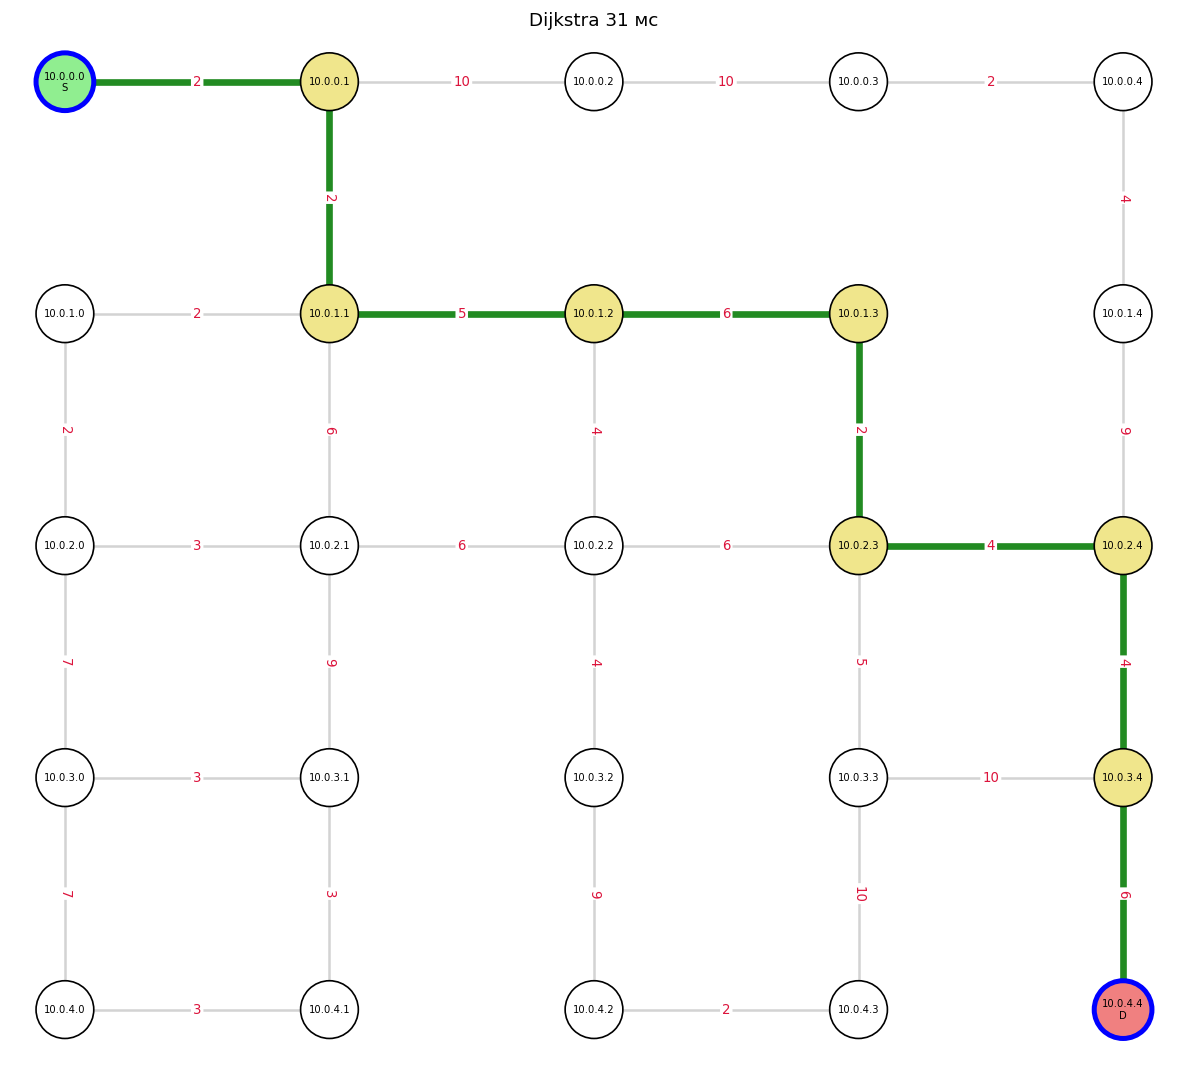

In [50]:
graph = sdn_env.generate_grid_graph()
opt_delay, opt_path = sdn_env.shortest_path_delay(graph, SOURCE, DESTINATION)
print(f'Вузлів={graph.number_of_nodes()}, ребер={graph.number_of_edges()}, оптимум={opt_delay} мс')
print(render_state_ascii(graph, opt_path, SOURCE, DESTINATION))
display(Image(filename='figures/topology.png'))

### 4.1. Код запуску частини 2 (Ollama)

Повний цикл NL → tool calling → відповідь моделі. `LIVE = False` показує збережені результати; `True` — реальний прогін.

In [51]:

LIVE = False  # True = реальний прогін через Ollama (довго на CPU)

SCENARIOS = [
    {"id": "s1_basic_path",
     "query": "Проклади шлях для потоку від вузла 10.0.0.0 до вузла 10.0.4.4"},
    {"id": "s2_avoid",
     "query": ("Проклади шлях до 10.0.4.4 в обхід вузлів 10.0.2.2 та 10.0.2.3, "
               "які виводяться на обслуговування. Відправник — 10.0.0.0.")},
    {"id": "s3_head_and_delays",
     "query": ("На якому вузлі зараз зупинилась побудова шляху і які канали з "
               "нього мають найменшу затримку?")},
    {"id": "s4_transfer",
     "query": ("Скільки триватиме передача останнього потоку і який канал є "
               "вузьким місцем?")},
    {"id": "s5_failure",
     "query": ("Канал між 10.0.1.1 та 10.0.1.2 вийшов з ладу – перебудуй шлях "
               "потоку від 10.0.0.0 до 10.0.4.4.")},
]

def run_part2_live(model=QUANTIZED_MODEL):
    graph = sdn_env.generate_grid_graph()
    opt_delay, opt_path = sdn_env.shortest_path_delay(graph, SOURCE, DESTINATION)
    results = {
        "topology": {
            "num_nodes": graph.number_of_nodes(),
            "num_edges": graph.number_of_edges(),
            "source": SOURCE,
            "destination": DESTINATION,
            "opt_delay": opt_delay,
            "opt_path": [sdn_env.node_address(n) for n in opt_path],
        },
        "model": model,
        "scenarios": [],
    }
    shared_env = None
    for sc in SCENARIOS:
        reuse = shared_env if sc["id"] in ("s3_head_and_delays", "s4_transfer") else None
        env = reuse or sdn_env.NetworkEnvironment(graph, SOURCE, DESTINATION)
        tb = SdnToolbox(env)
        agent = LlmController(model, tb, num_gpu=0, verbose=True)
        print("\n===", sc["id"], "===")
        res = agent.run(sc["query"])
        shared_env = env
        fig_dir = os.path.join("figures", f"part2_{sc['id']}")
        os.makedirs(os.path.join(fig_dir, "steps"), exist_ok=True)
        path = res.get("flow_state", {}).get("path") or []
        if path:
            plot_single_path(graph, path, SOURCE, DESTINATION,
                             title=sc["id"], filename=os.path.join(fig_dir, "final_path.png"))
        snaps = res.get("path_snapshots") or []
        if snaps:
            save_step_figures(graph, snaps, SOURCE, DESTINATION,
                              out_dir=os.path.join(fig_dir, "steps"), prefix="step")
        lpr = res.get("last_path_result") or {}
        results["scenarios"].append({
            "id": sc["id"], "query": sc["query"], "answer": res.get("answer"),
            "log": res.get("log"), "flow_state": res.get("flow_state"),
            "last_path_result": {k: v for k, v in lpr.items() if k != "snapshots"} or None,
            "path_snapshots": snaps, "transfer": res.get("transfer"),
            "steps": res.get("steps"), "tool_calls": res.get("tool_calls"),
            "llm_time_s": res.get("llm_time_s"),
        })
    with open("outputs/part2_scenarios.json", "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=2)
    print("Збережено outputs/part2_scenarios.json")
    return results

if LIVE:
    part2 = run_part2_live()
else:
    part2 = json.load(open("outputs/part2_scenarios.json", encoding="utf-8"))
    print("LIVE=False — завантажено збережені результати частини 2")
    print("Сценарії:", [s["id"] for s in part2["scenarios"]])


LIVE=False — завантажено збережені результати частини 2
Сценарії: ['s1_basic_path', 's2_avoid', 's3_head_and_delays', 's4_transfer', 's5_failure']


### 4.2. Результати сценаріїв (tools + графи + текст Qwen)

Нижче — повний розбір кожного сценарію для демонстрації.

In [52]:
import glob

def show_scenario(sc):
    print('=' * 78)
    print('СЦЕНАРІЙ:', sc.get('id'))
    print('=' * 78)
    print('ОПЕРАТОР:')
    print(sc.get('query') or '')
    tools = [e.get('tool') for e in (sc.get('log') or [])
             if e.get('tool') and not str(e.get('tool')).startswith('(')
             and e.get('status') != 'answer']
    print('\nІНСТРУМЕНТИ QWEN:')
    for i, t in enumerate(dict.fromkeys(tools), 1):
        print(f'  {i}. {t}')
    for entry in sc.get('log') or []:
        tool = entry.get('tool') or ''
        status = entry.get('status') or ''
        if status == 'answer' or tool == '(відповідь)':
            print('-' * 78)
            print('ВІДПОВІДЬ МОДЕЛІ (текст):')
            print(entry.get('result') or sc.get('answer') or '')
            continue
        if tool.startswith('('):
            continue
        print('-' * 78)
        print('ВИКЛИК ІНСТРУМЕНТА:', tool)
        print('Аргументи:', json.dumps(entry.get('arguments') or {}, ensure_ascii=False))
        print('Статус:', status)
        raw = entry.get('result') or ''
        try:
            print('Результат:', json.dumps(json.loads(raw), ensure_ascii=False, indent=2))
        except Exception:
            print('Результат:', raw)
    sid = sc.get('id')
    for p in sorted(glob.glob(f'figures/part2_{sid}/steps/step_*.png')):
        print('ГРАФ:', p)
        display(Image(filename=p))
    fp = f'figures/part2_{sid}/final_path.png'
    if os.path.exists(fp):
        print('ФІНАЛЬНИЙ ШЛЯХ:', fp)
        display(Image(filename=fp))

print('Функція show_scenario(sc) готова')

Функція show_scenario(sc) готова


#### Сценарій `s1_basic_path`

СЦЕНАРІЙ: s1_basic_path
ОПЕРАТОР:
Проклади шлях для потоку від вузла 10.0.0.0 до вузла 10.0.4.4

ІНСТРУМЕНТИ QWEN:
  1. install_path
------------------------------------------------------------------------------
ВИКЛИК ІНСТРУМЕНТА: install_path
Аргументи: {"src": "10.0.0.0", "dst": "10.0.4.4"}
Статус: ok
Результат: {
  "path": [
    "10.0.0.0",
    "10.0.0.1",
    "10.0.1.1",
    "10.0.1.2",
    "10.0.1.3",
    "10.0.2.3",
    "10.0.2.4",
    "10.0.3.4",
    "10.0.4.4"
  ],
  "delay_ms": 31,
  "transmission_ms": 2500.0,
  "total_ms": 2531.0,
  "bottleneck": "10.0.1.3 — 10.0.2.3",
  "min_bandwidth_MBps": 400,
  "links": [
    "10.0.0.0-10.0.0.1:2ms/800MBps",
    "10.0.0.1-10.0.1.1:2ms/600MBps",
    "10.0.1.1-10.0.1.2:5ms/900MBps",
    "10.0.1.2-10.0.1.3:6ms/700MBps",
    "10.0.1.3-10.0.2.3:2ms/400MBps",
    "10.0.2.3-10.0.2.4:4ms/700MBps",
    "10.0.2.4-10.0.3.4:4ms/900MBps",
    "10.0.3.4-10.0.4.4:6ms/500MBps"
  ],
  "avoid": [],
  "installed_rules": 8,
  "optimal_delay_ms": 31,
  "opt

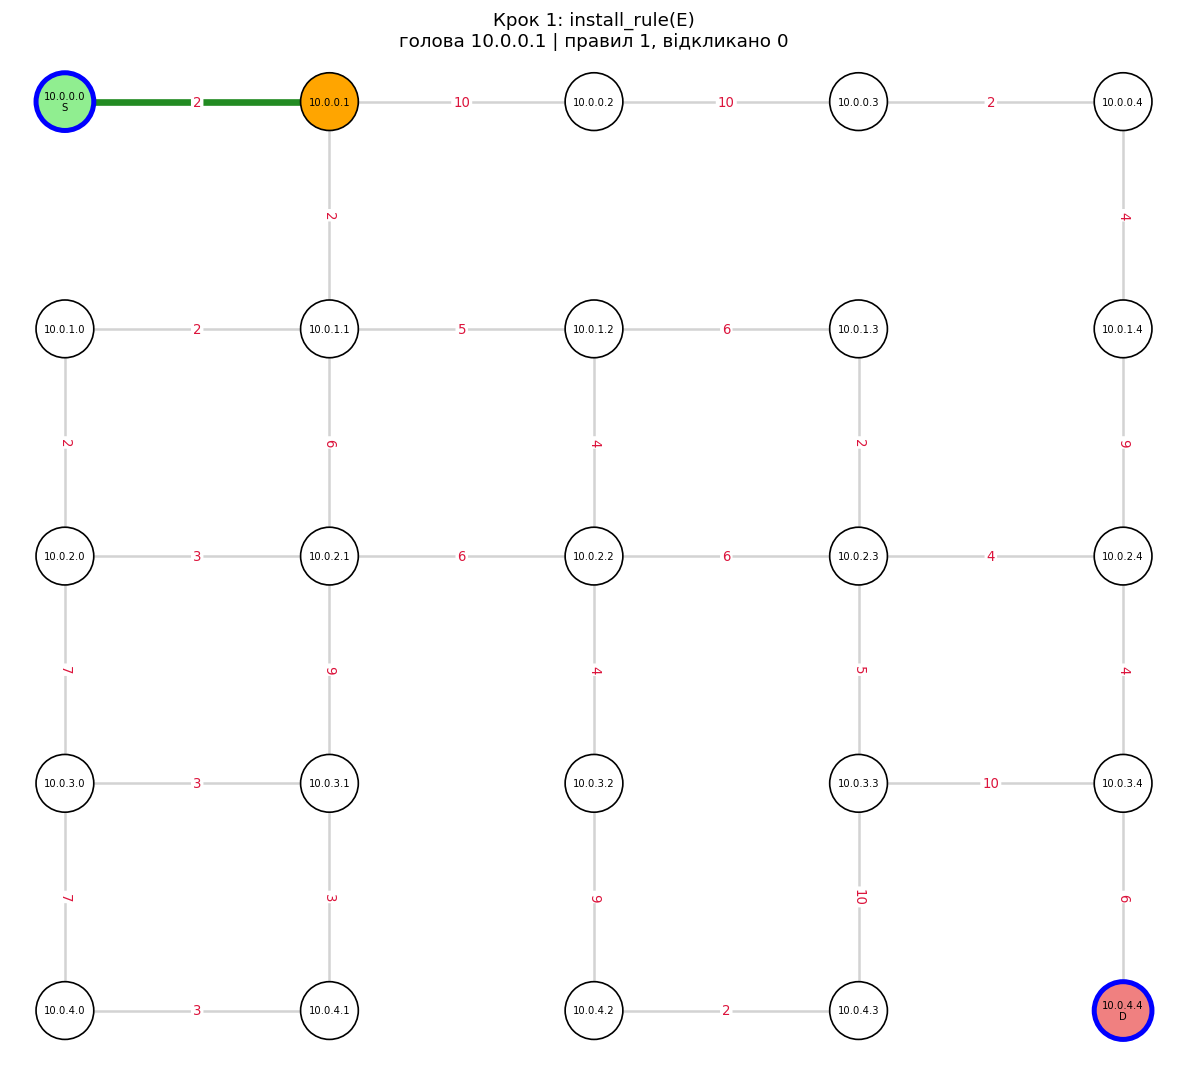

ГРАФ: figures/part2_s1_basic_path/steps\step_02.png


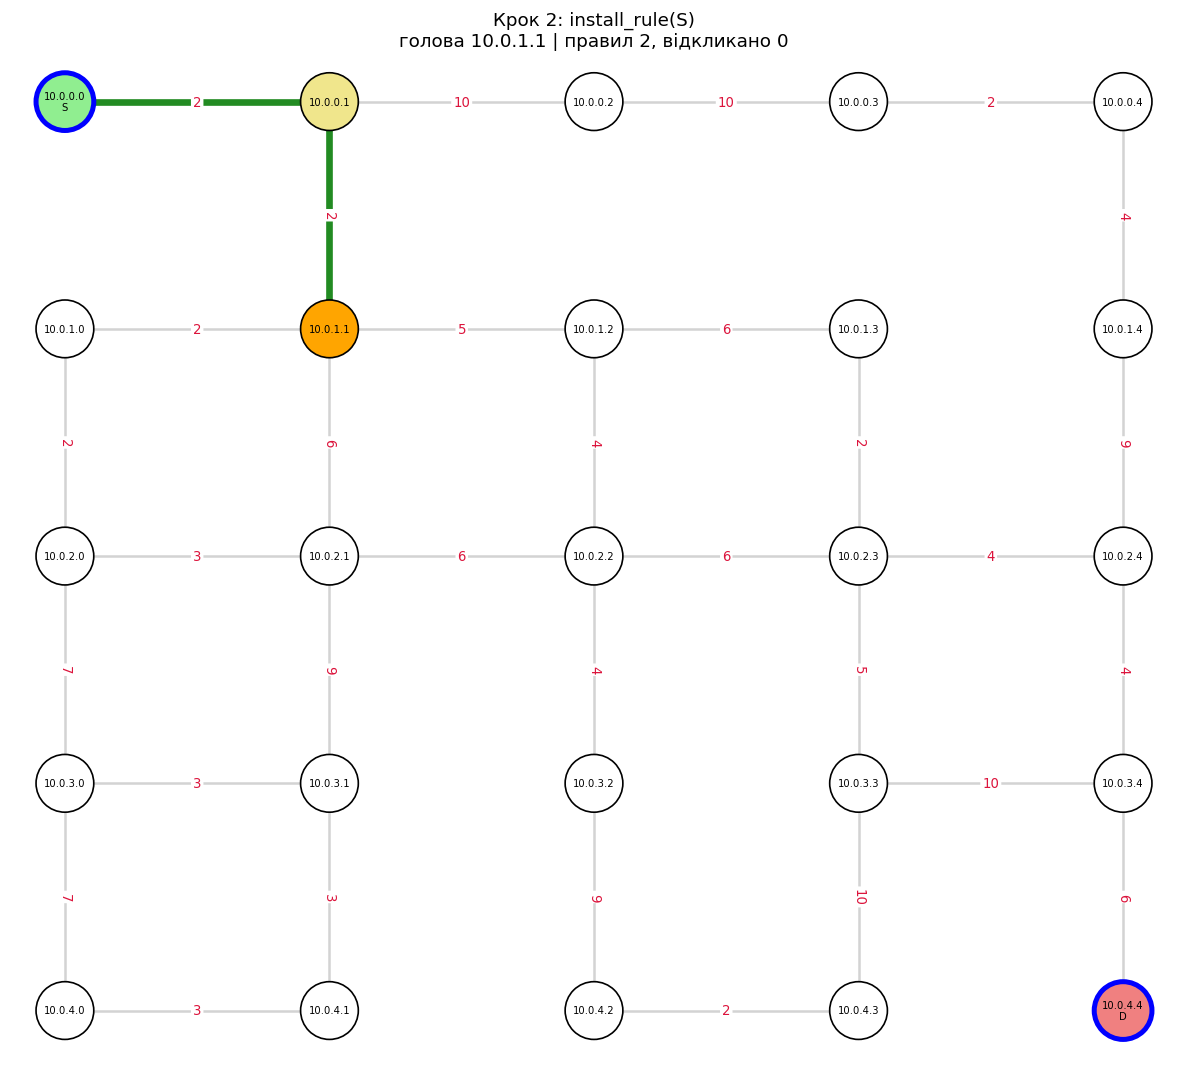

ГРАФ: figures/part2_s1_basic_path/steps\step_03.png


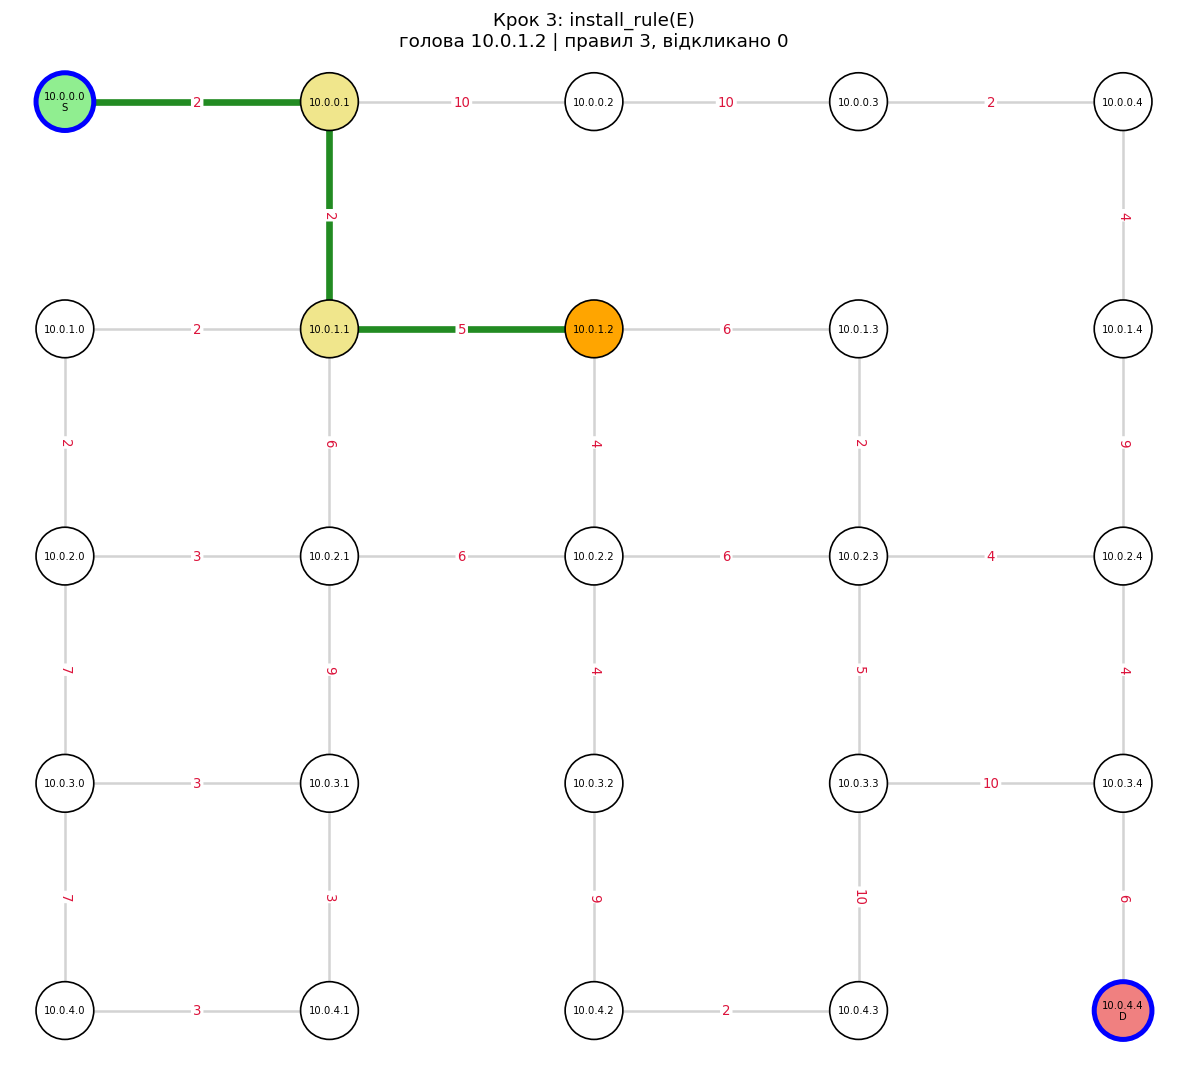

ГРАФ: figures/part2_s1_basic_path/steps\step_04.png


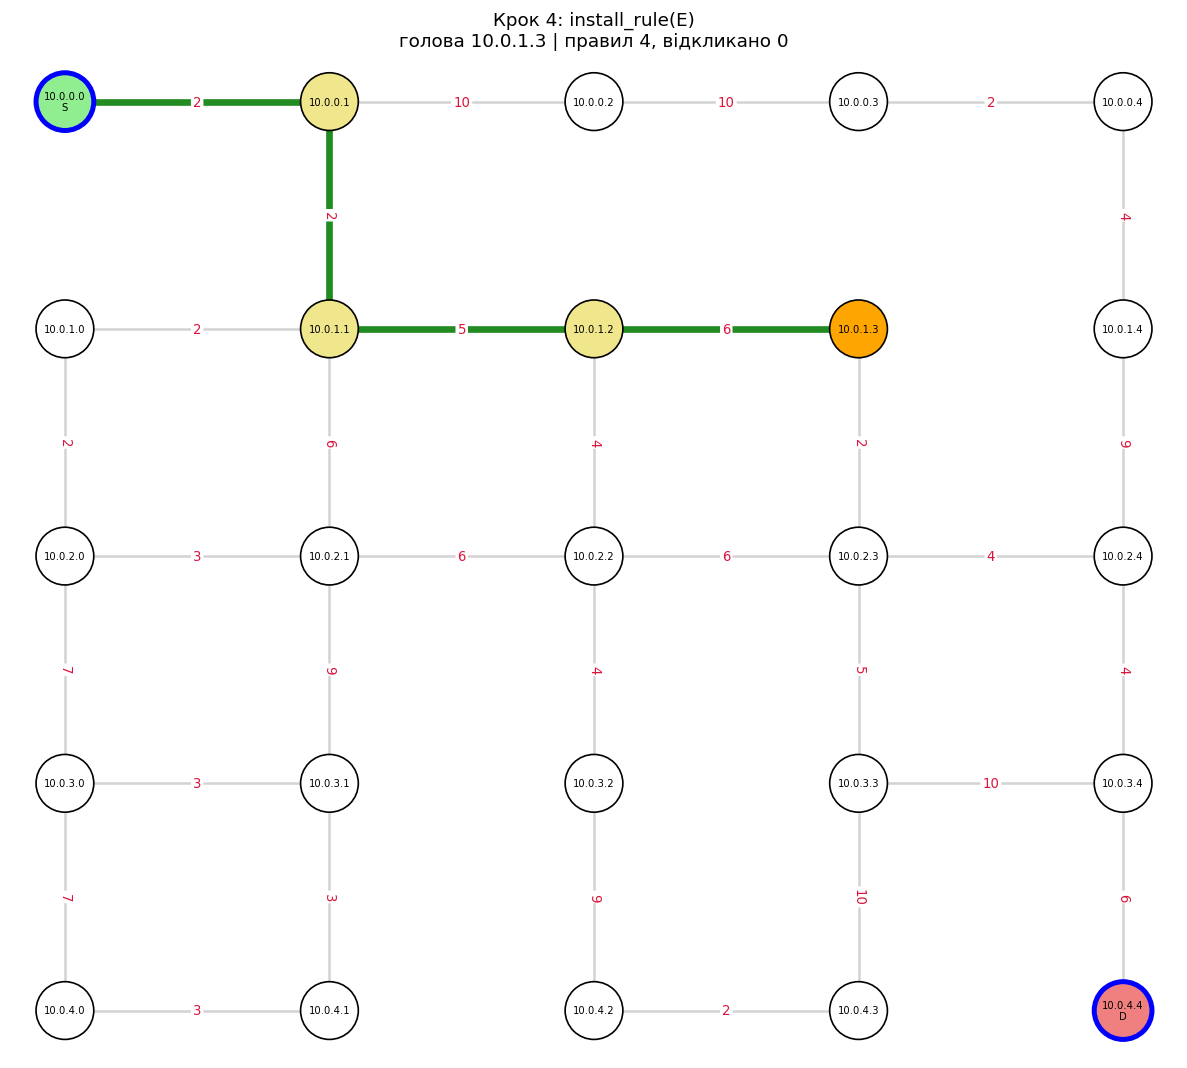

ГРАФ: figures/part2_s1_basic_path/steps\step_05.png


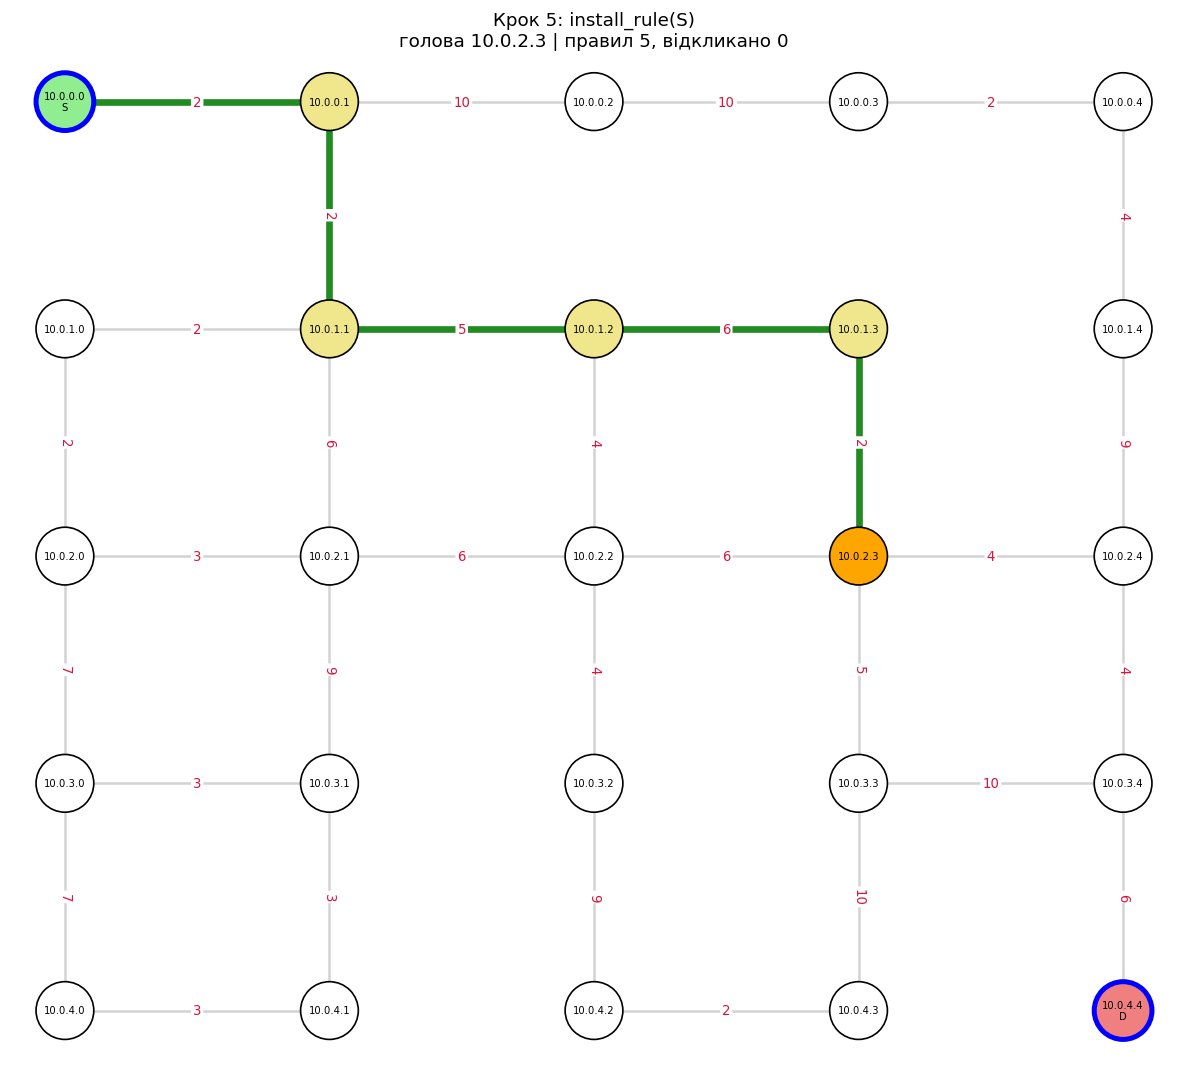

ГРАФ: figures/part2_s1_basic_path/steps\step_06.png


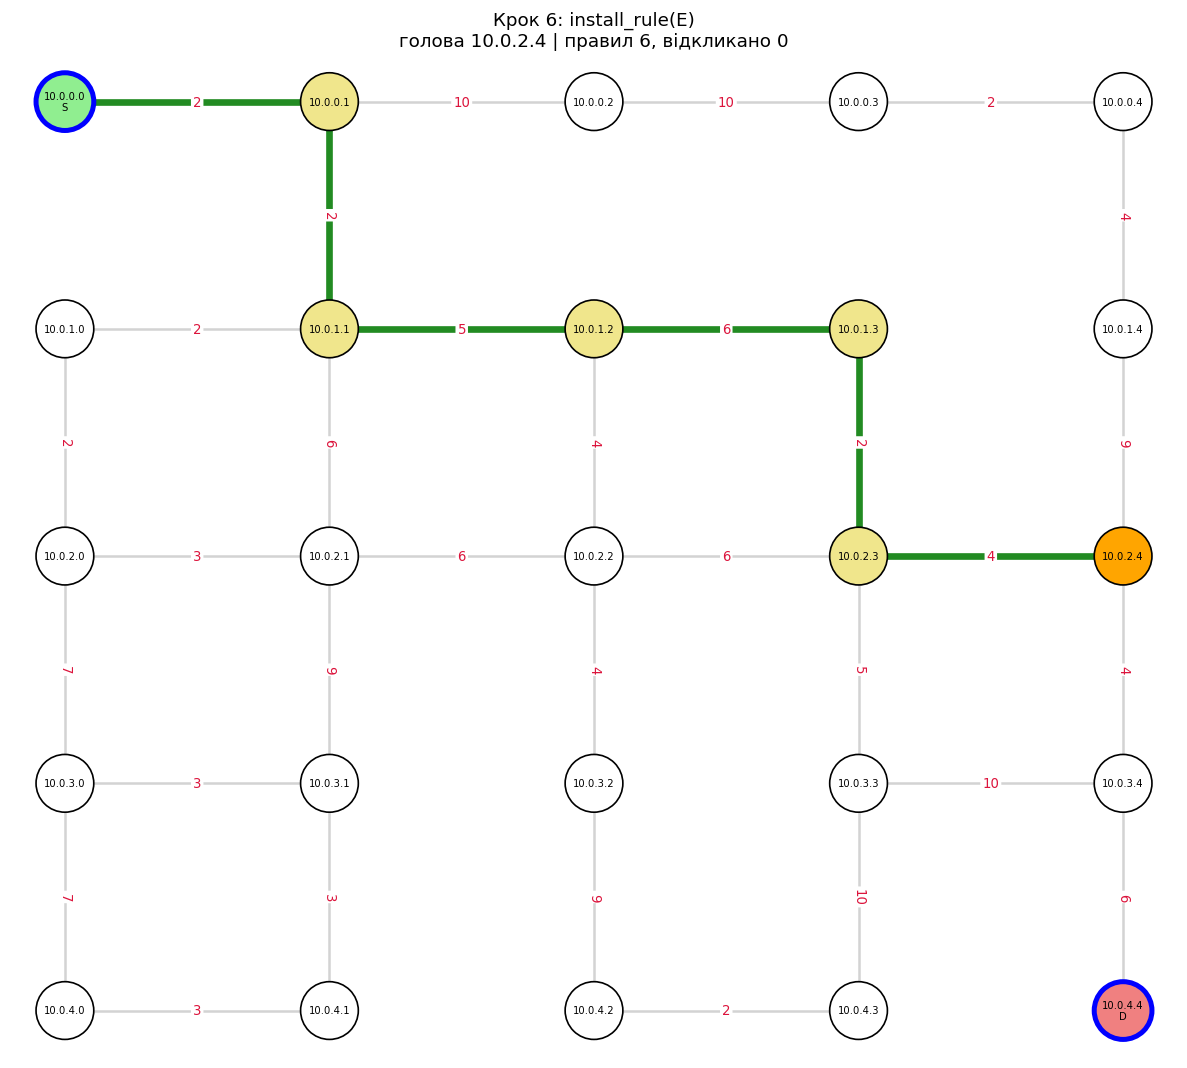

ГРАФ: figures/part2_s1_basic_path/steps\step_07.png


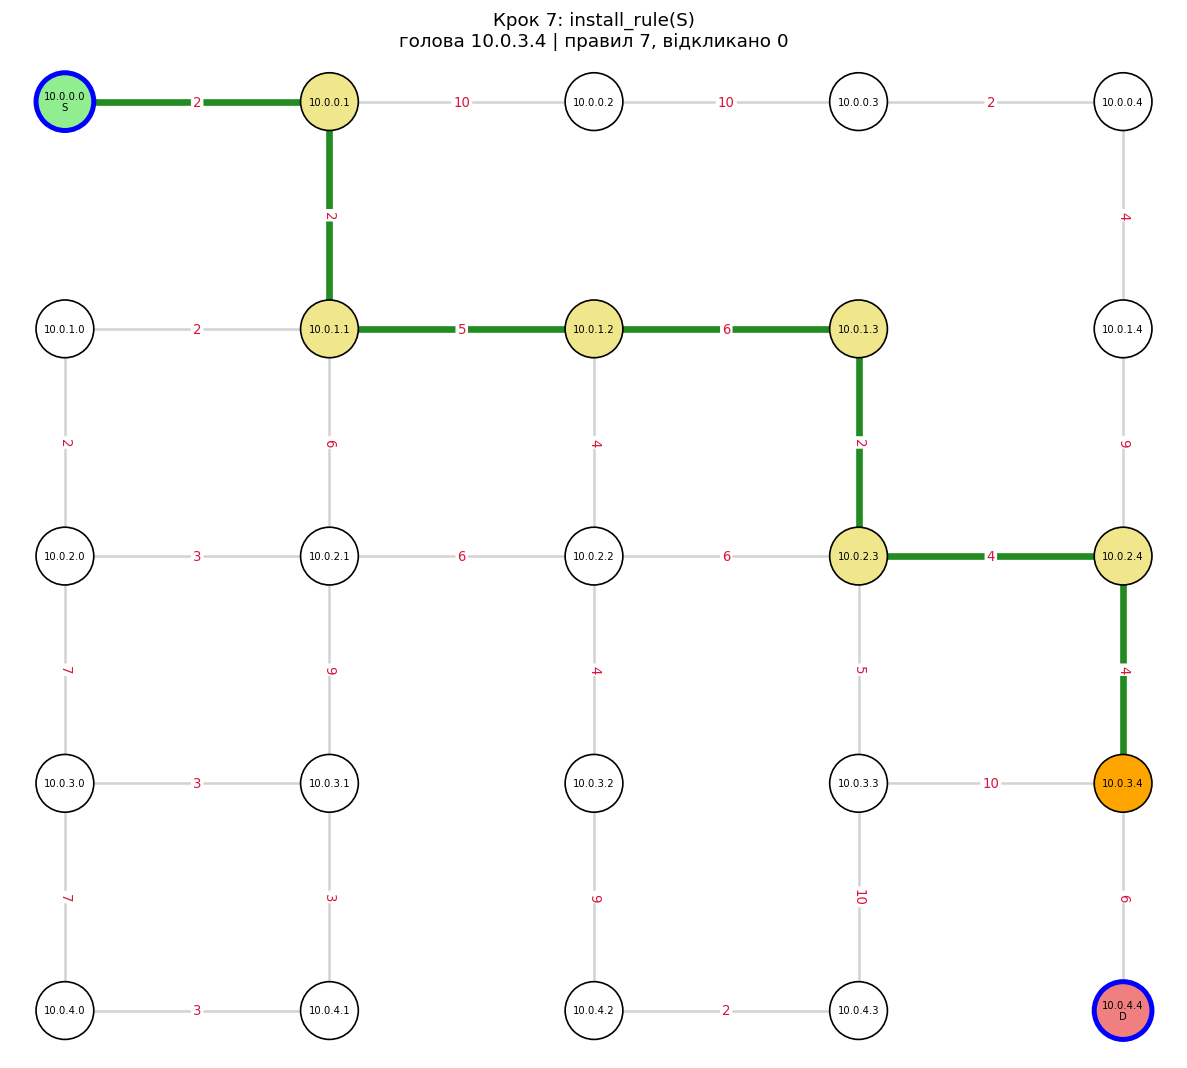

ГРАФ: figures/part2_s1_basic_path/steps\step_08.png


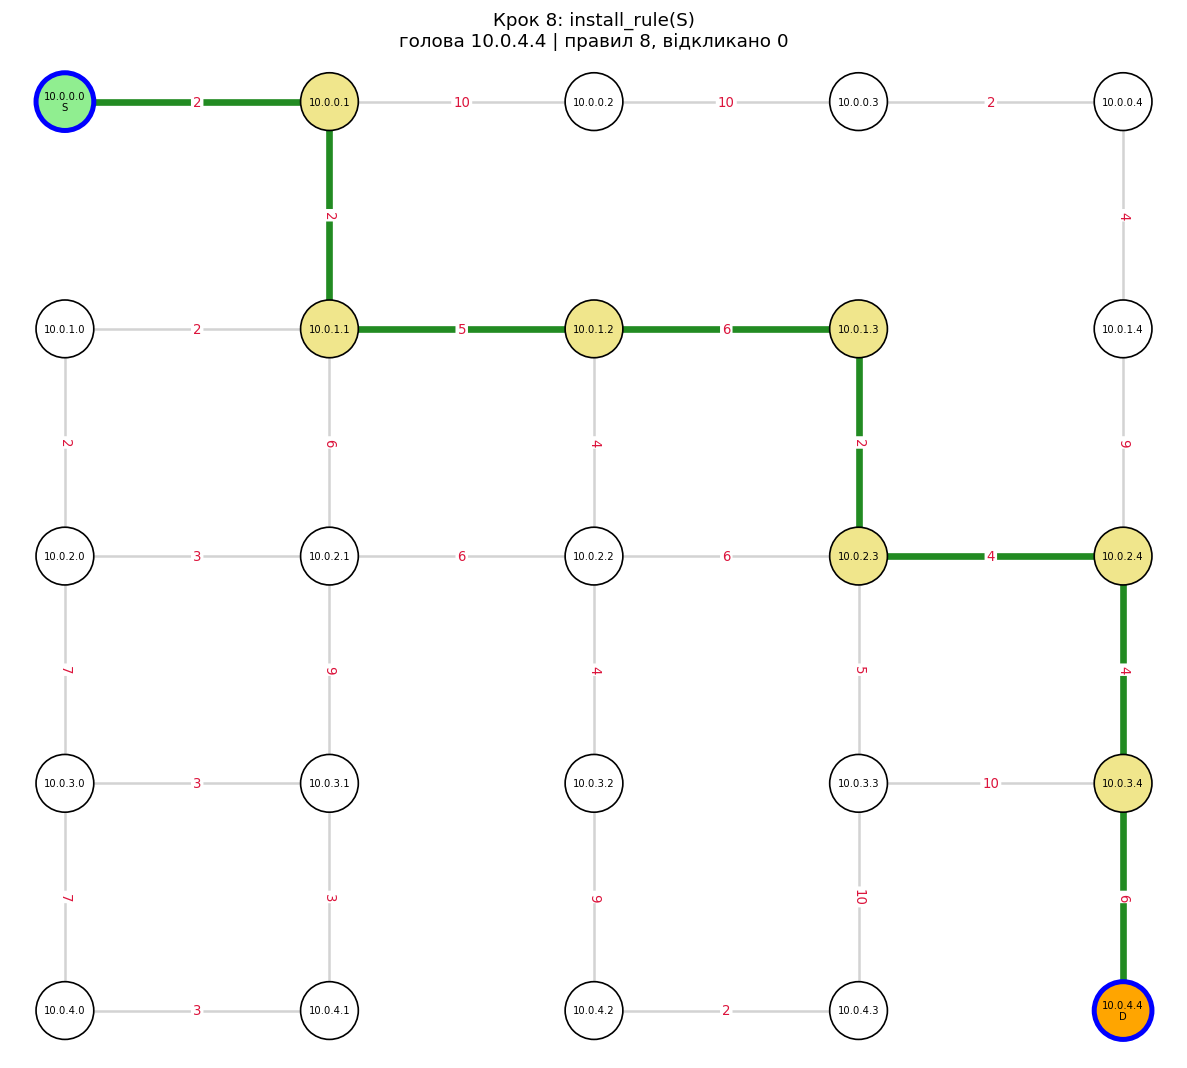

ФІНАЛЬНИЙ ШЛЯХ: figures/part2_s1_basic_path/final_path.png


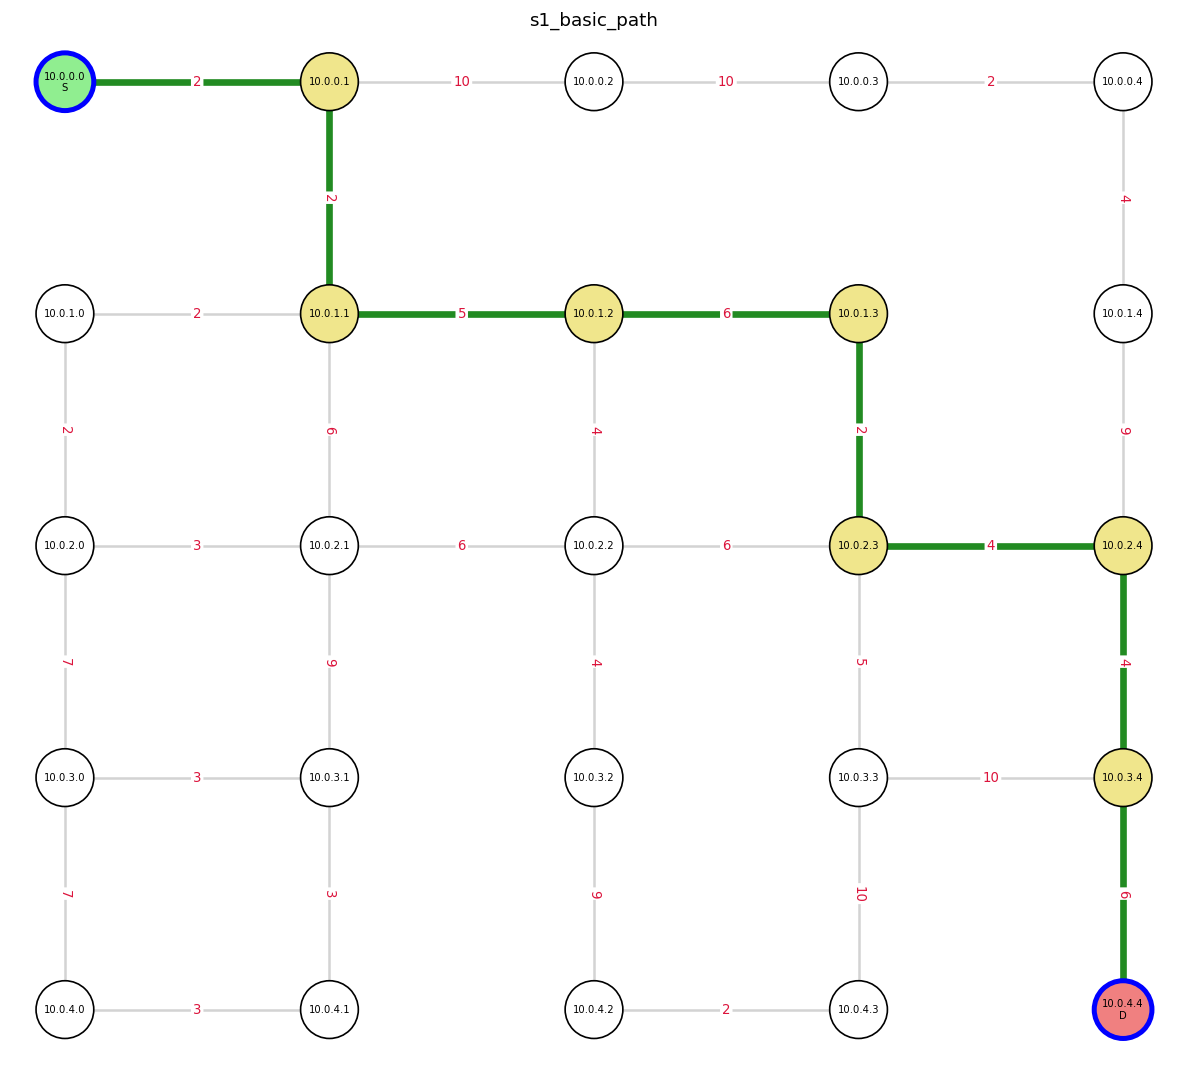

In [53]:
show_scenario(next(s for s in part2['scenarios'] if s['id'] == 's1_basic_path'))

#### Сценарій `s2_avoid`

СЦЕНАРІЙ: s2_avoid
ОПЕРАТОР:
Проклади шлях до 10.0.4.4 в обхід вузлів 10.0.2.2 та 10.0.2.3, які виводяться на обслуговування. Відправник — 10.0.0.0.

ІНСТРУМЕНТИ QWEN:
  1. install_path
------------------------------------------------------------------------------
ВИКЛИК ІНСТРУМЕНТА: install_path
Аргументи: {"src": "10.0.0.0", "dst": "10.0.4.4", "avoid": ["10.0.2.2", "10.0.2.3"]}
Статус: ok
Результат: {
  "path": [
    "10.0.0.0",
    "10.0.0.1",
    "10.0.0.2",
    "10.0.0.3",
    "10.0.0.4",
    "10.0.1.4",
    "10.0.2.4",
    "10.0.3.4",
    "10.0.4.4"
  ],
  "delay_ms": 47,
  "transmission_ms": 5000.0,
  "total_ms": 5047.0,
  "bottleneck": "10.0.0.3 — 10.0.0.4",
  "min_bandwidth_MBps": 200,
  "links": [
    "10.0.0.0-10.0.0.1:2ms/800MBps",
    "10.0.0.1-10.0.0.2:10ms/700MBps",
    "10.0.0.2-10.0.0.3:10ms/500MBps",
    "10.0.0.3-10.0.0.4:2ms/200MBps",
    "10.0.0.4-10.0.1.4:4ms/600MBps",
    "10.0.1.4-10.0.2.4:9ms/500MBps",
    "10.0.2.4-10.0.3.4:4ms/900MBps",
    "10.0.3.4-10.0.4.4

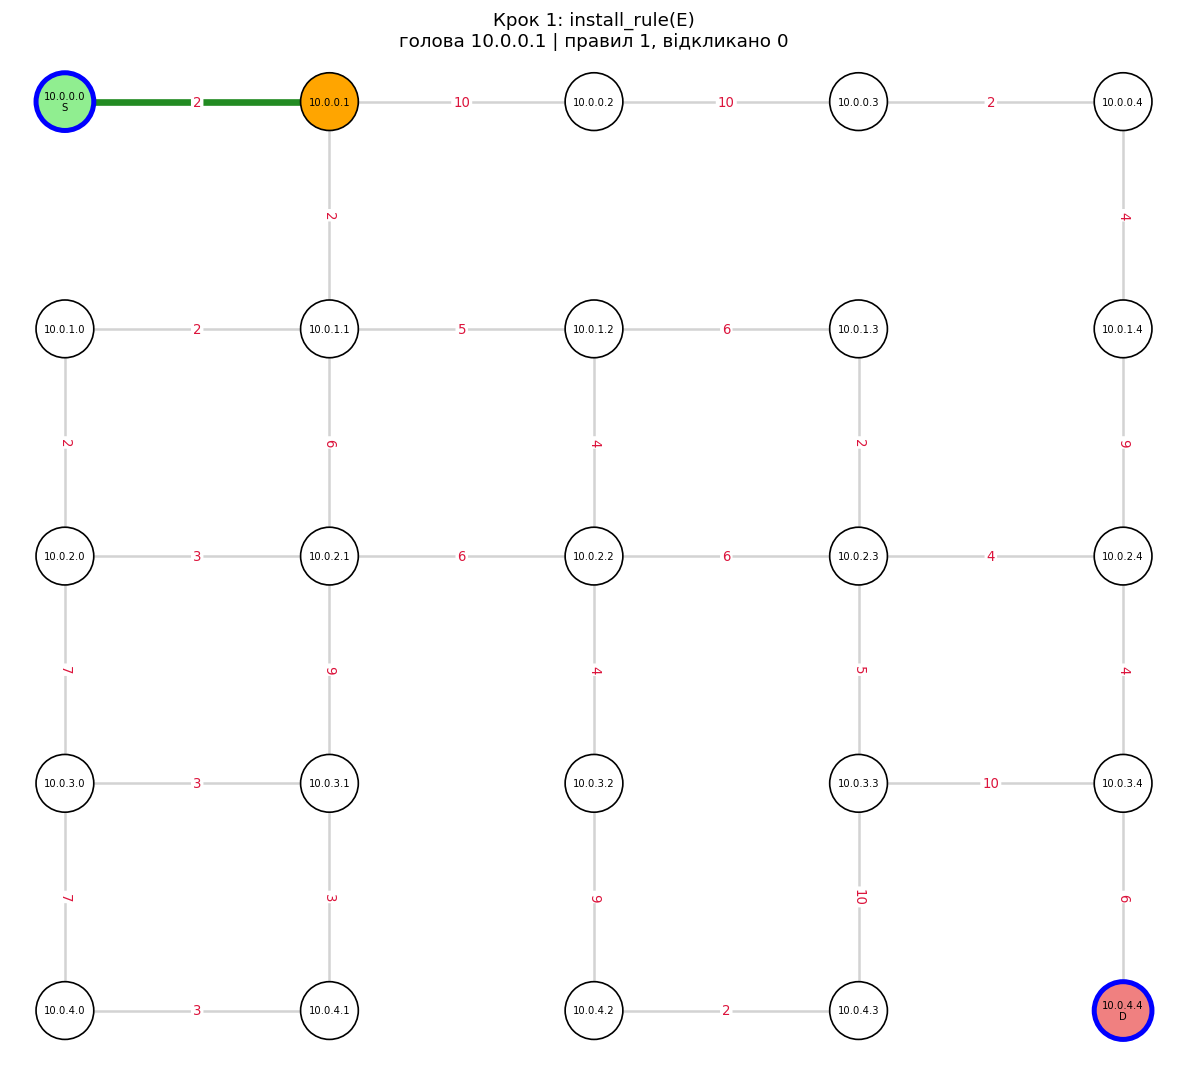

ГРАФ: figures/part2_s2_avoid/steps\step_02.png


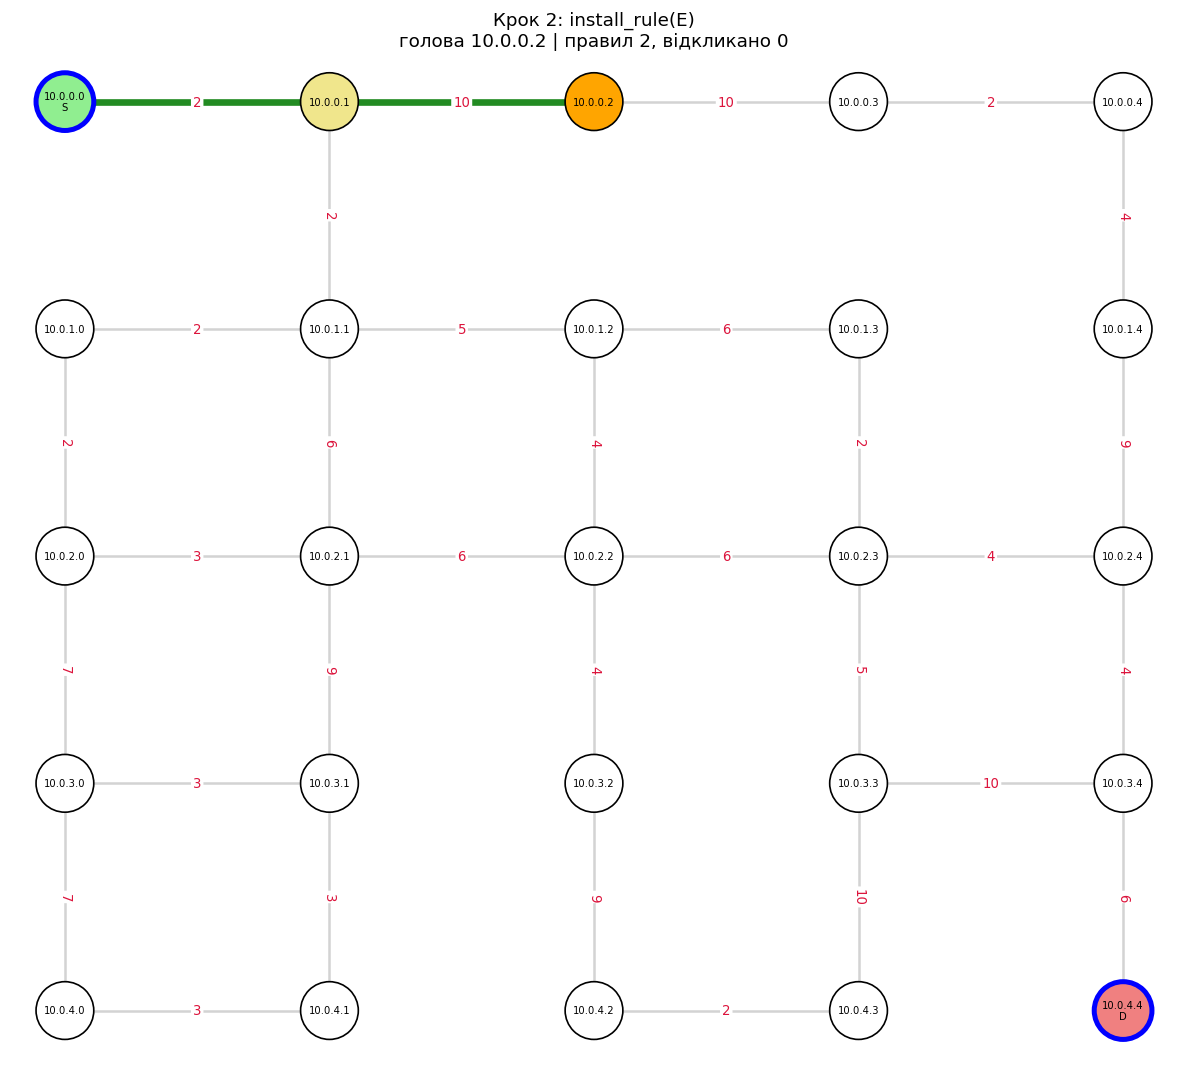

ГРАФ: figures/part2_s2_avoid/steps\step_03.png


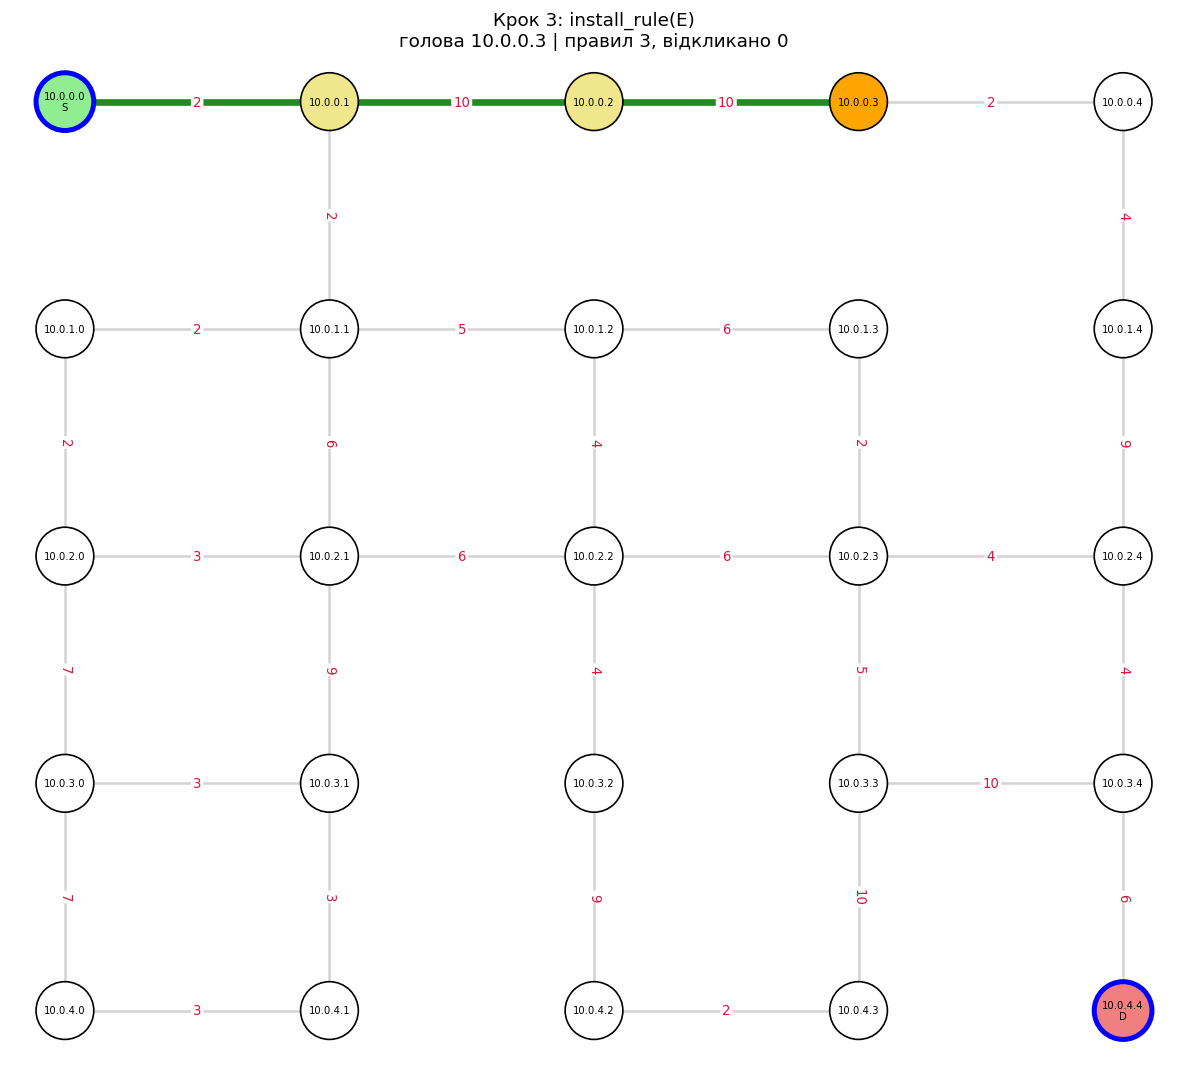

ГРАФ: figures/part2_s2_avoid/steps\step_04.png


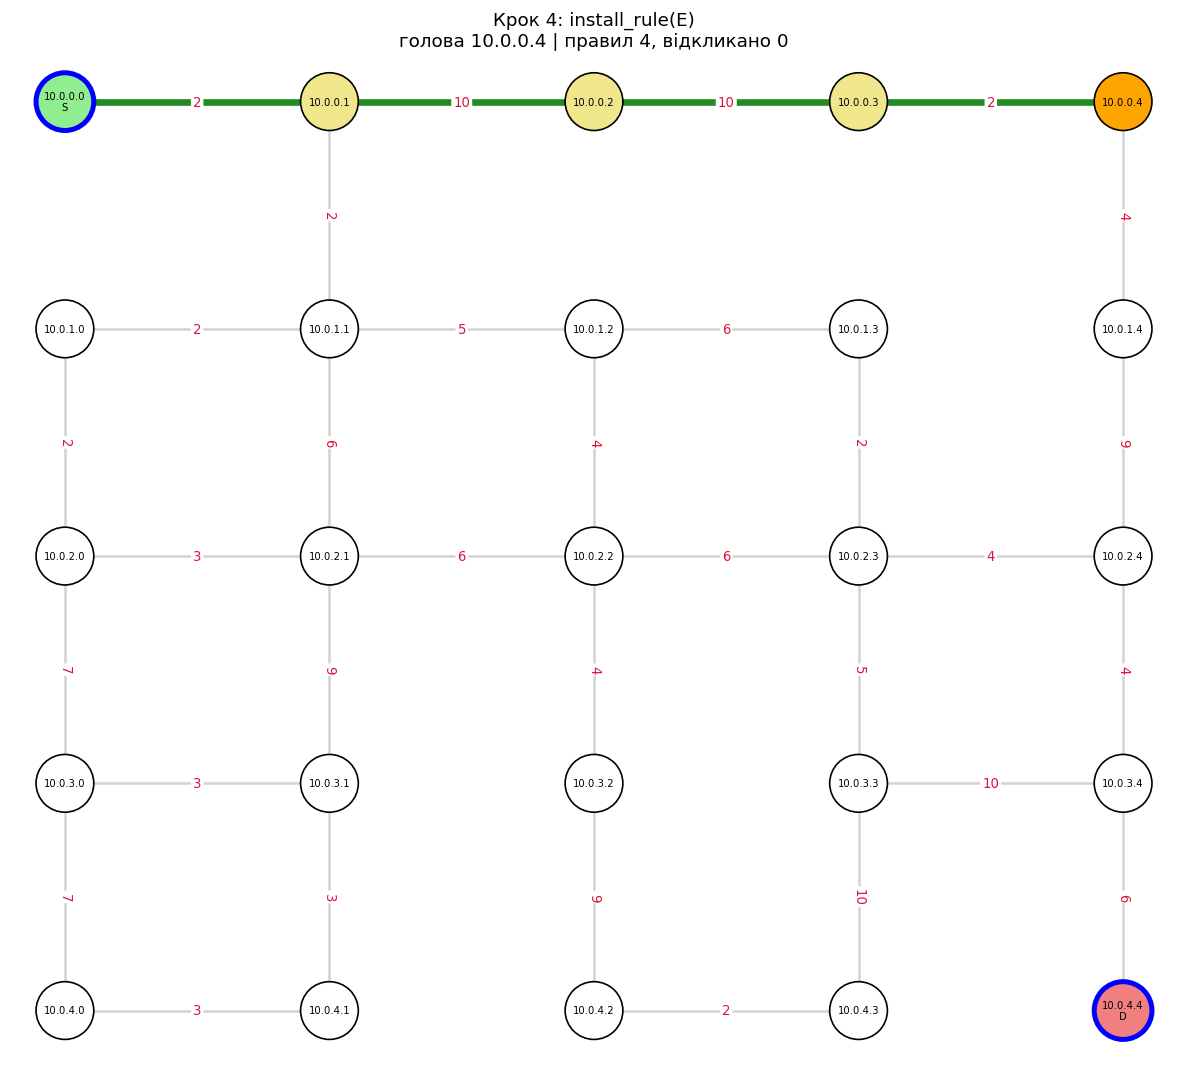

ГРАФ: figures/part2_s2_avoid/steps\step_05.png


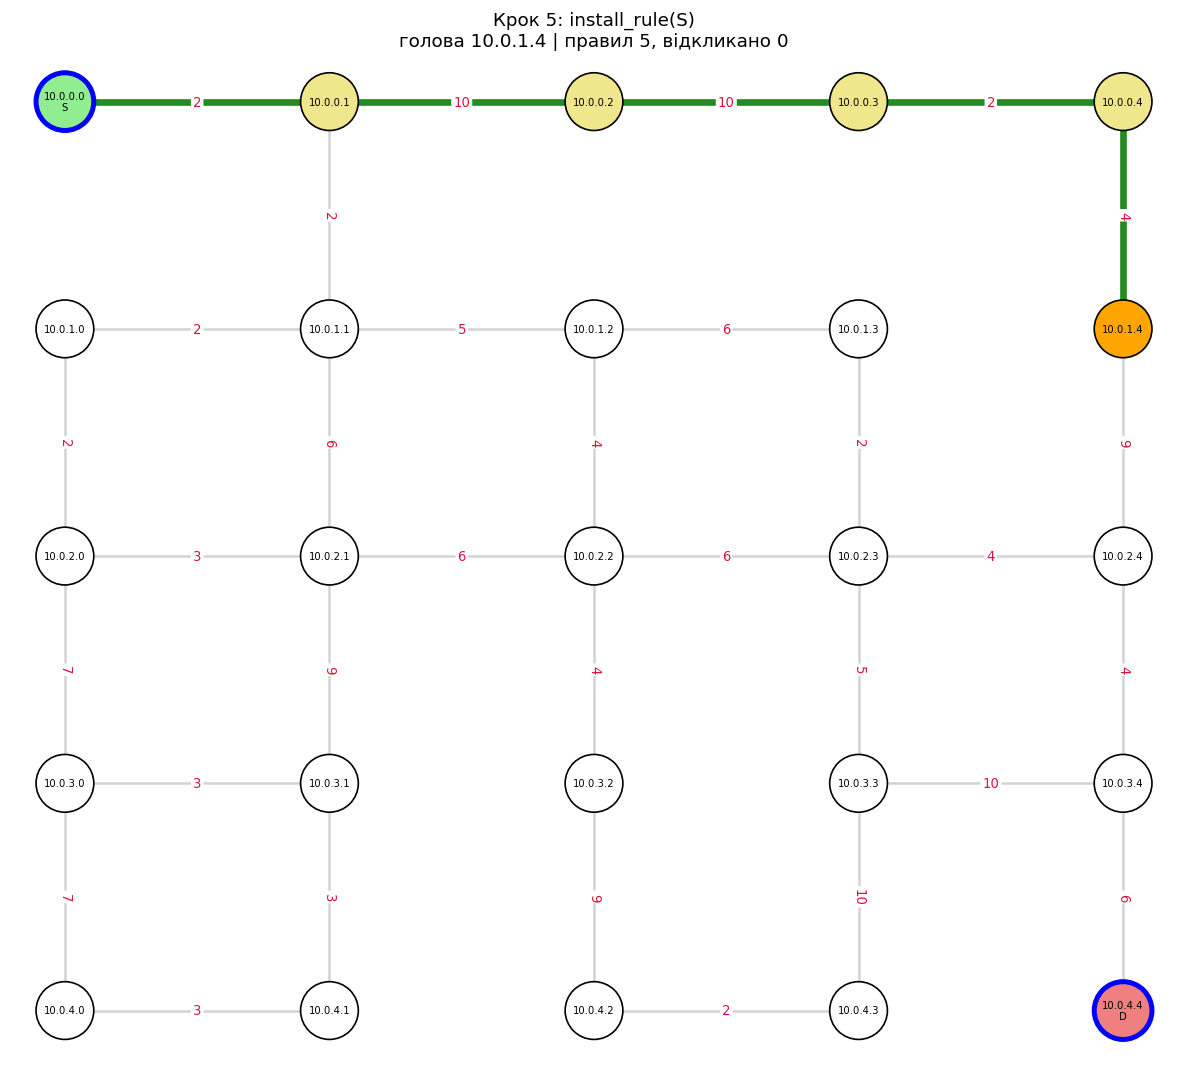

ГРАФ: figures/part2_s2_avoid/steps\step_06.png


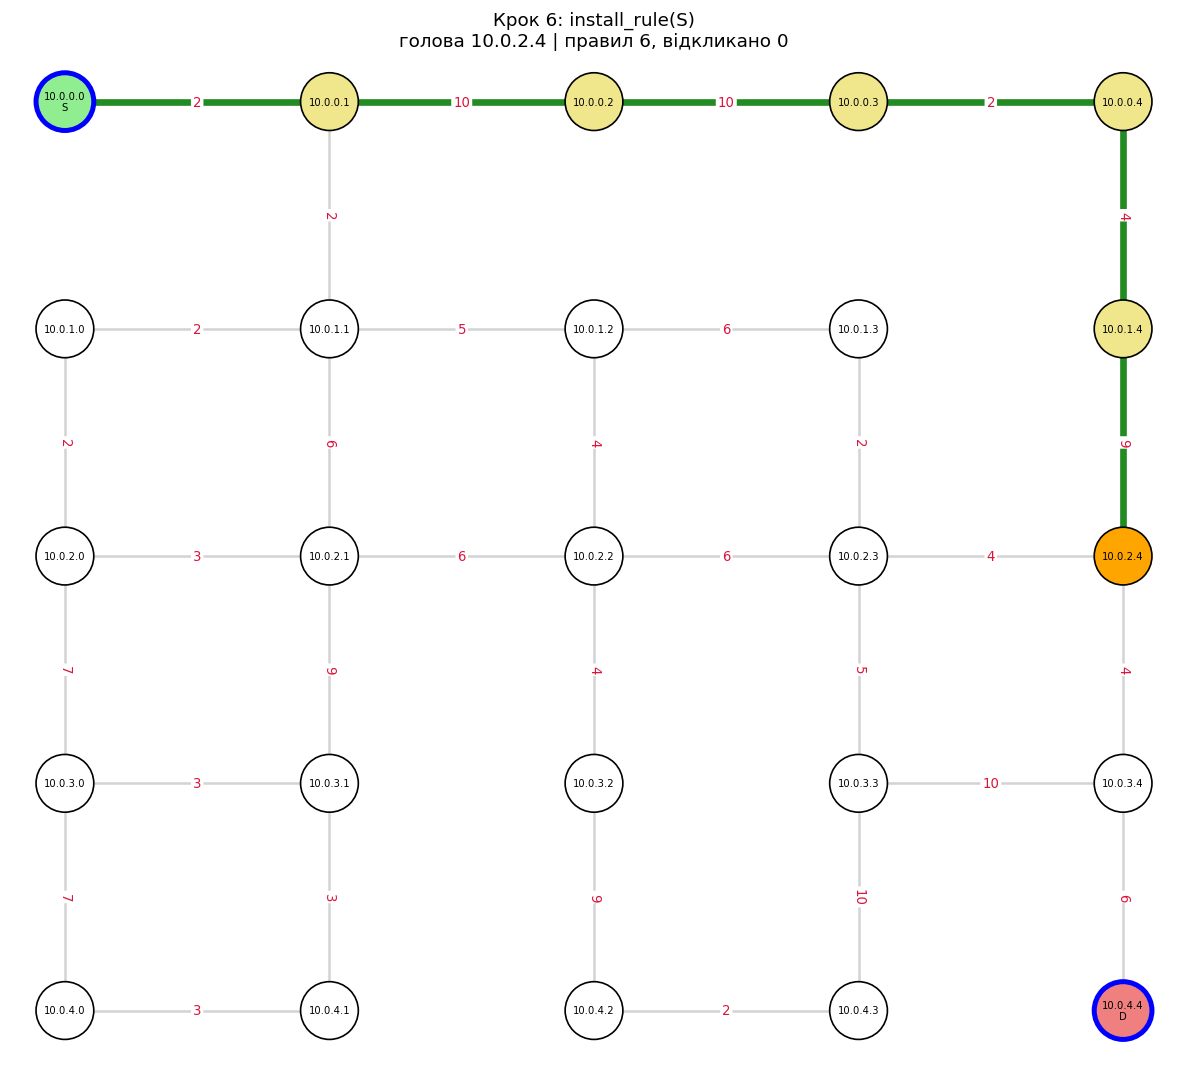

ГРАФ: figures/part2_s2_avoid/steps\step_07.png


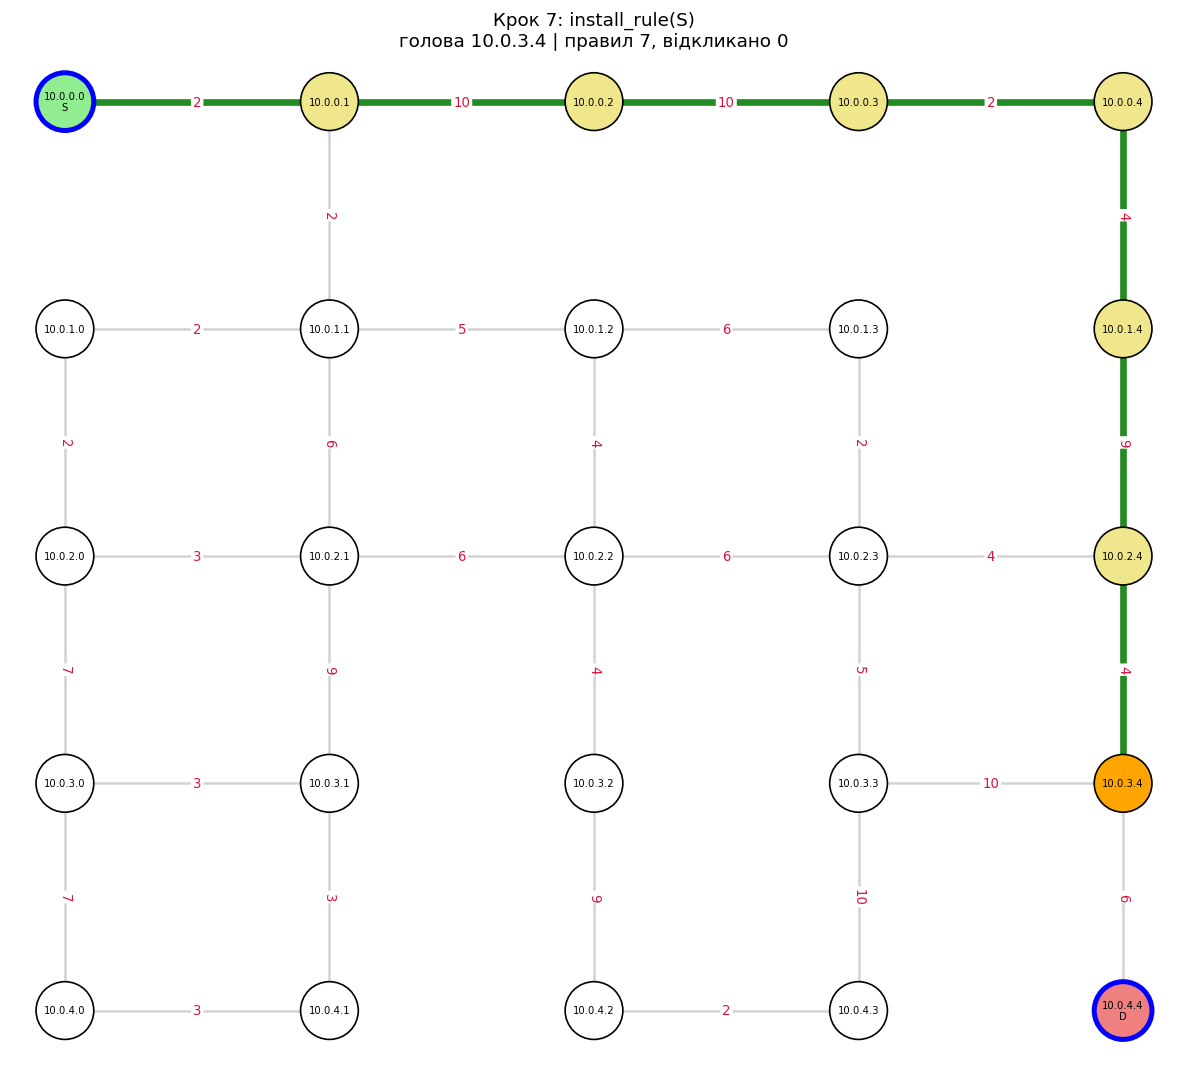

ГРАФ: figures/part2_s2_avoid/steps\step_08.png


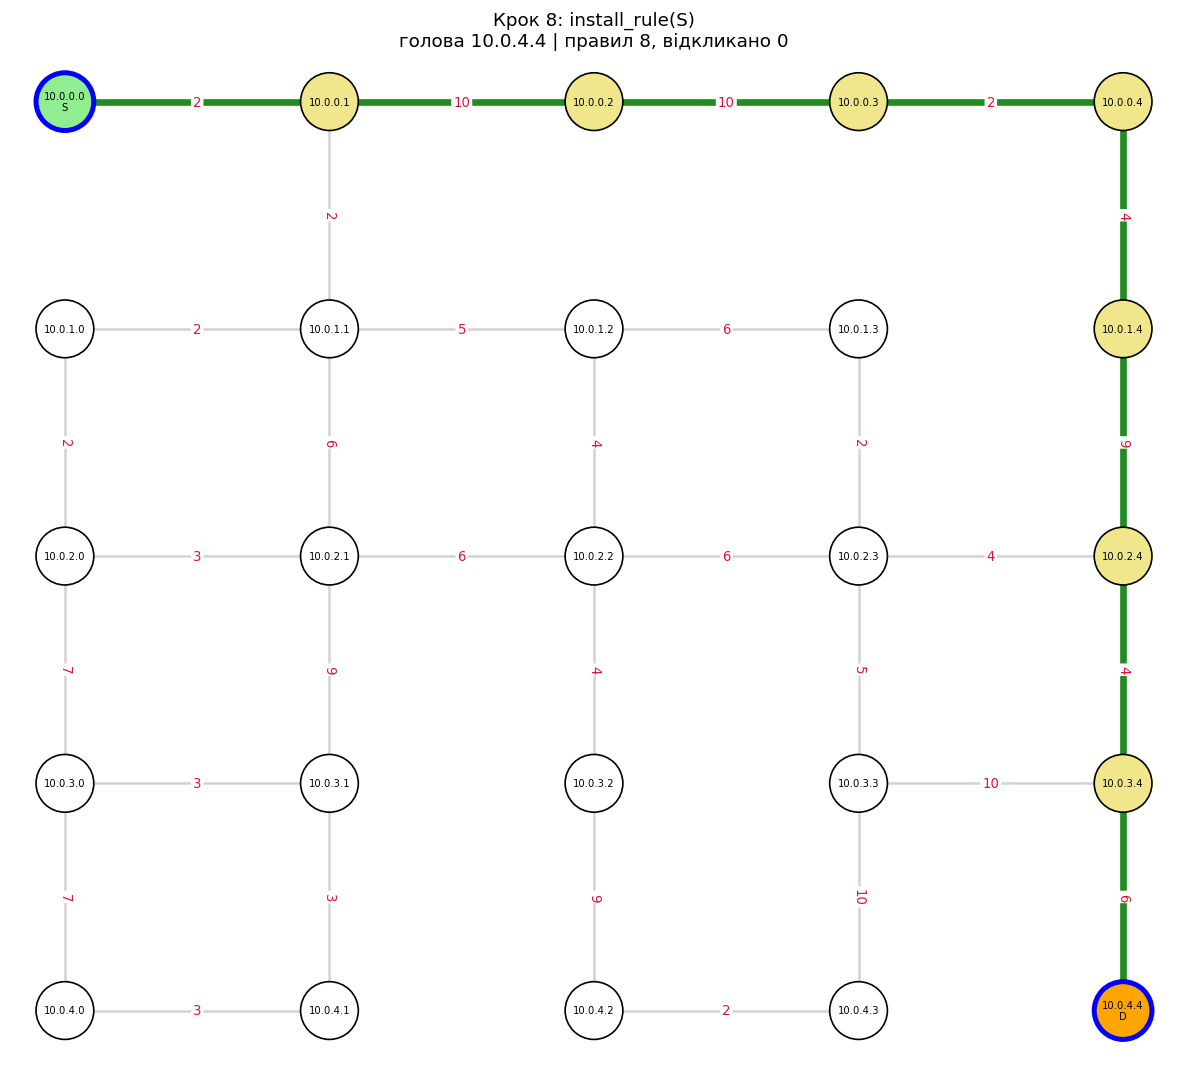

ФІНАЛЬНИЙ ШЛЯХ: figures/part2_s2_avoid/final_path.png


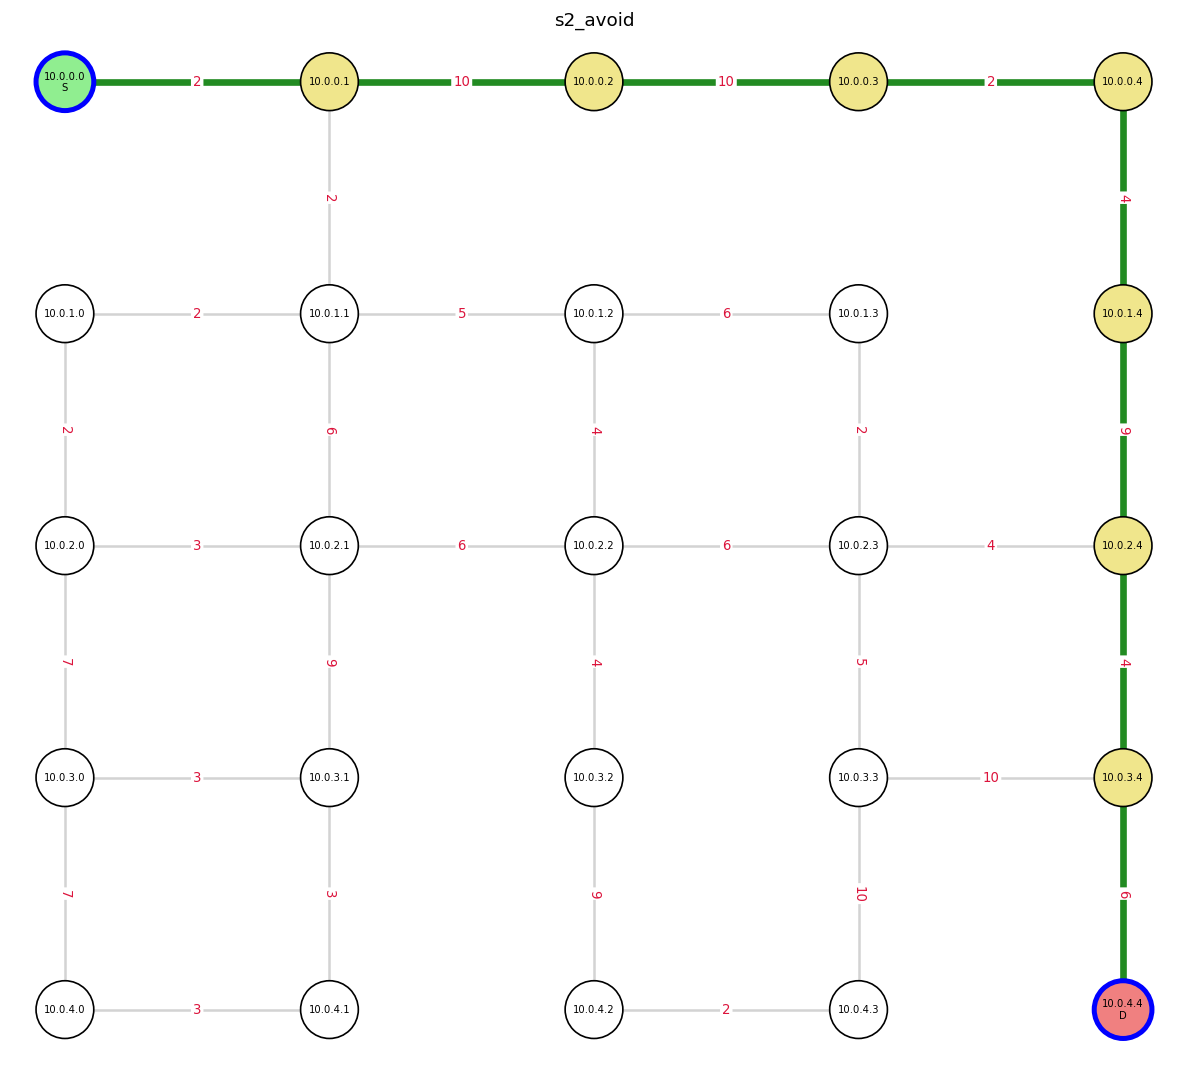

In [54]:
show_scenario(next(s for s in part2['scenarios'] if s['id'] == 's2_avoid'))

#### Сценарій `s3_head_and_delays`

СЦЕНАРІЙ: s3_head_and_delays
ОПЕРАТОР:
На якому вузлі зараз зупинилась побудова шляху і які канали з нього мають найменшу затримку?

ІНСТРУМЕНТИ QWEN:
  1. get_flow_state
------------------------------------------------------------------------------
ВИКЛИК ІНСТРУМЕНТА: get_flow_state
Аргументи: {}
Статус: ok
Результат: {
  "head": "10.0.4.4",
  "destination": "10.0.4.4",
  "source": "10.0.0.0",
  "path": [
    "10.0.0.0",
    "10.0.0.1",
    "10.0.0.2",
    "10.0.0.3",
    "10.0.0.4",
    "10.0.1.4",
    "10.0.2.4",
    "10.0.3.4",
    "10.0.4.4"
  ],
  "rules": [
    {
      "node": "10.0.0.0",
      "interface": "E",
      "next": "10.0.0.1"
    },
    {
      "node": "10.0.0.1",
      "interface": "E",
      "next": "10.0.0.2"
    },
    {
      "node": "10.0.0.2",
      "interface": "E",
      "next": "10.0.0.3"
    },
    {
      "node": "10.0.0.3",
      "interface": "E",
      "next": "10.0.0.4"
    },
    {
      "node": "10.0.0.4",
      "interface": "S",
      "next": "10.0.1

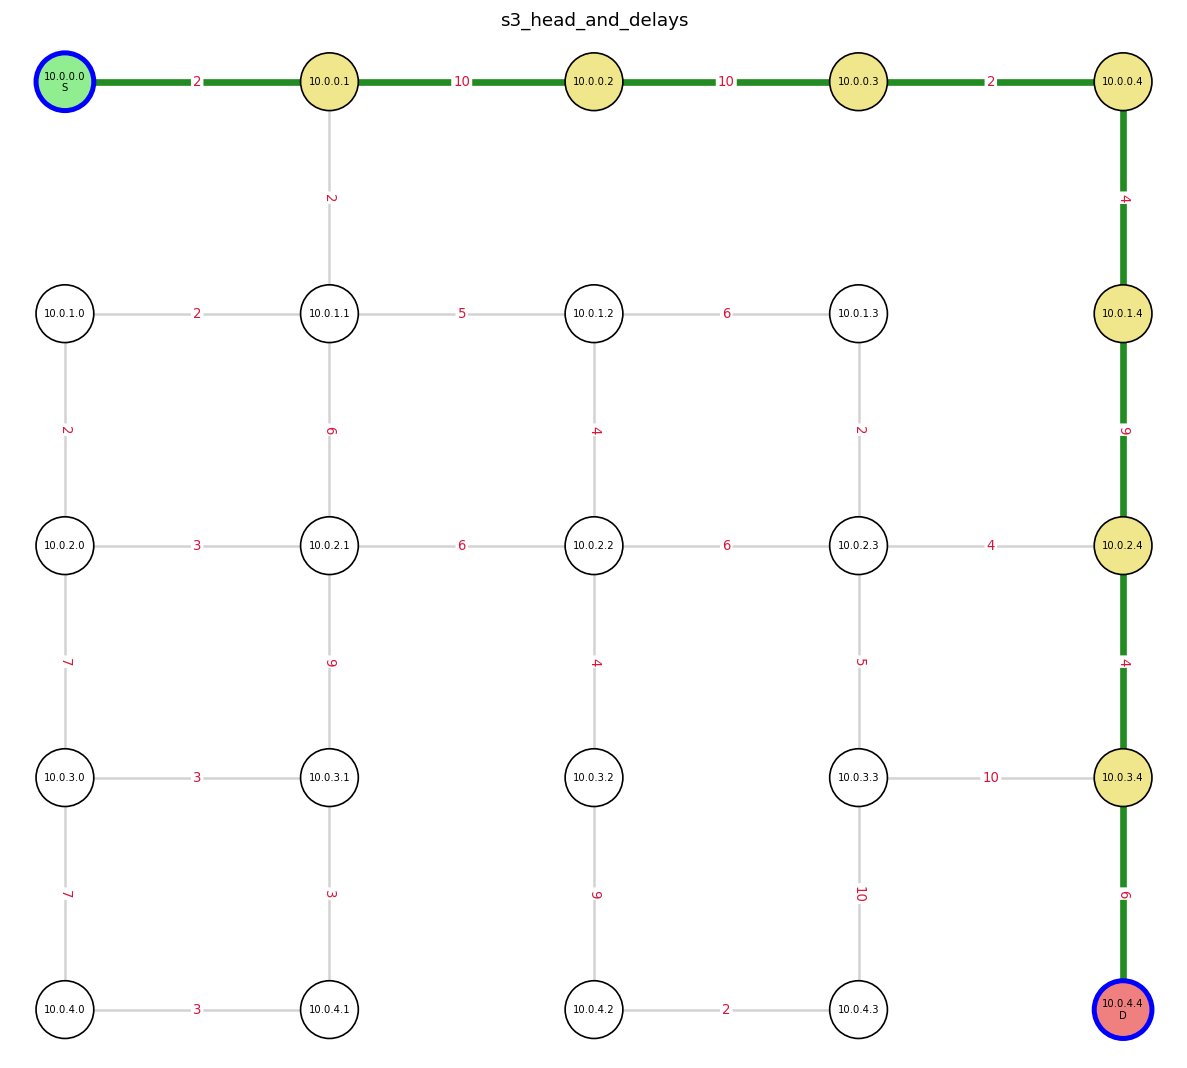

In [55]:
show_scenario(next(s for s in part2['scenarios'] if s['id'] == 's3_head_and_delays'))

#### Сценарій `s4_transfer`

СЦЕНАРІЙ: s4_transfer
ОПЕРАТОР:
Скільки триватиме передача останнього потоку і який канал є вузьким місцем?

ІНСТРУМЕНТИ QWEN:
  1. get_flow_state
------------------------------------------------------------------------------
ВИКЛИК ІНСТРУМЕНТА: get_flow_state
Аргументи: {}
Статус: ok
Результат: {
  "head": "10.0.4.4",
  "destination": "10.0.4.4",
  "source": "10.0.0.0",
  "path": [
    "10.0.0.0",
    "10.0.0.1",
    "10.0.0.2",
    "10.0.0.3",
    "10.0.0.4",
    "10.0.1.4",
    "10.0.2.4",
    "10.0.3.4",
    "10.0.4.4"
  ],
  "rules": [
    {
      "node": "10.0.0.0",
      "interface": "E",
      "next": "10.0.0.1"
    },
    {
      "node": "10.0.0.1",
      "interface": "E",
      "next": "10.0.0.2"
    },
    {
      "node": "10.0.0.2",
      "interface": "E",
      "next": "10.0.0.3"
    },
    {
      "node": "10.0.0.3",
      "interface": "E",
      "next": "10.0.0.4"
    },
    {
      "node": "10.0.0.4",
      "interface": "S",
      "next": "10.0.1.4"
    },
    {
      "

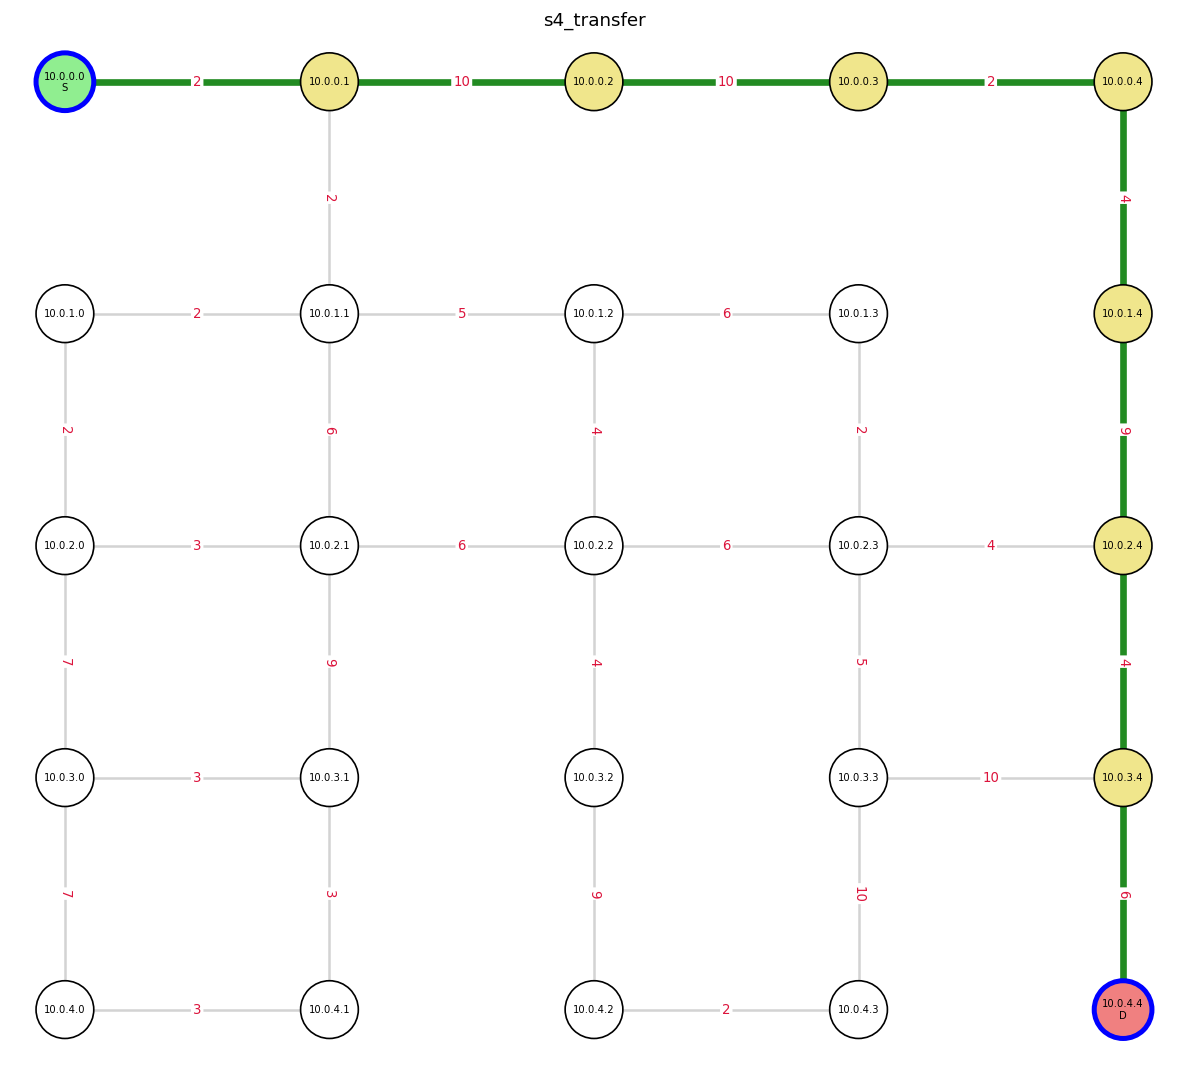

In [56]:
show_scenario(next(s for s in part2['scenarios'] if s['id'] == 's4_transfer'))

#### Сценарій `s5_failure`

СЦЕНАРІЙ: s5_failure
ОПЕРАТОР:
Канал між 10.0.1.1 та 10.0.1.2 вийшов з ладу – перебудуй шлях потоку від 10.0.0.0 до 10.0.4.4.

ІНСТРУМЕНТИ QWEN:
  1. simulate_link_failure
  2. install_path
------------------------------------------------------------------------------
ВИКЛИК ІНСТРУМЕНТА: simulate_link_failure
Аргументи: {"a": "10.0.1.1", "b": "10.0.1.2"}
Статус: ok
Результат: {
  "failed_link": "10.0.1.1 — 10.0.1.2",
  "previous_delay_ms": 5,
  "status": "down",
  "failed_channels": [
    "10.0.1.1 — 10.0.1.2"
  ],
  "num_channels_known": 31
}
------------------------------------------------------------------------------
ВИКЛИК ІНСТРУМЕНТА: install_path
Аргументи: {"src": "10.0.0.0", "dst": "10.0.4.4"}
Статус: ok
Результат: {
  "path": [
    "10.0.0.0",
    "10.0.0.1",
    "10.0.1.1",
    "10.0.2.1",
    "10.0.2.2",
    "10.0.2.3",
    "10.0.2.4",
    "10.0.3.4",
    "10.0.4.4"
  ],
  "delay_ms": 36,
  "transmission_ms": 5000.0,
  "total_ms": 5036.0,
  "bottleneck": "10.0.2.1 — 10.0.2.

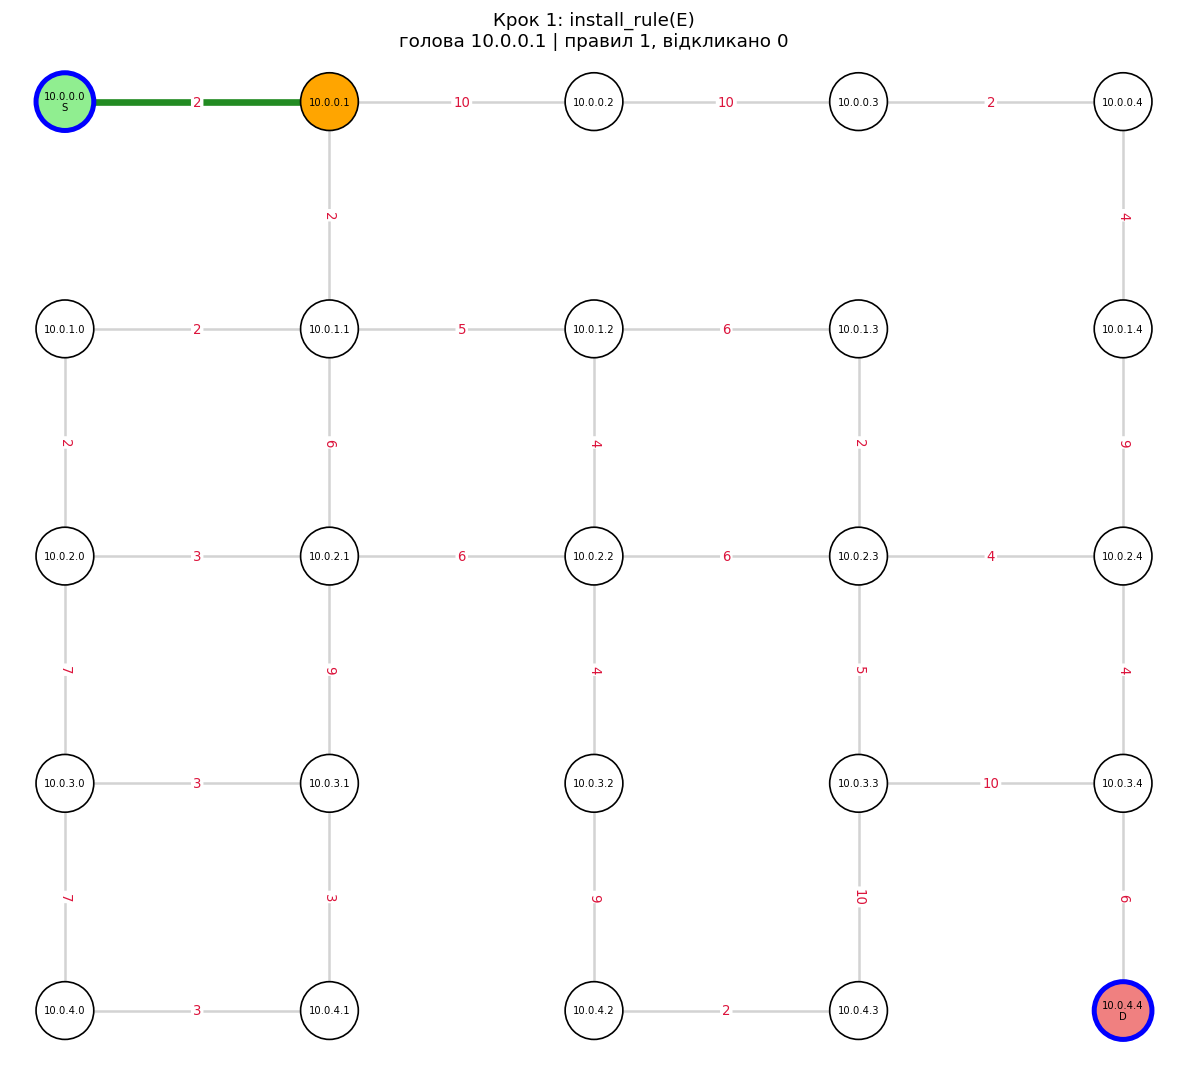

ГРАФ: figures/part2_s5_failure/steps\step_02.png


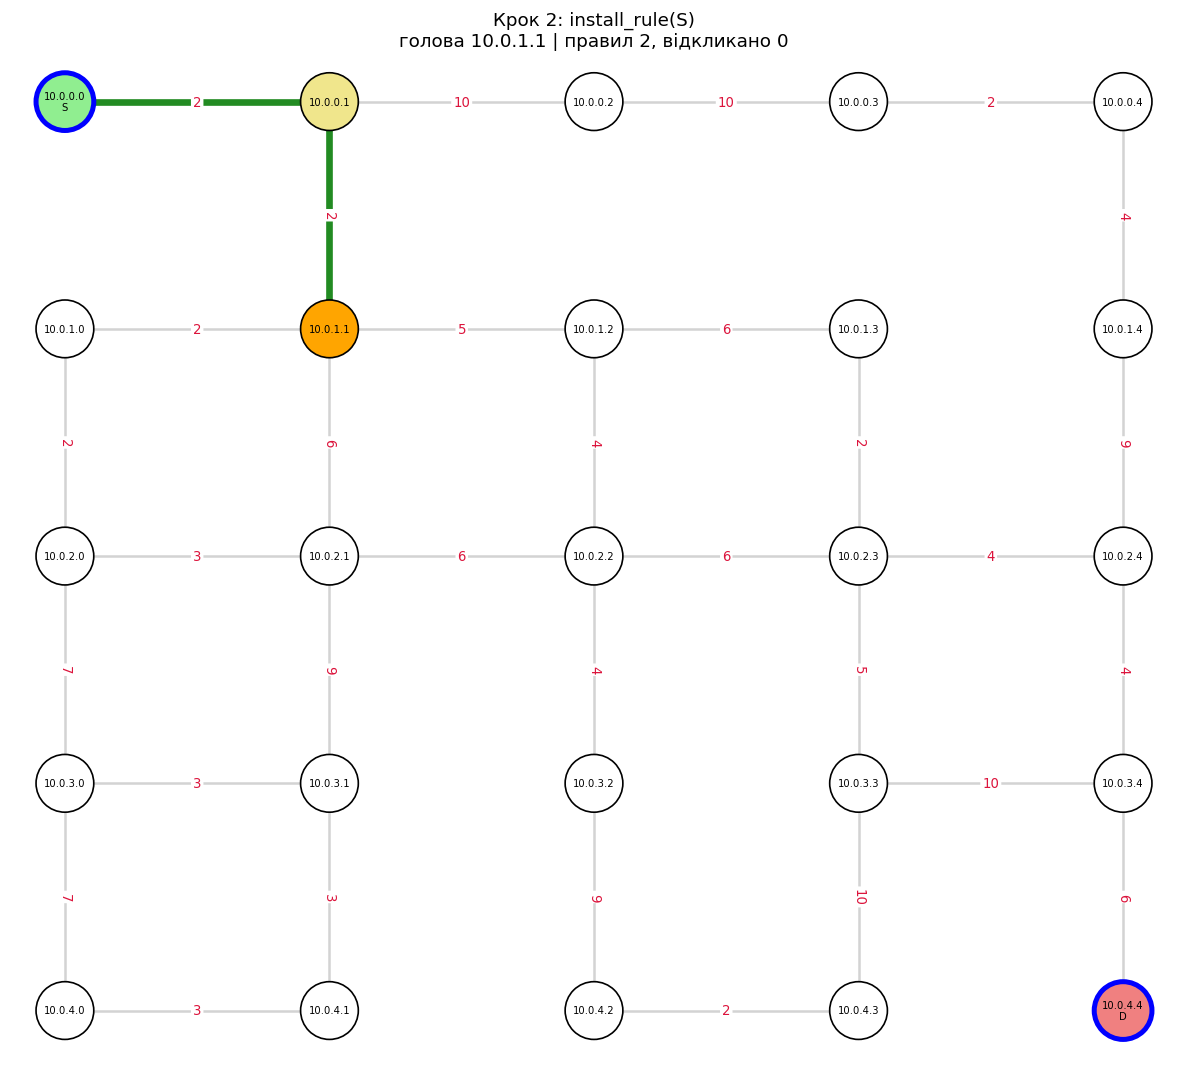

ГРАФ: figures/part2_s5_failure/steps\step_03.png


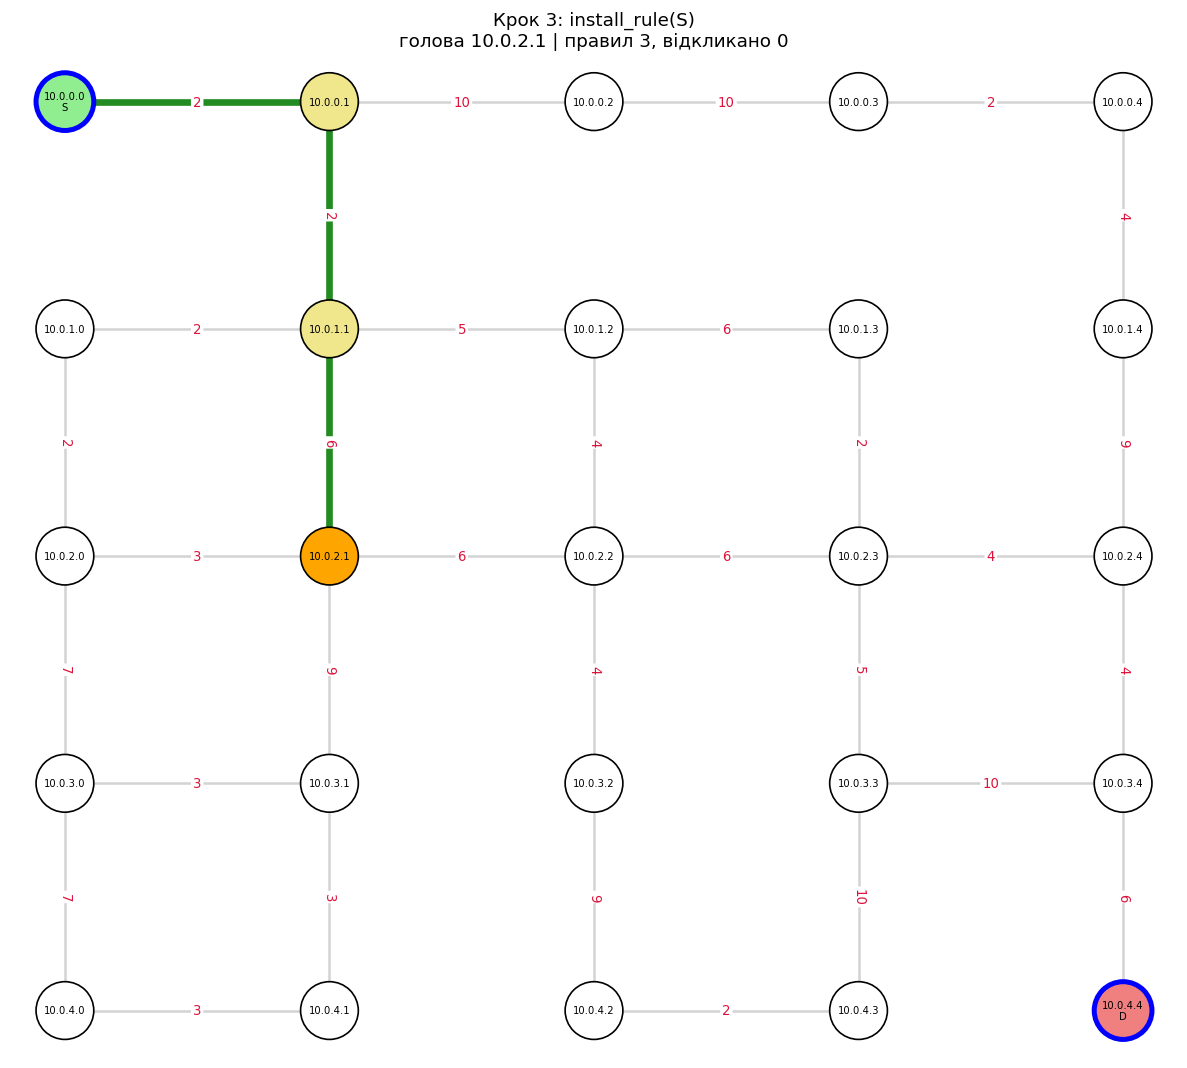

ГРАФ: figures/part2_s5_failure/steps\step_04.png


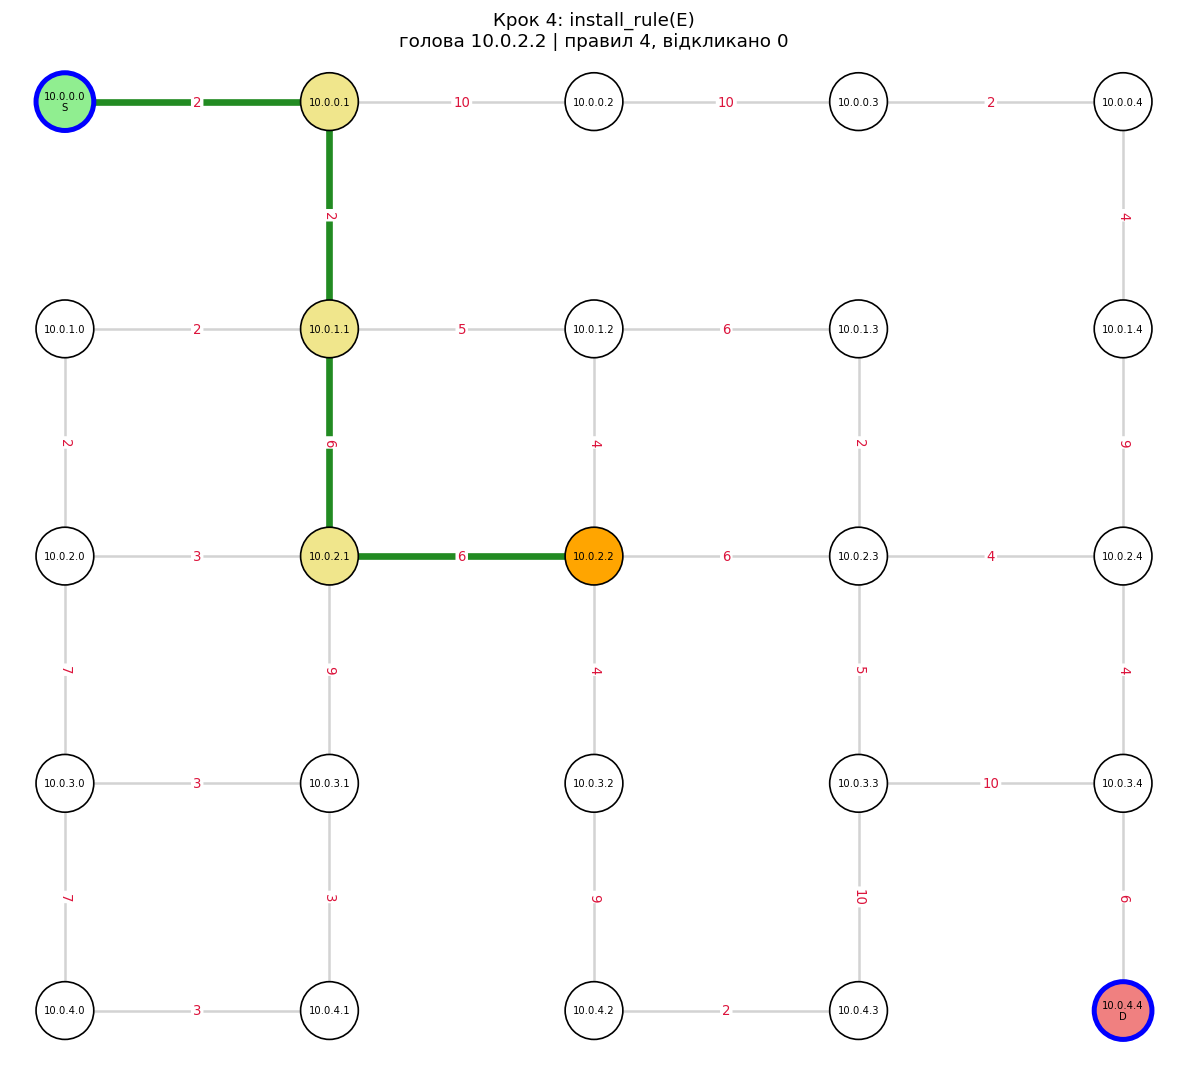

ГРАФ: figures/part2_s5_failure/steps\step_05.png


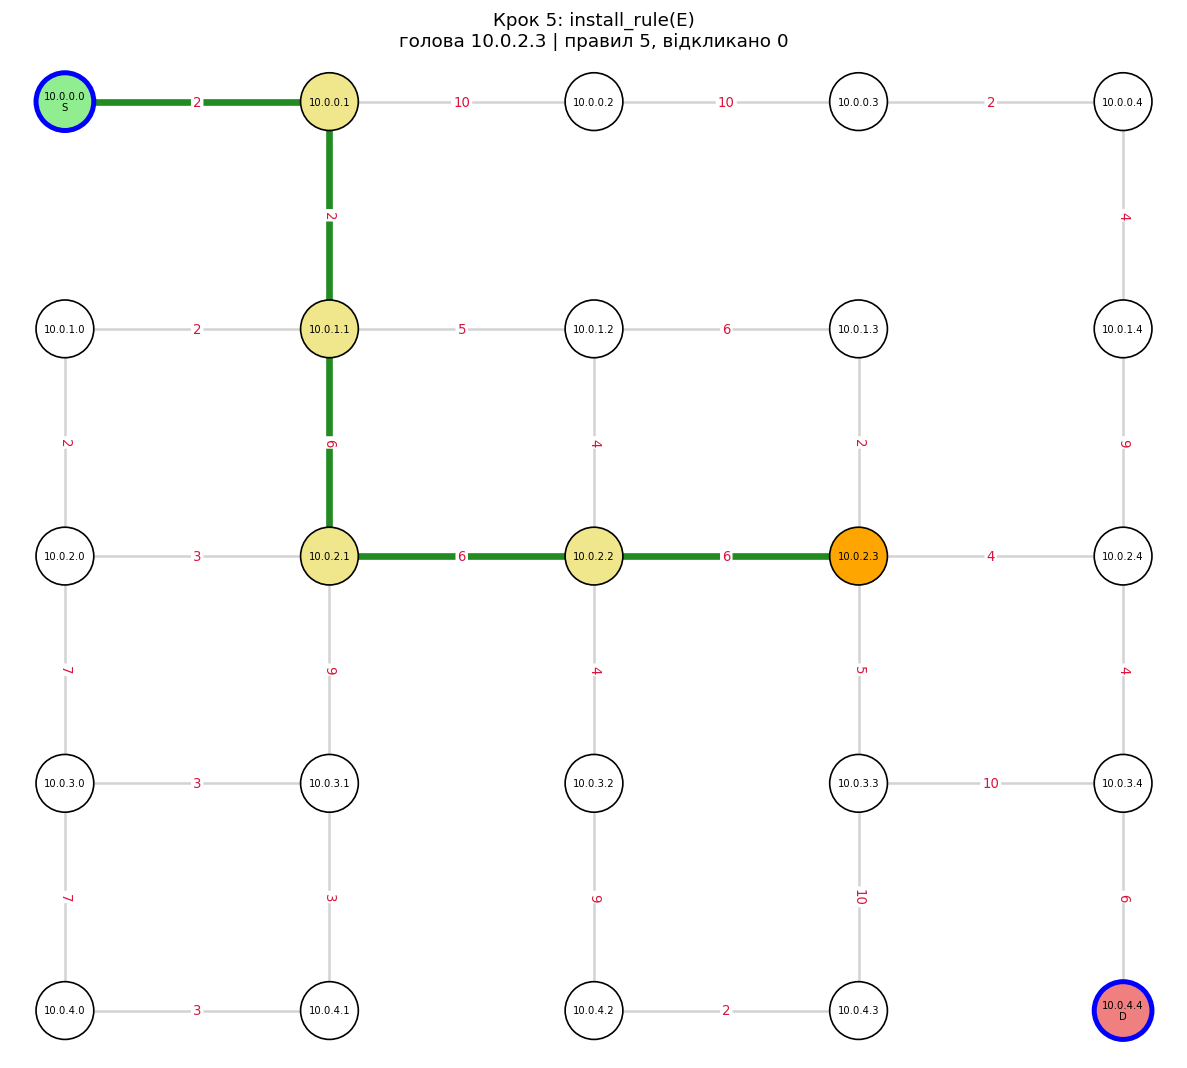

ГРАФ: figures/part2_s5_failure/steps\step_06.png


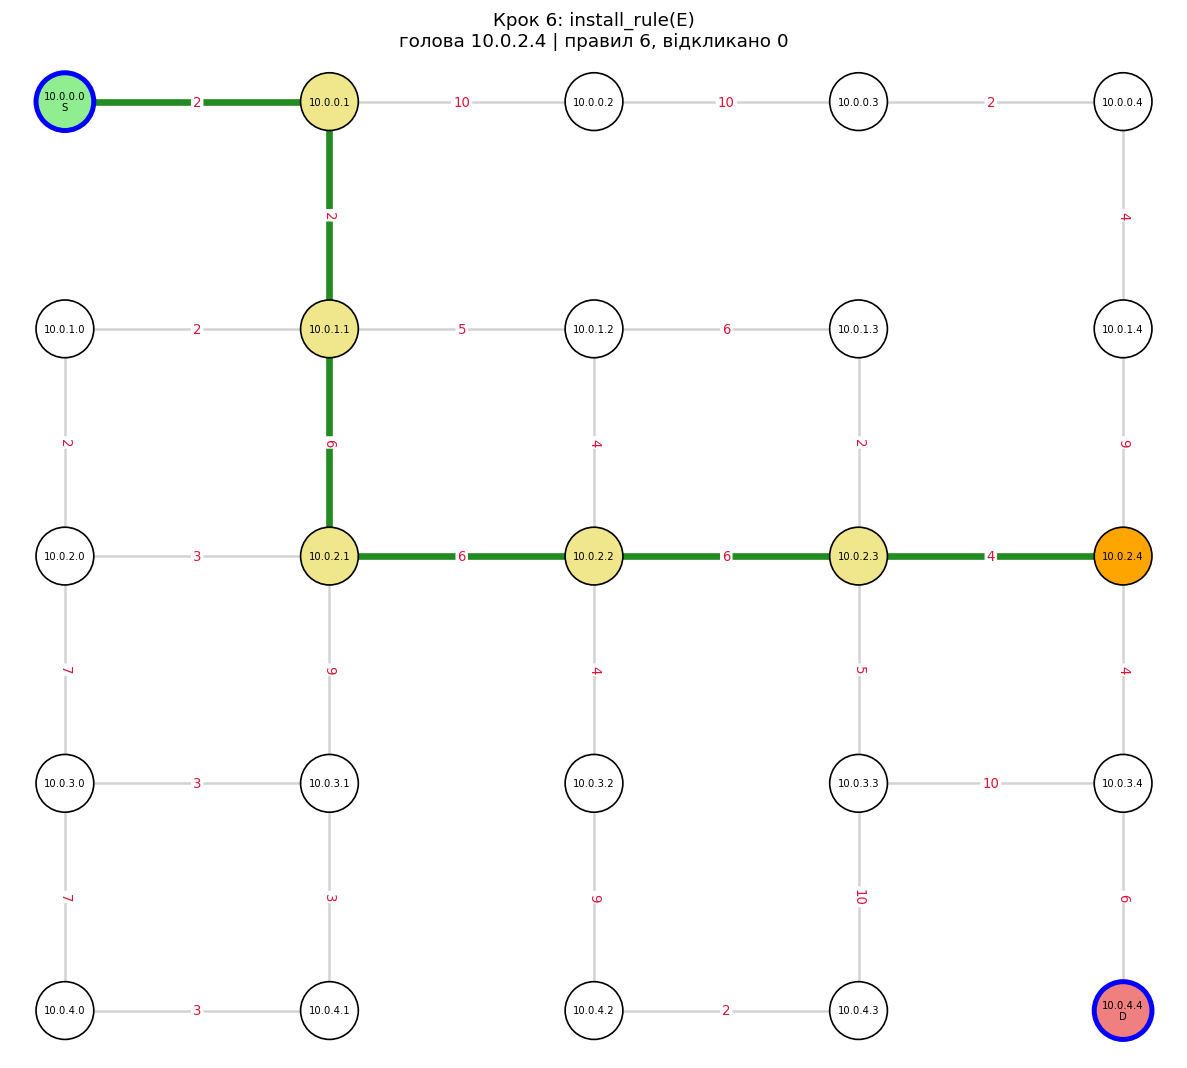

ГРАФ: figures/part2_s5_failure/steps\step_07.png


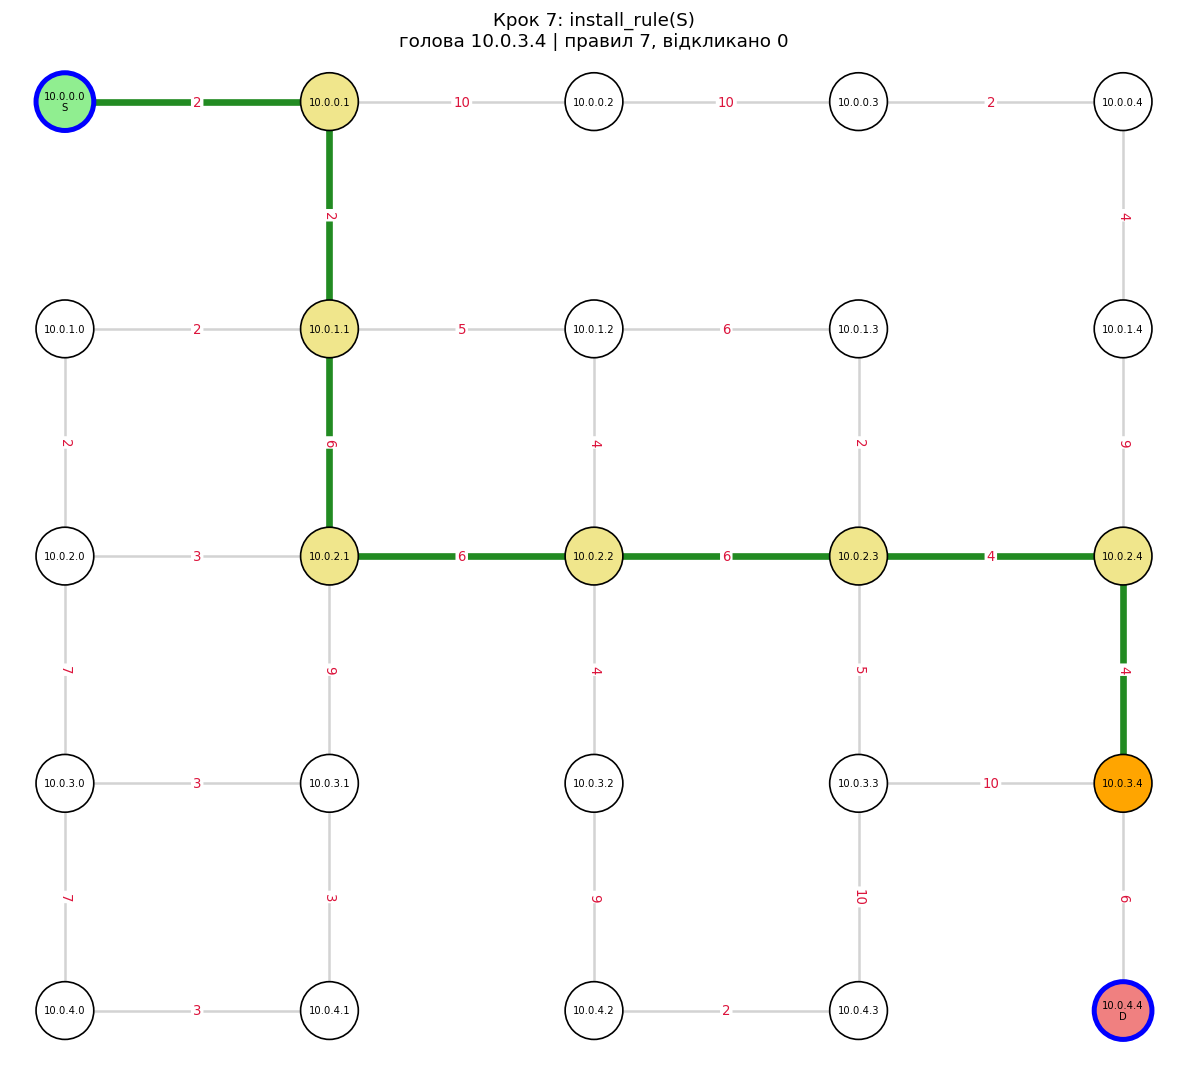

ГРАФ: figures/part2_s5_failure/steps\step_08.png


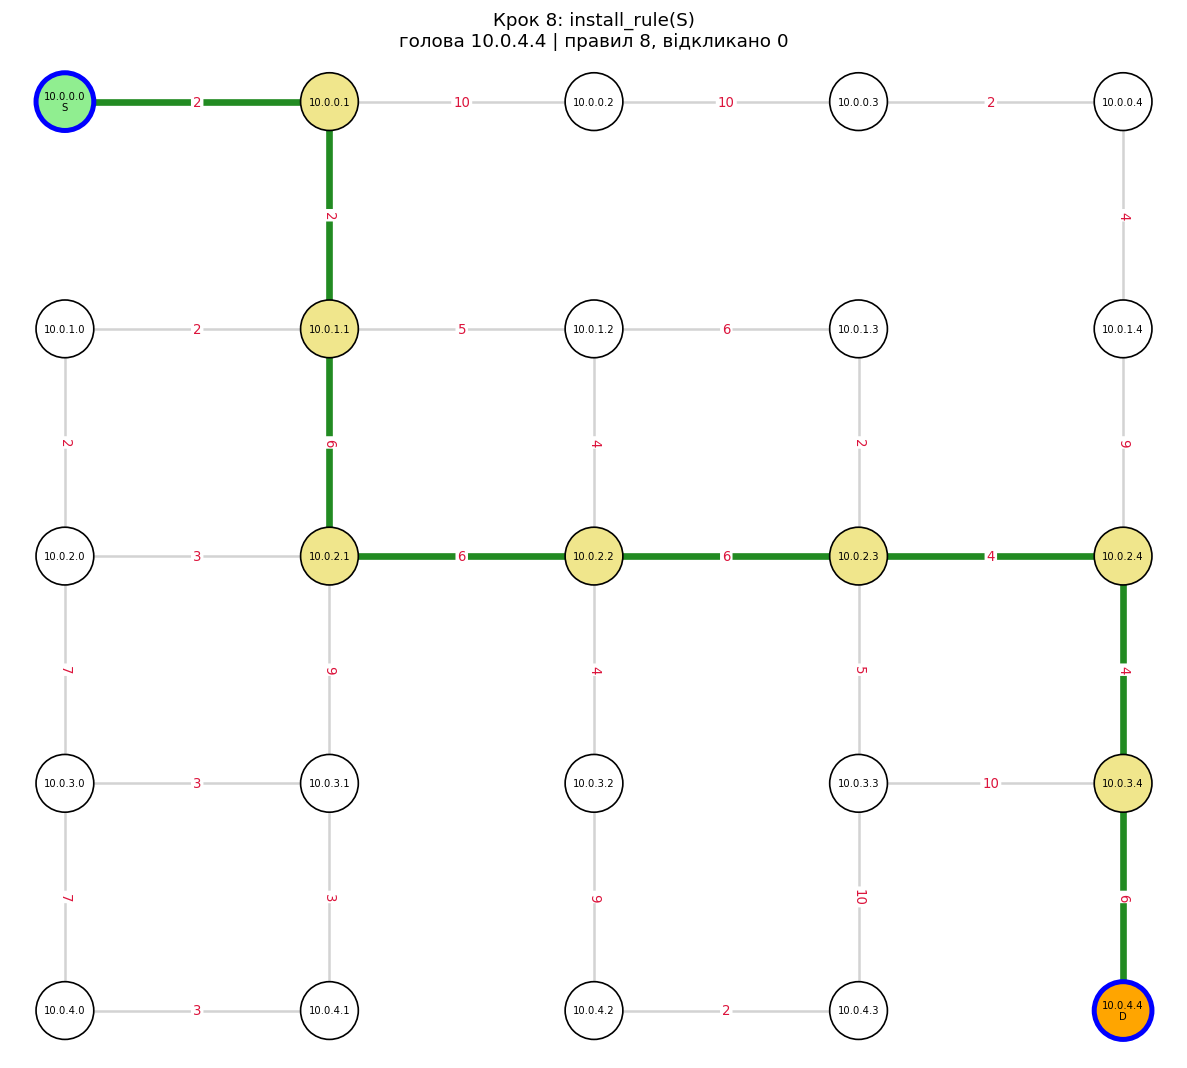

ФІНАЛЬНИЙ ШЛЯХ: figures/part2_s5_failure/final_path.png


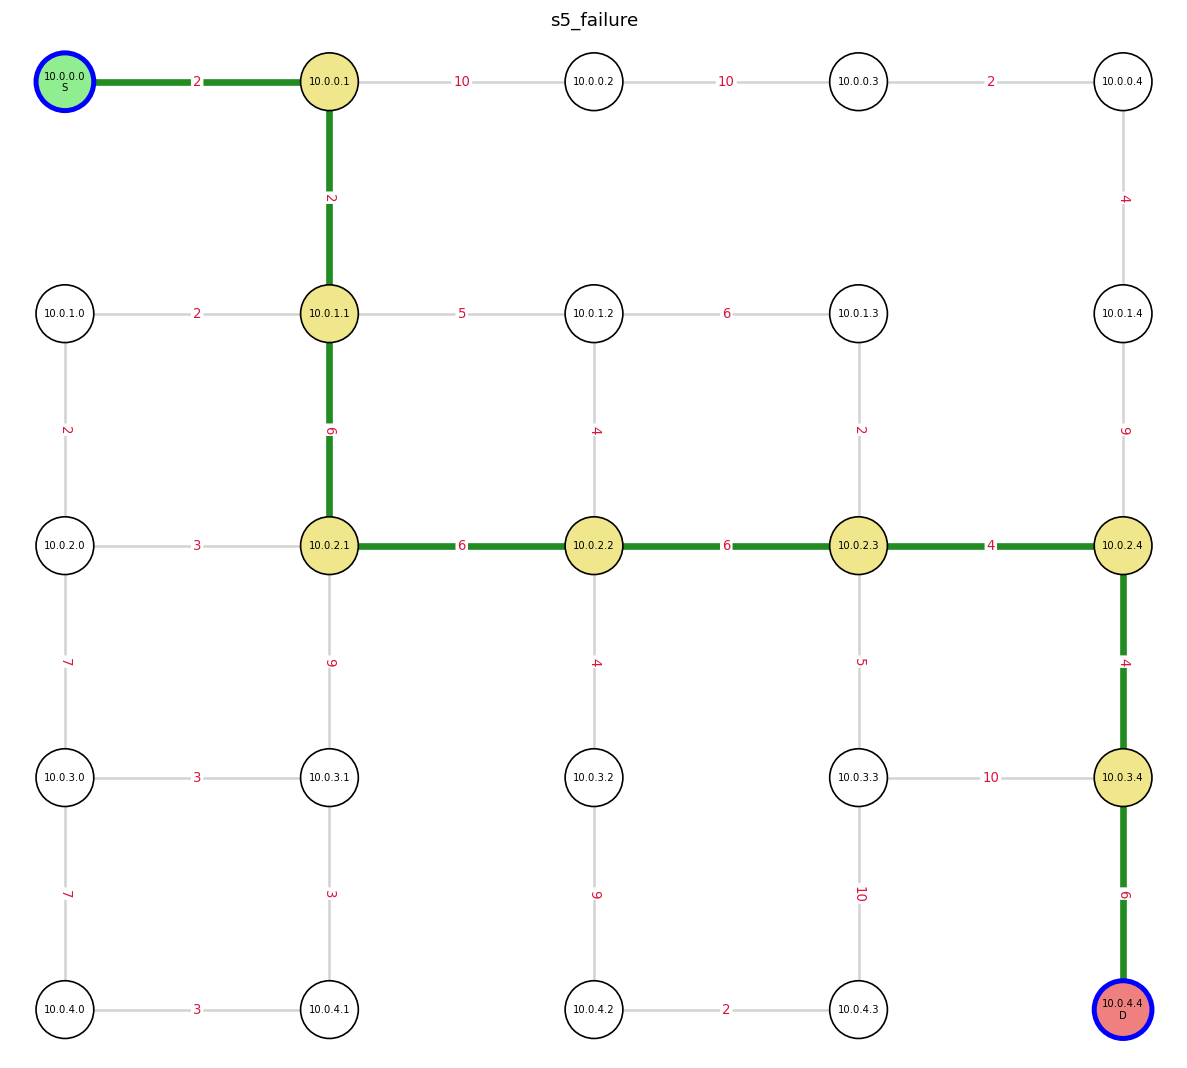

In [57]:
show_scenario(next(s for s in part2['scenarios'] if s['id'] == 's5_failure'))

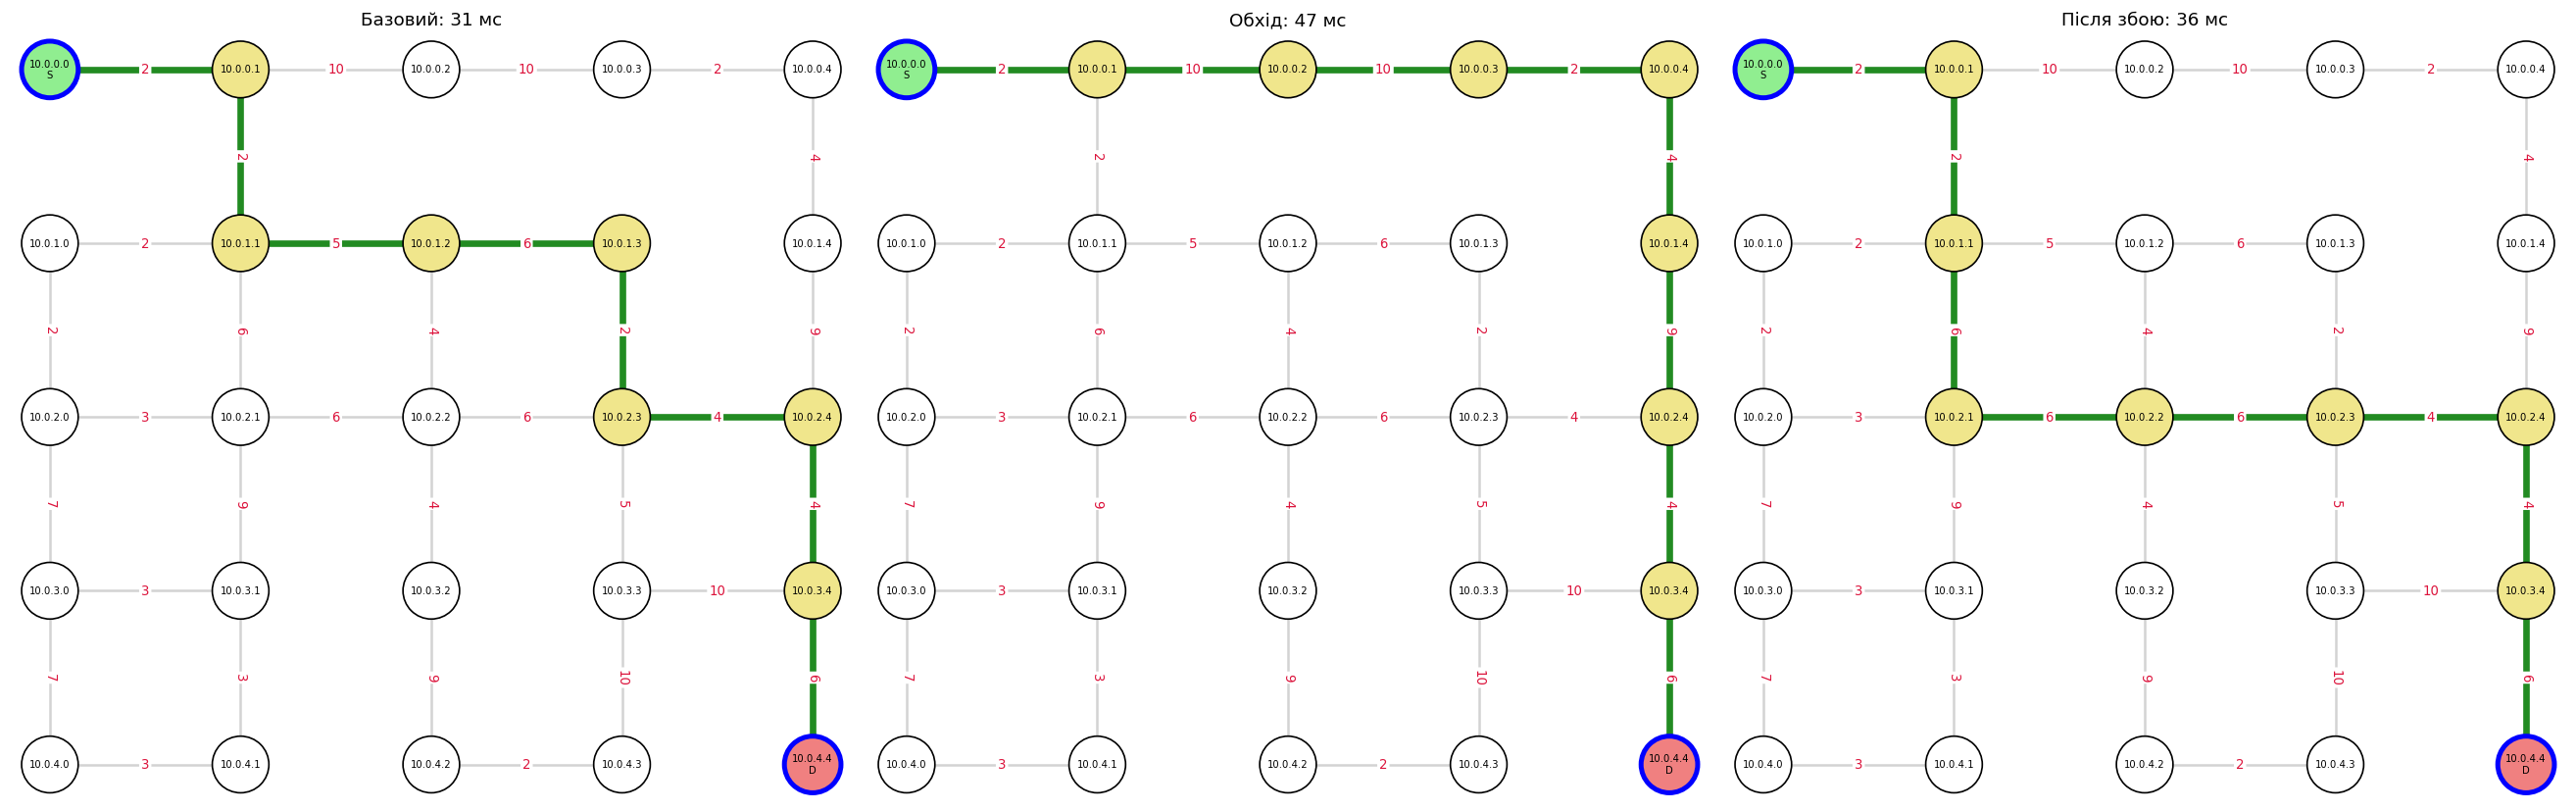

Порівняння шляхів: базовий / обхід / після збою


In [58]:
display(Image(filename='figures/paths.png'))
print('Порівняння шляхів: базовий / обхід / після збою')

## 5. Частина 3. Пояснення маршруту

Моделі передається журнал контролера; вона пояснює вибір шляху. Неточності в поясненні перевіряються **вручну** за фактами нижче (без автоматичного пошуку слів у відповіді).

In [59]:

LIVE_PART3 = False  # True = знову питати модель

def build_part3_journal(sc, topo):
    path_res = sc.get("last_path_result") or {}
    lines = [
        "ЖУРНАЛ РОБОТИ КОНТРОЛЕРА",
        f"Відправник: {topo['source']}, отримувач: {topo['destination']}",
        f"Встановлений шлях: {' -> '.join(path_res.get('path') or [])}",
        f"Затримка шляху: {path_res.get('delay_ms')} мс",
        f"Оптимальний шлях (Дейкстра без avoid): "
        f"{' -> '.join(path_res.get('optimal_path') or topo.get('opt_path') or [])}",
        f"Оптимальна затримка: {path_res.get('optimal_delay_ms', topo.get('opt_delay'))} мс",
        f"Час передачі: {path_res.get('transmission_ms')} мс",
        f"Вузьке місце: {path_res.get('bottleneck')} "
        f"({path_res.get('min_bandwidth_MBps')} МБ/с)",
        f"Avoid: {path_res.get('avoid')}",
        "Канали шляху:",
    ]
    for link in path_res.get("links") or []:
        lines.append(
            f"  {link['a']} — {link['b']}: delay={link['delay_ms']} мс, "
            f"BW={link['bandwidth_MBps']} МБ/с"
        )
    lines.append("Покроковий журнал встановлення правил:")
    for entry in path_res.get("journal") or []:
        lines.append(
            f"  крок {entry['step']}: install {entry['interface']} "
            f"{entry['from']} -> {entry['to']} "
            f"(delay={entry['delay_ms']} мс, BW={entry['bandwidth_MBps']} МБ/с)"
        )
    return "\n".join(lines)

def explain_from_part2(model=QUANTIZED_MODEL):
    part2_data = json.load(open("outputs/part2_scenarios.json", encoding="utf-8"))
    topo = part2_data["topology"]
    sc = next(
        (s for s in part2_data["scenarios"]
         if s["id"] == "s1_basic_path" and s.get("last_path_result")),
        None,
    ) or next(s for s in part2_data["scenarios"] if s.get("last_path_result"))
    journal = build_part3_journal(sc, topo)
    print(journal)
    env = sdn_env.NetworkEnvironment(sdn_env.generate_grid_graph(), SOURCE, DESTINATION)
    agent = LlmController(model, SdnToolbox(env), num_gpu=0, verbose=True)
    expl = agent.explain_route(journal)
    out = {
        "scenario_id": sc["id"], "journal": journal,
        "explanation": expl["explanation"], "model": model,
        "llm_time_s": expl.get("llm_time_s"),
        "prompt_tokens": expl.get("prompt_tokens"),
        "eval_tokens": expl.get("eval_tokens"),
        "facts": {
            "path": sc["last_path_result"].get("path"),
            "delay_ms": sc["last_path_result"].get("delay_ms"),
            "optimal_delay_ms": sc["last_path_result"].get("optimal_delay_ms"),
            "optimal_path": sc["last_path_result"].get("optimal_path"),
            "bottleneck": sc["last_path_result"].get("bottleneck"),
            "transmission_ms": sc["last_path_result"].get("transmission_ms"),
        },
    }
    with open("outputs/part3_explanation.json", "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False, indent=2)
    print("Збережено outputs/part3_explanation.json")
    return out

if LIVE_PART3:
    part3 = explain_from_part2()
else:
    part3 = json.load(open("outputs/part3_explanation.json", encoding="utf-8"))
    print("LIVE_PART3=False — завантажено outputs/part3_explanation.json")


LIVE_PART3=False — завантажено outputs/part3_explanation.json


In [60]:
print('ЖУРНАЛ, ПЕРЕДАНИЙ МОДЕЛІ:')
print(part3['journal'])
print('\nПОЯСНЕННЯ QWEN:')
print(part3['explanation'])
print('\nФАКТИ (для ручної перевірки пояснення):')
print(json.dumps(part3.get('facts') or {}, ensure_ascii=False, indent=2))

ЖУРНАЛ, ПЕРЕДАНИЙ МОДЕЛІ:
ЖУРНАЛ РОБОТИ КОНТРОЛЕРА
Відправник: 10.0.0.0, отримувач: 10.0.4.4
Встановлений шлях: 10.0.0.0 -> 10.0.0.1 -> 10.0.1.1 -> 10.0.1.2 -> 10.0.1.3 -> 10.0.2.3 -> 10.0.2.4 -> 10.0.3.4 -> 10.0.4.4
Затримка шляху: 31 мс
Оптимальний шлях (Дейкстра без avoid): 10.0.0.0 -> 10.0.0.1 -> 10.0.1.1 -> 10.0.1.2 -> 10.0.1.3 -> 10.0.2.3 -> 10.0.2.4 -> 10.0.3.4 -> 10.0.4.4
Оптимальна затримка: 31 мс
Час передачі: 2500.0 мс
Вузьке місце: 10.0.1.3 — 10.0.2.3 (400 МБ/с)
Avoid: []
Канали шляху:
  10.0.0.0 — 10.0.0.1: delay=2 мс, BW=800 МБ/с
  10.0.0.1 — 10.0.1.1: delay=2 мс, BW=600 МБ/с
  10.0.1.1 — 10.0.1.2: delay=5 мс, BW=900 МБ/с
  10.0.1.2 — 10.0.1.3: delay=6 мс, BW=700 МБ/с
  10.0.1.3 — 10.0.2.3: delay=2 мс, BW=400 МБ/с
  10.0.2.3 — 10.0.2.4: delay=4 мс, BW=700 МБ/с
  10.0.2.4 — 10.0.3.4: delay=4 мс, BW=900 МБ/с
  10.0.3.4 — 10.0.4.4: delay=6 мс, BW=500 МБ/с
Покроковий журнал встановлення правил:
  крок 1: install E 10.0.0.0 -> 10.0.0.1 (delay=2 мс, BW=800 МБ/с)
  крок 2: insta

## 6. Частина 4. Критична оцінка (≥10 запитів × 2 квантування)

Однакові запити на **Q4_K_M** і **Q8_0**. У таблиці — expected/actual tools, правильність, тип помилки; нижче — повний текст відповідей.

Додатково (за PDF): **5 пар UA↔EN** для порівняння мови запиту.

In [61]:

LIVE_PART4 = False  # True = повний прогін UA+EN через Ollama (дуже довго)

PART4_MODELS = [(QUANTIZED_MODEL, "Q4_K_M"), (Q8_MODEL, "Q8_0")]
PART4_QUERIES = [
    {"id": "q01", "query": "Проклади шлях від 10.0.0.0 до 10.0.4.4",
     "expected_tools": ["install_path"], "kind": "valid", "lang": "uk"},
    {"id": "q02", "query": "Проклади шлях від 10.0.0.0 до 10.0.4.4 в обхід 10.0.1.1 та 10.0.3.2",
     "expected_tools": ["install_path"], "kind": "valid_avoid", "lang": "uk"},
    {"id": "q03", "query": "Проклади шлях до вузла 10.0.9.9",
     "expected_tools": ["install_path"], "kind": "impossible_dst", "lang": "uk"},
    {"id": "q04", "query": "Який зараз стан потоку?",
     "expected_tools": ["get_flow_state"], "kind": "valid_state", "lang": "uk"},
    {"id": "q05", "query": "Покажи телеметрію вузла 10.0.2.2: затримки і пропускну здатність",
     "expected_tools": ["get_link_stats"], "kind": "valid_stats", "lang": "uk"},
    {"id": "q06", "query": "Покажи топологію мережі з бази знань",
     "expected_tools": ["get_topology"], "kind": "valid_topo", "lang": "uk"},
    {"id": "q07", "query": "Канал між 10.0.0.1 і 10.0.0.2 вийшов з ладу",
     "expected_tools": ["simulate_link_failure"], "kind": "valid_failure", "lang": "uk"},
    {"id": "q08", "query": "Проклади якийсь хороший шлях якомога швидше",
     "expected_tools": ["install_path"], "kind": "ambiguous", "lang": "uk"},
    {"id": "q09", "query": (
        "Проклади шлях від 10.0.0.0 до 10.0.4.4 в обхід усіх вузлів "
        "10.0.1.0, 10.0.1.1, 10.0.1.2, 10.0.1.3, 10.0.1.4, "
        "10.0.2.0, 10.0.2.1, 10.0.2.2, 10.0.2.3, 10.0.2.4, "
        "10.0.3.0, 10.0.3.1, 10.0.3.2, 10.0.3.3, 10.0.3.4"),
     "expected_tools": ["install_path"], "kind": "impossible_avoid", "lang": "uk"},
    {"id": "q10", "query": "Встанови правило на схід і одразу скасуй його",
     "expected_tools": ["install_rule"], "kind": "valid_rule", "lang": "uk"},
    {"id": "q11", "query": "Скільки триватиме передача потоку і де вузьке місце?",
     "expected_tools": ["get_flow_state", "install_path"], "kind": "needs_path_or_state", "lang": "uk"},
]
PART4_EN_QUERIES = [
    {"id": "q01_en", "pair_id": "q01", "query": "Install a path from 10.0.0.0 to 10.0.4.4",
     "expected_tools": ["install_path"], "kind": "valid", "lang": "en"},
    {"id": "q03_en", "pair_id": "q03", "query": "Install a path to node 10.0.9.9",
     "expected_tools": ["install_path"], "kind": "impossible_dst", "lang": "en"},
    {"id": "q04_en", "pair_id": "q04", "query": "What is the current flow state?",
     "expected_tools": ["get_flow_state"], "kind": "valid_state", "lang": "en"},
    {"id": "q05_en", "pair_id": "q05",
     "query": "Show telemetry for node 10.0.2.2: delays and bandwidth",
     "expected_tools": ["get_link_stats"], "kind": "valid_stats", "lang": "en"},
    {"id": "q08_en", "pair_id": "q08", "query": "Install some good path as fast as possible",
     "expected_tools": ["install_path"], "kind": "ambiguous", "lang": "en"},
]

def part4_unload(model):
    try:
        ollama.chat(model=model, messages=[{"role": "user", "content": " "}],
                    options={"num_gpu": 0, "num_predict": 1}, keep_alive=0)
    except Exception:
        pass

def part4_actual_tools(log):
    return [e["tool"] for e in log if e.get("tool") and not e["tool"].startswith("(")]

def part4_mentions_refusal(answer):
    a = answer.lower()
    keys = ("не існу", "неможлив", "не вда", "немає", "помилк",
            "does not exist", "doesn't exist", "impossible", "cannot", "can't",
            "unable", "not found", "no such", "error", "failed", "fail")
    return any(x in a for x in keys)

def part4_classify(row, res):
    tools = part4_actual_tools(res.get("log") or [])
    expected, kind = row["expected_tools"], row["kind"]
    answer = (res.get("answer") or "").lower()
    errors = []
    has_expected = any(t in tools for t in expected)
    if kind == "impossible_dst":
        ok_refuse = part4_mentions_refusal(answer) or any(
            e.get("status") == "error" for e in res.get("log") or [])
        raw = res.get("answer") or ""
        halluc = False
        if "10.0.9.9" in raw:
            idx = raw.lower().find("10.0.9.9")
            prefix = raw.lower()[: idx + 1]
            if any(w in raw.lower() for w in ("встановлено", "installed", "success", "прокладено")) \
               and not any(w in prefix[-40:] for w in ("не ", "not ", "no ", "cannot", "can't", "unable", "fail")):
                halluc = True
        correct = ok_refuse and not halluc
        if not has_expected and not ok_refuse: errors.append("wrong_tool")
        if halluc: errors.append("hallucinated_result")
        if not correct and not errors: errors.append("incorrect_answer")
        return correct, errors
    if kind == "impossible_avoid":
        correct = part4_mentions_refusal(answer) or any(
            e.get("status") == "error" for e in res.get("log") or [])
        if not correct: errors.append("incorrect_answer")
        return correct, errors
    if kind == "ambiguous":
        clarify = ("уточн" in answer or "clarif" in answer
                   or "which" in answer or "specify" in answer)
        correct = has_expected or clarify or "10.0.0.0" in (res.get("answer") or "")
        if not correct: errors.append("wrong_tool")
        return correct, errors
    if not has_expected:
        return False, ["wrong_tool"]
    if kind in ("valid_state", "valid_stats", "valid_topo") and "install_path" in tools:
        errors.append("extra_call")
    for e in res.get("log") or []:
        if e.get("status") == "error" and kind.startswith("valid"):
            if kind == "valid_failure" and part4_mentions_refusal(answer):
                continue
            errors.append("tool_error")
    correct = has_expected and "hallucinated_result" not in errors
    if kind.startswith("valid") and not (res.get("answer") or "").strip() and not tools:
        correct = False
        errors.append("incorrect_answer")
    return correct, list(dict.fromkeys(errors))

def part4_run_one(model, graph, row):
    env = sdn_env.NetworkEnvironment(graph, SOURCE, DESTINATION)
    agent = LlmController(model, SdnToolbox(env), num_gpu=0, max_steps=24, verbose=True)
    print(f"\n--- {row['id']} | {model} | {row.get('lang','?')} ---")
    print(row["query"])
    t0 = time.perf_counter()
    res = agent.run(row["query"])
    wall = time.perf_counter() - t0
    correct, errors = part4_classify(row, res)
    out = {
        "id": row["id"], "query": row["query"], "kind": row["kind"],
        "lang": row.get("lang", "uk"),
        "expected_tools": row["expected_tools"],
        "actual_tools": part4_actual_tools(res.get("log") or []),
        "answer": res.get("answer"), "correct": correct, "error_types": errors,
        "log": res.get("log"), "steps": res.get("steps"),
        "tool_calls": res.get("tool_calls"),
        "llm_time_s": res.get("llm_time_s"), "wall_time_s": wall,
    }
    if row.get("pair_id"):
        out["pair_id"] = row["pair_id"]
    return out

def part4_run_set(queries, graph):
    models = {}
    for model, label in PART4_MODELS:
        print(f"\n===== {model} ({label}) | {len(queries)} =====")
        rows = [part4_run_one(model, graph, q) for q in queries]
        part4_unload(model)
        n_ok = sum(1 for r in rows if r["correct"])
        models[model] = {
            "label": label, "rows": rows, "correct_count": n_ok,
            "total": len(rows), "accuracy": round(n_ok / len(rows), 3),
            "model": model,
        }
        print(f"Точність {label}: {n_ok}/{len(rows)}")
    return models

def part4_language_compare(uk_models, en_models):
    pairs = []
    for en_q in PART4_EN_QUERIES:
        pair_id = en_q["pair_id"]
        entry = {
            "pair_id": pair_id, "kind": en_q["kind"],
            "uk_query": next(q["query"] for q in PART4_QUERIES if q["id"] == pair_id),
            "en_query": en_q["query"], "by_model": {},
        }
        for model, _label in PART4_MODELS:
            uk = {r["id"]: r for r in uk_models[model]["rows"]}.get(pair_id)
            en = {r["id"]: r for r in en_models[model]["rows"]}.get(en_q["id"])
            if not uk or not en:
                continue
            entry["by_model"][model] = {
                "label": uk_models[model]["label"],
                "uk_correct": uk["correct"], "en_correct": en["correct"],
                "uk_tools": uk["actual_tools"], "en_tools": en["actual_tools"],
                "uk_errors": uk["error_types"], "en_errors": en["error_types"],
                "same_outcome": uk["correct"] == en["correct"],
            }
        pairs.append(entry)
    summary = {}
    for model, label in PART4_MODELS:
        uk_ok = en_ok = both = n = 0
        for p in pairs:
            m = p["by_model"].get(model)
            if not m: continue
            n += 1
            uk_ok += int(m["uk_correct"]); en_ok += int(m["en_correct"])
            both += int(m["same_outcome"])
        summary[model] = {
            "label": label, "pairs": n,
            "uk_correct": uk_ok, "en_correct": en_ok, "same_outcome": both,
            "uk_accuracy": round(uk_ok / n, 3) if n else 0.0,
            "en_accuracy": round(en_ok / n, 3) if n else 0.0,
            "agreement": round(both / n, 3) if n else 0.0,
        }
    return {"pairs": pairs, "summary": summary}

def run_part4_live():
    graph = sdn_env.generate_grid_graph()
    out = {
        "models": part4_run_set(PART4_QUERIES, graph),
        "queries": [q["query"] for q in PART4_QUERIES],
    }
    en_models = part4_run_set(PART4_EN_QUERIES, graph)
    out["models_en"] = en_models
    out["queries_en"] = [q["query"] for q in PART4_EN_QUERIES]
    out["language_compare"] = part4_language_compare(out["models"], en_models)
    with open("outputs/part4_eval.json", "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False, indent=2)
    print("Збережено outputs/part4_eval.json")
    return out

if LIVE_PART4:
    part4 = run_part4_live()
else:
    part4 = json.load(open("outputs/part4_eval.json", encoding="utf-8"))
    print("LIVE_PART4=False — завантажено outputs/part4_eval.json")

for model, block in part4["models"].items():
    print(f"  UA {block['label']}: {block['correct_count']}/{block['total']} = {block['accuracy']}")
for model, block in (part4.get("models_en") or {}).items():
    print(f"  EN {block['label']}: {block['correct_count']}/{block['total']} = {block['accuracy']}")
for model, s in (part4.get("language_compare") or {}).get("summary", {}).items():
    print(f"  UA↔EN {s['label']}: uk={s['uk_accuracy']} en={s['en_accuracy']} agreement={s['agreement']}")


LIVE_PART4=False — завантажено outputs/part4_eval.json
  UA Q4_K_M: 11/11 = 1.0
  UA Q8_0: 11/11 = 1.0
  EN Q4_K_M: 5/5 = 1.0
  EN Q8_0: 5/5 = 1.0
  UA↔EN Q4_K_M: uk=1.0 en=1.0 agreement=1.0
  UA↔EN Q8_0: uk=1.0 en=1.0 agreement=1.0


In [62]:
for model, block in part4['models'].items():
    print(f"\n=== {block['label']} ({model}) accuracy={block['accuracy']} ===")
    rows = [{
        'id': r['id'],
        'запит': r['query'][:50],
        'очікувані': ','.join(r['expected_tools']),
        'фактичні': ','.join(r['actual_tools']),
        'OK': r['correct'],
        'помилки': ','.join(r['error_types']) or '—',
    } for r in block['rows']]
    display(pd.DataFrame(rows))


=== Q4_K_M (qwen2.5:3b) accuracy=1.0 ===


,id,запит,очікувані,фактичні,OK,помилки
0,q01,Проклади шлях від 10.0.0.0 до 10.0.4.4,install_path,install_path,True,—
1,q02,Проклади шлях від 10.0.0.0 до 10.0.4.4 в обхід...,install_path,install_path,True,—
2,q03,Проклади шлях до вузла 10.0.9.9,install_path,install_path,True,—
3,q04,Який зараз стан потоку?,get_flow_state,get_flow_state,True,—
4,q05,Покажи телеметрію вузла 10.0.2.2: затримки і п...,get_link_stats,get_link_stats,True,—
5,q06,Покажи топологію мережі з бази знань,get_topology,get_topology,True,—
6,q07,Канал між 10.0.0.1 і 10.0.0.2 вийшов з ладу,simulate_link_failure,"simulate_link_failure,install_path",True,—
7,q08,Проклади якийсь хороший шлях якомога швидше,install_path,install_path,True,—
8,q09,Проклади шлях від 10.0.0.0 до 10.0.4.4 в обхід...,install_path,install_path,True,—
9,q10,Встанови правило на схід і одразу скасуй його,install_rule,"install_rule,install_rule,install_rule",True,tool_error



=== Q8_0 (qwen2.5:3b-instruct-q8_0) accuracy=1.0 ===


,id,запит,очікувані,фактичні,OK,помилки
0,q01,Проклади шлях від 10.0.0.0 до 10.0.4.4,install_path,install_path,True,—
1,q02,Проклади шлях від 10.0.0.0 до 10.0.4.4 в обхід...,install_path,install_path,True,—
2,q03,Проклади шлях до вузла 10.0.9.9,install_path,install_path,True,—
3,q04,Який зараз стан потоку?,get_flow_state,get_flow_state,True,—
4,q05,Покажи телеметрію вузла 10.0.2.2: затримки і п...,get_link_stats,get_link_stats,True,—
5,q06,Покажи топологію мережі з бази знань,get_topology,get_topology,True,—
6,q07,Канал між 10.0.0.1 і 10.0.0.2 вийшов з ладу,simulate_link_failure,"simulate_link_failure,install_path",True,—
7,q08,Проклади якийсь хороший шлях якомога швидше,install_path,get_topology,True,—
8,q09,Проклади шлях від 10.0.0.0 до 10.0.4.4 в обхід...,install_path,install_path,True,—
9,q10,Встанови правило на схід і одразу скасуй його,install_rule,"install_rule,install_rule",True,tool_error


### 6.1. Повні відповіді моделі (tools + текст) для обох квантувань (UA)

In [63]:
def show_part4_details(part4, key='models'):
    for model, block in (part4.get(key) or {}).items():
        print('=' * 78)
        print(f"МОДЕЛЬ: {block['label']} ({model}) {block['correct_count']}/{block['total']}")
        print('=' * 78)
        for r in block['rows']:
            print(f"\n### {r['id']} | lang={r.get('lang','uk')} | correct={r['correct']} | errors={r['error_types'] or '—'}")
            print('Запит:', r['query'])
            print('Очікувані:', ', '.join(r['expected_tools']))
            print('Фактичні:', ', '.join(r['actual_tools']))
            print('Журнал:')
            for e in r.get('log') or []:
                tool = e.get('tool') or ''
                if e.get('status') == 'answer' or tool == '(відповідь)':
                    continue
                if tool.startswith('('):
                    continue
                print(f"  - {tool}({json.dumps(e.get('arguments') or {}, ensure_ascii=False)}) → {e.get('status')}")
            print('Текст відповіді Qwen:')
            print(textwrap.fill(r.get('answer') or '(порожньо)', width=96))
            print('-' * 60)

show_part4_details(part4, 'models')

МОДЕЛЬ: Q4_K_M (qwen2.5:3b) 11/11

### q01 | lang=uk | correct=True | errors=—
Запит: Проклади шлях від 10.0.0.0 до 10.0.4.4
Очікувані: install_path
Фактичні: install_path
Журнал:
  - install_path({"src": "10.0.0.0", "dst": "10.0.4.4"}) → ok
Текст відповіді Qwen:
Шлях від 10.0.0.0 до 10.0.4.4 встановлено за наступним шляхом: 10.0.0.0 → 10.0.0.1 → 10.0.1.1 →
10.0.1.2 → 10.0.1.3 → 10.0.2.3 → 10.0.2.4 → 10.0.3.4 → 10.0.4.4  Затримки каналів:  - 10.0.0.0 —
10.0.0.1: 2 мс - 10.0.0.1 — 10.0.1.1: 2 мс - 10.0.1.1 — 10.0.1.2: 5 мс - 10.0.1.2 — 10.0.1.3: 6
мс - 10.0.1.3 — 10.0.2.3: 2 мс - 10.0.2.3 — 10.0.2.4: 4 мс - 10.0.2.4 — 10.0.3.4: 4 мс -
10.0.3.4 — 10.0.4.4: 6 мс  Пропускна здатність каналів:  - 2 мс — 800 МБ/с - 2 мс — 600 МБ/с - 5
мс — 900 МБ/с - 6 мс — 700 МБ/с - 2 мс — 400 МБ/с - 4 мс — 700 МБ/с - 4 мс — 900 МБ/с - 6 мс —
500 МБ/с  Вузьке місце на шляху: 10.0.1.3 — 10.0.2.3  Встановлено 8 правил.   Час передачі
потоку: 2500 мс  Встановлено повний шлях за збіжністю.
--------------------

### 6.2. Порівняння української та англійської (5 пар)

Ті самі наміри англійською: `q01`, `q03`, `q04`, `q05`, `q08`. Оцінюємо expected/actual tools і правильність відповіді.

In [64]:
lc = part4.get('language_compare') or {}
rows = []
for p in lc.get('pairs') or []:
    for model, m in (p.get('by_model') or {}).items():
        rows.append({
            'pair': p['pair_id'],
            'model': m['label'],
            'uk': (p['uk_query'][:40] + '…') if len(p['uk_query']) > 40 else p['uk_query'],
            'en': (p['en_query'][:40] + '…') if len(p['en_query']) > 40 else p['en_query'],
            'uk_OK': m['uk_correct'],
            'en_OK': m['en_correct'],
            'same': m['same_outcome'],
            'uk_tools': ','.join(m['uk_tools']),
            'en_tools': ','.join(m['en_tools']),
        })
display(pd.DataFrame(rows))
print('\nПідсумок:')
for model, s in (lc.get('summary') or {}).items():
    print(f"  {s['label']}: uk={s['uk_accuracy']} en={s['en_accuracy']} agreement={s['agreement']}")

,pair,model,uk,en,uk_OK,en_OK,same,uk_tools,en_tools
0,q01,Q4_K_M,Проклади шлях від 10.0.0.0 до 10.0.4.4,Install a path from 10.0.0.0 to 10.0.4.4,True,True,True,install_path,install_path
1,q01,Q8_0,Проклади шлях від 10.0.0.0 до 10.0.4.4,Install a path from 10.0.0.0 to 10.0.4.4,True,True,True,install_path,install_path
2,q03,Q4_K_M,Проклади шлях до вузла 10.0.9.9,Install a path to node 10.0.9.9,True,True,True,install_path,install_path
3,q03,Q8_0,Проклади шлях до вузла 10.0.9.9,Install a path to node 10.0.9.9,True,True,True,install_path,install_path
4,q04,Q4_K_M,Який зараз стан потоку?,What is the current flow state?,True,True,True,get_flow_state,get_flow_state
5,q04,Q8_0,Який зараз стан потоку?,What is the current flow state?,True,True,True,get_flow_state,get_flow_state
6,q05,Q4_K_M,Покажи телеметрію вузла 10.0.2.2: затрим…,Show telemetry for node 10.0.2.2: delays…,True,True,True,get_link_stats,get_link_stats
7,q05,Q8_0,Покажи телеметрію вузла 10.0.2.2: затрим…,Show telemetry for node 10.0.2.2: delays…,True,True,True,get_link_stats,get_link_stats
8,q08,Q4_K_M,Проклади якийсь хороший шлях якомога шви…,Install some good path as fast as possib…,True,True,True,install_path,install_path
9,q08,Q8_0,Проклади якийсь хороший шлях якомога шви…,Install some good path as fast as possib…,True,True,True,get_topology,"get_topology,install_path"



Підсумок:
  Q4_K_M: uk=1.0 en=1.0 agreement=1.0
  Q8_0: uk=1.0 en=1.0 agreement=1.0


### 6.3. Повні відповіді на англійські запити

In [23]:
show_part4_details(part4, 'models_en')

МОДЕЛЬ: Q4_K_M (qwen2.5:3b) — 5/5 (accuracy=1.0)

### q01_en | lang=en | correct=True | errors=—
Запит: Install a path from 10.0.0.0 to 10.0.4.4
Очікувані tools: install_path
Фактичні tools:  install_path
Журнал викликів:
  - install_path({"src": "10.0.0.0", "dst": "10.0.4.4"}) → ok
  [відповідь моделі]
Текст відповіді Qwen:
The path from 10.0.0.0 to 10.0.4.4 has been installed successfully. The path is as follows:
10.0.0.0 -> 10.0.0.1 -> 10.0.1.1 -> 10.0.1.2 -> 10.0.1.3 -> 10.0.2.3 -> 10.0.2.4 -> 10.0.3.4 ->
10.0.4.4

The delay is 31 ms, and the transmission time is 2.500 seconds. The total delay is 2.531 ms. The
bottleneck is between 10.0.1.3 and 10.0.2.3. The minimum bandwidth along the path is 400 MBps.
The links and their respective delays and bandwidths are as follows:
- 10.0.0.0-10.0.0.1: 2 ms/800 MBps
- 10.0.0.1-10.0.1.1: 2 ms/600 MBps
- 10.0.1.1-10.0.1.2: 5 ms/900 MBps
- 10.0.1.2-10.0.1.3: 6 ms/700 MBps
- 10.0.1.3-10.0.2.3: 2 ms/400 MBps
- 10.0.2.3-10.0.2.4: 4 ms/700 MBps
- 10

## 7. Висновок

- **Частина 1:** квантування зменшує розмір/RAM і прискорює генерацію на CPU.
- **Частина 2:** LLM — NL-інтерфейс; шлях ставить `install_path` / knowledge-controller.
- **Частина 3:** текстове пояснення перевіряється вручну за фактами журналу.
- **Частина 4:** Q4_K_M **1.0**, Q8_0 **1.0** на 11 UA-запитах; EN: Q4_K_M EN **1.0**; Q8_0 EN **1.0**; UA↔EN: Q4_K_M згода **1.0**; Q8_0 згода **1.0**.

LLM доцільно доручати розбір наміру й вибір tools; обчислення шляху та стан мережі — детермінованому контролеру.